# STCWT-Functional-Transformer **v29** (geoestadística funcional actualizada: `Geoestadistica_Funcional_EEG_v23.1`)
> Antes **v28** — rigor/robustez/interpretabilidad sobre v21. Antes v21 — integración con geo v12.

**Qué cambia respecto a v28 (solo la capa geoestadística-funcional; arquitectura y validación intactas):**

1. **Distancias great-circle (3-D), no proyección 2-D.** La distancia entre electrodos que alimenta el
   trace-variograma funcional (y por tanto `Bspatial`) pasa de la proyección topográfica 2-D hecha a mano
   (v12-v28) a la **distancia de círculo máximo sobre la esfera ajustada a la plantilla `standard_1020`**,
   exactamente como en `Geoestadistica_Funcional_EEG_v23.1` (Sección 2). La geometría 2-D se conserva solo
   como proyección para las direcciones de anisotropía (A-P/lateral) y como análisis de sensibilidad
   (`DIST_2D`).
2. **Selección del modelo de variograma por AICc, con 5 modelos.** Se añade **Matérn ν=2.5** (antes: 4
   modelos) y la elección deja de hacerse por RMSE para hacerse por **AICc**, con arranque múltiple, pesos
   por número de pares (`1/√N(h)`), tope de escala `A_MAX_FACTOR` y rango práctico `h95`, replicando el
   `fit_variogram` de geo v23.1 (Sección 9).
3. **Anillos de distancia del descriptor funcional en great-circle.** El `FunctionalSpatialDescriptor`
   (modos `geo`/`conn`) construye los tres anillos de distancia sobre `DIST_GC`; las arquitecturas
   alternativas (banda×canal, canal×tiempo) heredan el nuevo `SPATIAL_C` por construcción.

**Nota de ejecución:** `COEF` (representación funcional B-spline) **no cambia** — se puede reutilizar la
caché. Lo que cambia es `SPATIAL_C` (Bspatial) y los anillos del descriptor, de modo que **el Paso 7 debe
re-correrse** para regenerar `cv_results.json` con la geoestadística actualizada. La representación
funcional (B-spline orden 4, 40 bases, GCV, penalización 2) ya era idéntica a geo v23.1 y se mantiene.


## Novedades de la v29 (geoestadística funcional actualizada) y v28 (rigor/robustez)

**v29 — se sincroniza la capa geoestadística con `Geoestadistica_Funcional_EEG_v23.1`:** distancias **great-circle** (3-D) en lugar de proyección 2-D, selección de variograma por **AICc** con **Matérn ν=2.5** añadido, y anillos de distancia del descriptor funcional sobre la misma métrica great-circle. No se toca la arquitectura ni la validación; `COEF` se reutiliza, pero hay que **re-correr el Paso 7** porque `Bspatial` cambia.


Esta versión no cambia la arquitectura ni los datos: refuerza el **rigor estadístico**, la
**honestidad interpretativa** y la **reproducibilidad**, sin tocar el pipeline de PSD/ICA ni el
modelo. Los bloques nuevos están marcados con `(v24/v26)` y son:

1. **Desglose por pares en el Paso 6/8.** Además del AUC binario (Normal vs. Deteriorado), cada
   fold reporta AUC **CN–MCI**, **CN–DEM** y **MCI–DEM**. Esto expone que el AUC binario está
   inflado por los casos fáciles de demencia y que la detección temprana (**CN–MCI**) es la tarea
   clínicamente valiosa y la más difícil.
2. **Prueba de equivalencia TOST (Paso 9b).** Complementa a `compare_runs`: en vez de "¿son
   distintos?", responde "¿son prácticamente iguales dentro de un margen?". Permite **afirmar** que
   quitar el sesgo espacial no empeora el desempeño, en vez de solo no rechazar que difieran.
3. **Biomarcador a nivel de sujeto y ajustado por edad (Paso 12b).** El Paso 12 compara ventanas
   (pseudo-réplicas) sin controlar la edad. El 12b agrega a nivel de **paciente** y **residualiza la
   edad** antes de los contrastes: solo los efectos que sobreviven son candidatos honestos a
   biomarcador.
4. **Smoke tests del Paso 14 (Paso 14e).** Un *forward* con un batch **real** por variante, para
   atrapar errores de forma contra los datos ya cacheados (los chequeos inline usan tensores
   aleatorios).
5. **Reproducibilidad y robustez.** Semilla global unificada (`seed_everything`), `NUM_WORKERS`
   acotado a los núcleos reales de Colab, e interruptor `DETERMINISTIC` para repetibilidad bit-a-bit.
6. **Tabla comparativa de modelos (Paso 9c).** Desde `cv_results.json`, arma una tabla media ± DE por
   métrica para todas las corridas/variantes y una figura de AUC, más el contraste Nadeau–Bengio del
   mejor contra el base. Es la vista de conjunto que complementa a `compare_runs` (par a par).
7. **Concordancia atención ↔ variograma (Paso 13c).** Prueba si la atención espacial que el transformer
   aprende reproduce la estructura variográfica (`Bspatial`) mediante un test de Mantel y correlaciones
   por canal. Convierte la interpretabilidad espectro-espacial en un resultado medible — la aportación
   que diferencia el modelo de CEEDNet/STCWTNet.
8. **Persistencia de checkpoints (v27).** Celda para **copiar los checkpoints del Paso 7 a Drive** (tras
   el Paso 8) y otra para **restaurarlos** (antes del Paso 13c), de modo que reiniciar el entorno no
   obligue a re-entrenar para la interpretabilidad.
10. **Batería de ablaciones (Paso 9d, v28).** Una celda por configuración (`FEATURE_MODE` × `USE_SPATIAL`)
    que corre la CV y guarda sin tener que editar el CONFIG — para cubrir la malla de ablaciones de forma
    ordenada y comparable.


## Cómo correr este notebook

**Entorno:** GPU **L4** (RAM estándar). **Google Drive montado** (celda `drive.mount`).
**Datos:** CAUEEG en `BASE_DIR`, o el cache `psd_windows_v21.pkl` en `CACHE_DIR` — si el cache existe, el
Paso 2 **no reprocesa los EDFs** y arranca en segundos.

### Camino principal (de arriba hacia abajo)
1. **Instalar** dependencias (celda `!pip install …`).
2. **Montar Drive** y autorizar.
3. **CONFIG** — aquí está el interruptor **`FAST_RUN`** (`True` = prueba rápida · `False` = números
   finales) y las rutas.
4. **Pasos 1–3b** — carga, PSD multitaper, base funcional B-spline (`COEF`), variograma (`SPATIAL_C`).
5. **Pasos 4–6** — dataset, modelo (`build_model`), métricas.
6. **Paso 7** — entrenamiento `run_cv()` (celda larga; deja los checkpoints `fold*_psdfunc_m*_v22.pt`).
7. **Paso 8** — resumen media ± DE y guarda `cv_results.json`.

> *Entorno de ejecución → Ejecutar todas* cubre este camino si no tocas los opcionales de abajo.

### Requieren que el **Paso 7** ya haya corrido
- **Paso 9 / 9b / 9c** — comparaciones par a par, equivalencia TOST y **tabla comparativa** (leen `cv_results.json`).
- **Paso 13c** — concordancia atención ↔ variograma (necesita los **checkpoints**; si faltan, imprime `[SKIP]`).
- **Pasos 8b / 8c** — re-corren la CV con ablaciones → **cuestan como otro Paso 7 cada una**.

### Análisis que reutilizan lo ya calculado (rápidos)
- **Pasos 10–13** — ML clásico, tabla final, biomarcador (12 / 12b) y topomapas (13).

### Opcionales caros (no correr salvo que se necesiten)
- **Paso 13b** — validación externa con ds004504: **descarga de internet** (datalad/aws) + ComBat.
- **Paso 14 (a / b / c + 14e)** — variantes de arquitectura; **cada una re-corre la CV**.

### Rápido vs final
- **Depurar:** `FAST_RUN = True` → corre Pasos 1 → 9c y confirma que todo fluye.
- **Artículo:** `FAST_RUN = False`, re-ejecuta el CONFIG y el Paso 7, y déjalo en **segundo plano** (Pro+).

In [3]:
!pip -q install scikit-fda mne mne-icalabel python-picard scikit-learn scipy tqdm joblib

In [4]:
import os, glob, json, pickle
from collections import Counter, defaultdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import mne
from mne.time_frequency import psd_array_multitaper
from mne_icalabel import label_components
from skfda.representation.basis import BSplineBasis, FourierBasis
from skfda.misc.operators import gram_matrix, LinearDifferentialOperator
from joblib import Parallel, delayed
from tqdm.auto import tqdm
mne.set_log_level("WARNING")
np.set_printoptions(suppress=True)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision("high")
    print("GPU:", torch.cuda.get_device_name(0))
print("Dispositivo:", device)

# ---- Reproducibilidad (v24): semilla global unificada ----
import random
def seed_everything(seed=97):
    """Fija random, numpy, torch y CUDA de una sola vez. cudnn.benchmark queda activo
    (velocidad); para repetibilidad bit-a-bit, pon DETERMINISTIC=True en el CONFIG."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

GPU: NVIDIA A100-SXM4-80GB
Dispositivo: cuda


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## CONFIG — unificado con `Geoestadistica_Funcional_EEG_v12` (Secciones 1 y 5)

In [6]:
# ---- Rutas CAUEEG (datos originales: un EDF continuo por sujeto) -- IDÉNTICO a geo v12 ----
BASE_DIR = "/content/drive/MyDrive/Carpeta_Doctorado/data_completa/caueeg-dataset"
EDF_DIR   = os.path.join(BASE_DIR, "signal", "edf")     # {serial}.edf: grabación continua completa
EVENT_DIR = os.path.join(BASE_DIR, "event")             # {serial}.json: marcadores de eventos
DEMENTIA_JSON = os.path.join(BASE_DIR, "dementia-no-overlap.json")   # etiquetas Normal/MCI/Demencia + edad

# Un evento cuya etiqueta contiene alguna de estas palabras clave marca el INICIO de un bloque
# Eyes-Closed; el bloque corre hasta el SIGUIENTE evento (de cualquier tipo) o el fin del registro.
EYES_CLOSED_KEYWORDS = ["eyes closed", "eye closed", "closed"]
EYES_OPEN_KEYWORDS   = ["eyes open", "eye open"]        # solo para el diagnóstico EC/EO (no se analiza)

WIN_SEC      = 4.0     # duración (s) de cada época de análisis, cortada de bloques Eyes-Closed
TARGET_SFREQ = 128     # Hz -- remuestreo antes de la PSD (v12: 128, no 100 como en v20)

# ---- Representación espectral (funcional): MISMOS parámetros confirmados en geo v12 ----
FMIN, FMAX      = 1.0, 30.0    # Hz, banda de análisis de la PSD
FILTER_L_FREQ   = 1.0          # Hz, filtro pasabanda (aplicado ANTES de remuestrear)
FILTER_H_FREQ   = 45.0         # Hz, por encima de FMAX, evita artefactos de borde
PSD_ADAPTIVE      = False
PSD_LOW_BIAS      = True
PSD_NORMALIZATION = "length"
PSD_REMOVE_DC     = True
PSD_SCALE     = "log10"        # confirmado en geo v12 (recomendado para suavizar)

# ---- Limpieza ICA ocular/artefactos (Picard + ICLabel) -- IDÉNTICO a geo v12 Sección 2 ----
ICA_CLEAN   = True
ICA_METHOD  = "picard"
ICA_FIT_PARAMS = dict(ortho=False, extended=True)
ICA_RANDOM_STATE = 97
ICLABEL_FIT_HIGH_FREQ = 99.0

# ---- Rechazo ligero de épocas ruidosas (QC posterior a la ICA) -- IDÉNTICO a geo v12 ----
PTP_REJECT_UV = 150.0
FLATLINE_UV   = 0.5

N_PER_GROUP = None   # sin tope: usa todos los sujetos disponibles por grupo

# ---- Procesamiento paralelo + checkpointing ----
N_JOBS = os.cpu_count()
CHUNK_SIZE = 40
CACHE_DIR = "/content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt_psd_v21"
os.makedirs(CACHE_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(CACHE_DIR, "psd_windows_v21_partial.pkl")
print(f"Núcleos CPU disponibles: {N_JOBS}")

# ---- Representación funcional: B-spline penalizada, GCV -- IDÉNTICO a geo v12 (Sección 3) ----
N_BASIS_RICH   = 40
BSPLINE_ORDER  = 4
LAMBDA_GRID    = np.logspace(-6, 6, 41)
PENALTY_ORDER  = 2
FUNC_FIT_SAMPLE = 4000            # nº de curvas (ventana x canal) para elegir base+lambda por GCV

# ---- Geoestadística funcional -> sesgo espacial ----
SPATIAL_SUBSAMPLE = 3000
NBINS_VARIOGRAM   = 9             # igual que geo v12


# ---- Hiperparámetros del clasificador (sin cambios respecto a v20) ----
USE_AGE      = True
FEATURE_MODE = "conn"    # "none" | "geo" | "conn"
USE_SPATIAL  = True
N_SPLITS     = 5
CV_EPOCHS    = 200    # AUMENTADO (antes 50). CEEDNet (Kim et al. 2023, mismo dataset CAUEEG)
                       # entrena ~1000 épocas; 200 es un punto medio razonable para Colab, con
                       # early stopping generoso y un schedule coseno con warmup (ver Paso 7).
CV_PATIENCE  = 25      # AUMENTADO (antes 10), proporcional al nuevo presupuesto de épocas.
WARMUP_EPOCHS = 5      # NUEVO: épocas de calentamiento lineal antes del decaimiento coseno.
USE_TTA      = True
TTA_N        = 8
ENSEMBLE_K   = 3
MIXUP_ALPHA  = 0.2
AUG_STRENGTH = 1.0
HIDDEN, D_MODEL, FF_DIM, NUM_HEADS = 32, 128, 256, 4
DROPOUT, WEIGHT_DECAY, LR = 0.4, 1e-3, 3e-4
BATCH, NUM_WORKERS, USE_AMP = 128, 8, True   # v27: batch grande (modelo diminuto) + 8 workers -> destraba el DataLoader (el cuello de botella real en L4/A100)
GEO_BANDS = {"low":(1.0,4.0),"theta":(4.0,8.0),"alpha":(8.0,13.0),"beta":(13.0,30.0)}
FEAT_PROJ_DIM = 32
REGION_ID = np.array([0,0,0,0,0,0,0, 2,1,1,1,2, 2,3,3,3,2, 4,4], dtype=np.int64)

# 10-20 (19 canales) -- MISMO orden/coordenadas que geo v12
CANONICAL = ['Fp1','Fp2','F7','F3','FZ','F4','F8','T3','C3','CZ','C4','T4',
             'T5','P3','PZ','P4','T6','O1','O2']
POSITIONS = [(0,1),(0,3),(1,0),(1,1),(1,2),(1,3),(1,4),
             (2,0),(2,1),(2,2),(2,3),(2,4),
             (3,0),(3,1),(3,2),(3,3),(3,4),(4,1),(4,3)]
N_CH = len(CANONICAL)

# ---- Geometría de electrodos: plantilla 3-D + distancia great-circle (ALINEADO geo v23.1, Sec. 2) ----
# Cambio v29: la métrica PRIMARIA de distancia entre electrodos pasa de la proyección 2-D hecha a mano
# (v12-v28) a la distancia de círculo máximo (great-circle) sobre la esfera ajustada a la plantilla
# standard_1020 de MNE, exactamente como en Geoestadistica_Funcional_EEG_v23.1. El trace-variograma
# funcional (-> Bspatial) y los anillos de distancia del descriptor usan DIST_GC; la geometría 2-D
# queda SOLO como proyección para las direcciones de anisotropía y como análisis de sensibilidad.
import warnings as _warnings
from mne.channels.layout import _find_topomap_coords
_LEGACY_TO_MODERN = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"}
_DISPLAY = {c: c.replace("FZ", "Fz").replace("CZ", "Cz").replace("PZ", "Pz") for c in CANONICAL}
_CH_LABELS = [_DISPLAY[c] for c in CANONICAL]
_mod_names = [_LEGACY_TO_MODERN.get(_DISPLAY[c], _DISPLAY[c]) for c in CANONICAL]
with _warnings.catch_warnings():
    _warnings.simplefilter("ignore")
    _montage = mne.channels.make_standard_montage("standard_1020")
_info_mod = mne.create_info(_mod_names, sfreq=float(TARGET_SFREQ), ch_types="eeg")
_info_mod.set_montage(_montage, match_case=False, on_missing="raise")
_pos = _info_mod.get_montage().get_positions()
XYZ = np.vstack([_pos["ch_pos"][ch] for ch in _mod_names])            # metros, coords de cabeza
HEAD_RADIUS_M, HEAD_ORIGIN_M, _ = mne.bem.fit_sphere_to_headshape(
    _info_mod, dig_kinds="eeg", units="m", verbose=False)
_vec = XYZ - HEAD_ORIGIN_M
_unit = _vec / np.linalg.norm(_vec, axis=1, keepdims=True)
_central = np.arccos(np.clip(_unit @ _unit.T, -1.0, 1.0))
DIST_GC = 100.0 * HEAD_RADIUS_M * _central                            # great-circle (cm): PRIMARIA
np.fill_diagonal(DIST_GC, 0.0)
assert np.allclose(DIST_GC, DIST_GC.T) and np.isfinite(DIST_GC).all()

# Proyección azimutal 2-D de la MISMA plantilla (para direcciones A-P/lateral de la anisotropía).
_info_tmp = mne.create_info(_CH_LABELS, float(TARGET_SFREQ), "eeg")
_info_tmp.set_montage(mne.channels.make_dig_montage(
    ch_pos=dict(zip(_CH_LABELS, XYZ)), coord_frame="head"))
POS2D = _find_topomap_coords(_info_tmp, picks=np.arange(N_CH),
                             sphere=(*HEAD_ORIGIN_M, HEAD_RADIUS_M))
POS2D = POS2D / np.max(np.linalg.norm(POS2D, axis=1))                 # radio 1; +y = anterior
ELECTRODE_XY = POS2D.astype(np.float32)                               # direcciones de anisotropía
DIST_2D = np.sqrt(((POS2D[:, None, :] - POS2D[None, :, :]) ** 2).sum(-1))   # 2-D (a.u.): sensibilidad
_iuo = np.triu_indices(N_CH, 1)
print(f"Geometría v29: radio ajustado = {100*HEAD_RADIUS_M:.2f} cm | "
      f"lag great-circle [{DIST_GC[_iuo].min():.1f}, {DIST_GC[_iuo].max():.1f}] cm")
NUM_CLASSES = 2
GROUP_NAMES = {0: "Normal", 1: "MCI", 2: "Dementia"}

EXP_SEQ_LEN = int(round(WIN_SEC * TARGET_SFREQ))    # solo para nombres de corrida (compat. v20)
EXP_NAME = (f"psdfunc_win{WIN_SEC:g}s_age{'on' if USE_AGE else 'off'}_feat{FEATURE_MODE}_"
            f"spatial{'on' if USE_SPATIAL else 'off'}_tta{TTA_N if USE_TTA else 0}_ens{ENSEMBLE_K}")
print("EXPERIMENTO:", EXP_NAME, "| folds", N_SPLITS)

# ---- Reproducibilidad (v24) ----
SEED = ICA_RANDOM_STATE          # misma semilla que la ICA, por coherencia
DETERMINISTIC = False            # True = algoritmos deterministas de torch (mas lento, repetible bit-a-bit)
seed_everything(SEED)
if DETERMINISTIC and device.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)
print(f"Semilla global: {SEED} | determinista: {DETERMINISTIC} | NUM_WORKERS: {NUM_WORKERS}")

Núcleos CPU disponibles: 12
Geometría v29: radio ajustado = 9.56 cm | lag great-circle [5.5, 29.3] cm
EXPERIMENTO: psdfunc_win4s_ageon_featconn_spatialon_tta8_ens3 | folds 5
Semilla global: 97 | determinista: False | NUM_WORKERS: 8


## Paso 1 — Carga confirmada (idéntica a `Geoestadistica_Funcional_EEG_v12`, Sección 2)

Las siguientes funciones son **una copia directa** de las funciones confirmadas de geo v12: parseo de
eventos Eyes-Closed/Eyes-Open, ajuste de ICA (Picard) + etiquetado ICLabel (conservando solo componentes
`"brain"`), rechazo de épocas ruidosas, y carga de `dementia-no-overlap.json`. La única diferencia
respecto a geo v12 está en `_epochs_to_psd`: aquí se devuelve el PSD **por época** (ventana de 4 s), no
agregado (mediana) por sujeto — porque el transformer entrena con ventanas individuales, mientras que el
notebook de geoestadística usa una única curva resumen por sujeto.

In [7]:
def _reject_bad_epochs(epochs_data):
    """epochs_data: lista de arrays [19, win_samples] EN VOLTIOS (como los devuelve MNE). Descarta
    cualquier época donde la amplitud pico-a-pico de un canal exceda PTP_REJECT_UV, o donde un canal
    esté esencialmente plano (std bajo FLATLINE_UV) -- chequeo ligero SECUNDARIO (para artefactos no
    oculares: pops de electrodo, movimiento), aplicado DESPUÉS de la limpieza ICA/ICLabel."""
    ptp_thresh = PTP_REJECT_UV * 1e-6
    flat_thresh = FLATLINE_UV * 1e-6
    kept = []
    for ep in epochs_data:
        ptp = ep.max(axis=1) - ep.min(axis=1)
        std = ep.std(axis=1)
        if np.any(ptp > ptp_thresh) or np.any(std < flat_thresh):
            continue
        kept.append(ep)
    return kept, len(epochs_data) - len(kept)

def _parse_events_eyes_closed(event_path, total_duration_sec, sfreq, verbose=False):
    """event/{serial}.json es una lista plana de pares [onset_sample, label]. `onset` está en MUESTRAS
    al sfreq ORIGINAL del registro, por lo que se convierte a segundos via onset/sfreq. Un segmento
    Eyes-Closed corre desde un marcador 'Eyes Closed' hasta el SIGUIENTE evento de cualquier tipo (Eyes
    Open, deglución, Photic On, un nuevo montaje, ...) o el fin del registro -- esto excluye
    naturalmente segmentos no-resting / con artefactos sin necesitar el vocabulario completo de
    etiquetas."""
    raw_events = json.load(open(event_path))
    norm = []
    for e in raw_events:
        if not isinstance(e, (list, tuple)) or len(e) < 2:
            continue
        onset_sec = float(e[0]) / sfreq
        label = str(e[1])
        norm.append((onset_sec, label))
    norm.sort(key=lambda x: x[0])
    intervals = []
    for i, (onset, label) in enumerate(norm):
        if any(k in label.lower() for k in EYES_CLOSED_KEYWORDS):
            end = norm[i + 1][0] if i + 1 < len(norm) else total_duration_sec
            if end > onset:
                intervals.append((onset, end))
    if verbose:
        print(f"    [debug] eventos parseados (s): {norm}")
        print(f"    [debug] intervalos Eyes-Closed (s): {intervals}")
    return intervals

def _parse_events_eyes_open(event_path, total_duration_sec, sfreq, verbose=False):
    """Misma lógica que _parse_events_eyes_closed, pero para marcadores 'Eyes Open'. Se usa SOLO para
    reportar, diagnósticamente, cuánto del registro fue Eyes-Open vs. Eyes-Closed -- la señal Eyes-Open
    en sí nunca se filtra/limpia/analiza."""
    raw_events = json.load(open(event_path))
    norm = []
    for e in raw_events:
        if not isinstance(e, (list, tuple)) or len(e) < 2:
            continue
        onset_sec = float(e[0]) / sfreq
        label = str(e[1])
        norm.append((onset_sec, label))
    norm.sort(key=lambda x: x[0])
    intervals = []
    for i, (onset, label) in enumerate(norm):
        if any(k in label.lower() for k in EYES_OPEN_KEYWORDS):
            end = norm[i + 1][0] if i + 1 < len(norm) else total_duration_sec
            if end > onset:
                intervals.append((onset, end))
    return intervals

def _total_duration(intervals):
    return sum(t1 - t0 for t0, t1 in intervals)

_MODERN_MONTAGE_MAP = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8",
                        "FZ": "Fz", "CZ": "Cz", "PZ": "Pz"}

def _ica_fit_and_label(raw_ec_concat, sfreq, verbose=False):
    """Ajusta ICA + ICLabel UNA vez sobre los segmentos Eyes-Closed CONCATENADOS (no sobre el registro
    continuo completo) -- más rápido, y más relevante ya que Eyes-Open/Photic se descartan de todos
    modos. Devuelve el objeto ica con .exclude ya asignado (todo componente NO etiquetado "brain" por
    ICLabel); se aplica después a cada segmento por separado -- los pesos de ICA son puramente
    espaciales, así que aplicar la misma solución ajustada a cada segmento individual (en vez de a la
    concatenación) es válido y respeta los límites de cada segmento al cortar épocas de 4 s."""
    raw_fit = raw_ec_concat.copy()
    raw_fit.rename_channels(_MODERN_MONTAGE_MAP)
    raw_fit.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
    raw_fit.rename_channels({v: k for k, v in _MODERN_MONTAGE_MAP.items()})
    raw_fit.filter(l_freq=1.0, h_freq=min(ICLABEL_FIT_HIGH_FREQ, sfreq / 2 - 1), verbose=False)
    raw_fit.set_eeg_reference("average", verbose=False)   # requerido por ICLabel

    ica = mne.preprocessing.ICA(n_components=N_CH - 1, method=ICA_METHOD,
                                 fit_params=ICA_FIT_PARAMS, random_state=ICA_RANDOM_STATE,
                                 max_iter="auto", verbose=False)
    ica.fit(raw_fit, verbose=False)

    ic_labels = label_components(raw_fit, ica, method="iclabel")
    labels, probs = ic_labels["labels"], ic_labels["y_pred_proba"]
    exclude_idx = [i for i, lab in enumerate(labels) if lab != "brain"]
    ica.exclude = exclude_idx
    if verbose:
        print(f"    [debug] etiquetas de componentes ICA (prob): {list(zip(labels, np.round(probs, 2)))}")
        print(f"    [debug] excluidos (no-'brain'): {exclude_idx} / {len(labels)} componentes")
    return ica

def _load_dementia_annotations(json_path):
    """Carga dementia-no-overlap.json, agrupando TODOS los splits (train/val/test) en una sola muestra
    (igual que geo v12), etiquetando cada sujeto con su split original y su edad."""
    ann = json.load(open(json_path))
    print("  Claves de nivel superior en", os.path.basename(json_path), ":", list(ann.keys()))
    class_name_to_label = ann.get("class_name_to_label")
    split_keys = [k for k, v in ann.items() if isinstance(v, list) and v and isinstance(v[0], dict)]
    print("  Claves de split detectadas:", split_keys)
    rows = []
    for split_key in split_keys:
        kl = split_key.lower()
        split_name = "train" if "train" in kl else "val" if "val" in kl else "test" if "test" in kl else split_key
        for entry in ann[split_key]:
            lab = entry.get("class_label")
            if lab is None and class_name_to_label is not None:
                lab = class_name_to_label.get(entry.get("class_name"))
            if lab is None:
                continue
            rows.append({"serial": str(entry["serial"]), "label": int(lab), "split": split_name,
                         "age": entry.get("age")})
    return rows

## Paso 2 — PSD multitaper **por ventana** (adaptado de `_process_one_subject` de geo v12)

Idéntico a geo v12 hasta el corte en épocas de 4 s inclusive (Eyes-Closed únicamente, ICA/ICLabel, QC).
La única diferencia: en vez de agregar (mediana) el PSD de todas las épocas de un sujeto en una sola
curva, aquí se calcula y se guarda el PSD de **cada ventana por separado** (con su propio `serial` como
`group` para el `GroupKFold` por paciente y su propia etiqueta/edad heredadas del sujeto).

In [13]:
def _epochs_to_psd_per_window(epochs_arr, sfreq):
    """epochs_arr: [n_epochs, 19, n_times] a `sfreq` Hz (ya filtrado/limpiado/remuestreado). ->
    psd_win [n_epochs, 19, n_freq], freqs [n_freq]. A diferencia de geo v12 (que agrega con la
    mediana/media a través de épocas), aquí se devuelve el PSD de CADA ventana por separado -- el
    transformer entrena con granularidad de ventana, no de sujeto."""
    psds, freqs = psd_array_multitaper(
        epochs_arr, sfreq=sfreq, fmin=FMIN, fmax=FMAX,
        adaptive=PSD_ADAPTIVE, low_bias=PSD_LOW_BIAS,
        normalization=PSD_NORMALIZATION, remove_dc=PSD_REMOVE_DC,
        output="power", verbose=False,
    )                                                        # [n_epochs, 19, n_freq]
    if PSD_SCALE == "log10":
        psds = np.log10(np.clip(psds, 1e-20, None))
    return psds.astype(np.float32), freqs.astype(np.float32)

def _process_one_subject_windows(row, verbose=False):
    """Procesa UN sujeto de punta a punta -- idéntico a _process_one_subject de geo v12 hasta el corte
    en épocas de 4 s inclusive (cargar EDF -> seleccionar/reordenar canales -> parsear intervalos
    Eyes-Closed -> recortar SOLO esos intervalos -> ICA/ICLabel -> filtrar/re-referenciar/remuestrear
    cada segmento -> cortar épocas de 4 s sin solape -> rechazo QC) y luego calcula el PSD POR VENTANA
    (no agregado). Self-contained para poder llamarse desde workers paralelos (joblib)."""
    serial, lab, split, age = row["serial"], row["label"], row["split"], row["age"]
    if lab not in (0, 1, 2):
        return {"serial": serial, "skipped_reason": "etiqueta inválida"}

    edf_path = os.path.join(EDF_DIR, f"{serial}.edf")
    event_path = os.path.join(EVENT_DIR, f"{serial}.json")
    if not (os.path.exists(edf_path) and os.path.exists(event_path)):
        return {"serial": serial, "skipped_reason": "falta edf/event"}

    try:
        raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
        raw.rename_channels({ch: ch.split("-")[0] for ch in raw.ch_names})
        avail = {ch.upper(): ch for ch in raw.ch_names}
        pick_names = [avail[c.upper()] for c in CANONICAL if c.upper() in avail]
        if len(pick_names) != N_CH:
            return {"serial": serial, "skipped_reason": f"solo {len(pick_names)}/{N_CH} canales EEG"}
        raw.pick(pick_names); raw.reorder_channels(pick_names)

        sfreq = raw.info["sfreq"]
        total_dur = raw.times[-1]
        ec_intervals = _parse_events_eyes_closed(event_path, total_dur, sfreq, verbose=verbose)
        eo_intervals = _parse_events_eyes_open(event_path, total_dur, sfreq, verbose=False)
        ec_minutes = _total_duration(ec_intervals) / 60.0
        eo_minutes = _total_duration(eo_intervals) / 60.0
        if not ec_intervals:
            return {"serial": serial, "skipped_reason": "sin intervalo Eyes-Closed"}

        segments = [raw.copy().crop(tmin=t0, tmax=min(t1, total_dur), include_tmax=False)
                    for (t0, t1) in ec_intervals]

        if ICA_CLEAN:
            raw_ec_concat = mne.concatenate_raws([s.copy() for s in segments], verbose=False)
            ica = _ica_fit_and_label(raw_ec_concat, sfreq, verbose=verbose)

        epochs_data = []
        win_samples = int(round(WIN_SEC * TARGET_SFREQ))
        for seg in segments:
            seg.filter(l_freq=FILTER_L_FREQ, h_freq=FILTER_H_FREQ, verbose=False)
            seg.set_eeg_reference("average", verbose=False)
            if ICA_CLEAN:
                seg.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
                seg = ica.apply(seg, verbose=False)
            seg.resample(TARGET_SFREQ, verbose=False)
            data = seg.get_data()
            n_win = data.shape[1] // win_samples
            for w in range(n_win):
                s = w * win_samples
                epochs_data.append(data[:, s:s + win_samples])

        if not epochs_data:
            return {"serial": serial, "skipped_reason": "intervalo(s) Eyes-Closed < 1 ventana de 4s"}

        epochs_data, n_rejected = _reject_bad_epochs(epochs_data)
        if not epochs_data:
            return {"serial": serial, "skipped_reason": f"las {n_rejected} época(s) fallaron QC"}

        epochs_arr = np.stack(epochs_data, axis=0)             # [n_epochs, 19, win_samples]
        psd_win, freqs = _epochs_to_psd_per_window(epochs_arr, sfreq=TARGET_SFREQ)   # [n_epochs,19,n_freq]

        return {"serial": serial, "label": lab, "split": split, "age": age,
                "psd_windows": psd_win, "freqs": freqs, "n_windows": psd_win.shape[0],
                "n_epochs_rejected": n_rejected, "ec_minutes": ec_minutes, "eo_minutes": eo_minutes}
    except Exception as e:
        return {"serial": serial, "skipped_reason": repr(e)[:120]}

def _load_real_windows():
    rows = _load_dementia_annotations(DEMENTIA_JSON)
    if N_PER_GROUP is not None:
        capped, counts = [], {0: 0, 1: 0, 2: 0}
        for row in rows:
            lab = row["label"]
            if lab in counts and counts[lab] < N_PER_GROUP:
                capped.append(row); counts[lab] += 1
        rows = capped

    X_list, y_list, g_list, age_list = [], [], [], []
    freqs_ref = None; skipped = []; total_kept, total_rejected = 0, 0

    chunks = [rows[i:i + CHUNK_SIZE] for i in range(0, len(rows), CHUNK_SIZE)]
    for ci, chunk in enumerate(tqdm(chunks, desc="Chunks de sujetos")):
        results = Parallel(n_jobs=N_JOBS, verbose=0)(
            delayed(_process_one_subject_windows)(row) for row in chunk)
        for r in results:
            if "skipped_reason" in r:
                skipped.append((r["serial"], r["skipped_reason"])); continue
            X_list.append(r["psd_windows"])
            y_list.append(np.full(r["n_windows"], r["label"], dtype=np.int64))
            g_list.append(np.full(r["n_windows"], r["serial"]))
            age_list.append(np.full(r["n_windows"], r["age"], dtype=np.float32))
            freqs_ref = r["freqs"] if freqs_ref is None else freqs_ref
            total_kept += r["n_windows"]; total_rejected += r["n_epochs_rejected"]

        with open(CHECKPOINT_PATH, "wb") as f:
            pickle.dump({"X_list": X_list, "y_list": y_list, "g_list": g_list, "age_list": age_list,
                        "freqs": freqs_ref, "chunks_done": ci + 1, "chunks_total": len(chunks)}, f)

    assert X_list, ("no se cargó ningún sujeto válido -- revisa BASE_DIR y el parseo de eventos "
                     "impreso arriba")
    n_total = total_kept + total_rejected
    if n_total > 0:
        print(f"  Rechazo QC (post-ICA): {total_kept}/{n_total} ventanas conservadas "
              f"({100*total_rejected/n_total:.1f}% rechazadas: ptp>{PTP_REJECT_UV:.0f}uV o "
              f"flat<{FLATLINE_UV:.1f}uV)")
    if skipped:
        print(f"  {len(skipped)} / {len(rows)} sujetos omitidos. Primeras razones:")
        for s in skipped[:8]: print("   ", s)

    X_psd = np.concatenate(X_list, 0).astype(np.float32)
    y3 = np.concatenate(y_list, 0)
    groups = np.concatenate(g_list, 0)
    ages_raw = np.concatenate(age_list, 0)
    return X_psd, freqs_ref, y3, groups, ages_raw

CACHE_PATH_WIN = os.path.join(CACHE_DIR, "psd_windows_v21.pkl")
if os.path.exists(CACHE_PATH_WIN):
    with open(CACHE_PATH_WIN, "rb") as f:
        cached = pickle.load(f)
    X_psd, FREQS, y3, groups, ages_raw = (cached["X_psd"], cached["FREQS"], cached["y3"],
                                          cached["groups"], cached["ages_raw"])
    print(f"Cache encontrado en {CACHE_PATH_WIN} -> cargado sin reprocesar EDFs.")
else:
    X_psd, FREQS, y3, groups, ages_raw = _load_real_windows()
    with open(CACHE_PATH_WIN, "wb") as f:
        pickle.dump({"X_psd": X_psd, "FREQS": FREQS, "y3": y3, "groups": groups, "ages_raw": ages_raw}, f)
    print("Datos reales cargados y cacheados en", CACHE_PATH_WIN)

y = (y3 > 0).astype(np.int64)
ages = ((ages_raw - 60.0) / 20.0).astype(np.float32)
serial2bin = {s: int(l) for s, l in zip(groups.tolist(), y.tolist())}
serial2age = {s: float(a) for s, a in zip(groups.tolist(), ages_raw.tolist())}
print("X_psd:", X_psd.shape, f"({X_psd.nbytes/1e9:.2f} GB) | freqs:", FREQS.shape,
      f"({FREQS.min():.2f}-{FREQS.max():.2f} Hz) | pacientes:", len(set(groups.tolist())))
print("Ventanas binario:", dict(Counter(y.tolist())))

Cache encontrado en /content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt_psd_v21/psd_windows_v21.pkl -> cargado sin reprocesar EDFs.
X_psd: (77715, 19, 117) (0.69 GB) | freqs: (117,) (1.00-30.00 Hz) | pacientes: 970
Ventanas binario: {0: 31823, 1: 45892}


## Paso 3 — Representación funcional de la PSD: B-splines penalizadas (GCV)

Idéntico a la Sección 3 de `Geoestadistica_Funcional_EEG_v12` (misma base candidata B-spline/Fourier,
misma rejilla de `λ`). Se ajusta sobre una muestra mezclando todo el dataset (sin usar la etiqueta).

In [14]:
def design_matrix(basis, t):
    M = np.asarray(basis(t)); return M.reshape(M.shape[0], -1).T

def penalty_matrix(basis, order=PENALTY_ORDER):
    return np.asarray(gram_matrix(LinearDifferentialOperator(order), basis))

def gcv_curve(lam, Phi, Y, Pmat):
    n = Phi.shape[0]
    A = Phi.T @ Phi + lam * Pmat
    Ainv_Phit = np.linalg.solve(A, Phi.T)
    H = Phi @ Ainv_Phit
    edf = np.trace(H)
    coefs = Ainv_Phit @ Y.T
    Yhat = (Phi @ coefs).T
    rss_per_curve = np.mean((Y - Yhat)**2, axis=1) * n
    gcv_per_curve = rss_per_curve / n / max(1 - edf/n, 1e-6)**2
    return float(gcv_per_curve.mean()), float(edf)

def best_lambda(Phi, Y, Pmat, grid=LAMBDA_GRID):
    scores = [(lam,) + gcv_curve(lam, Phi, Y, Pmat) for lam in grid]
    lam, gcv, edf = min(scores, key=lambda s: s[1])
    return lam, gcv, edf, scores

rng0 = np.random.default_rng(0)
flat = X_psd.reshape(-1, X_psd.shape[-1])
sample_idx_fit = rng0.choice(len(flat), size=min(FUNC_FIT_SAMPLE, len(flat)), replace=False)
sample = flat[sample_idx_fit]

candidates = {
    "B-spline": BSplineBasis(domain_range=(FREQS.min(), FREQS.max()), n_basis=N_BASIS_RICH, order=BSPLINE_ORDER),
    "Fourier":  FourierBasis(domain_range=(FREQS.min(), FREQS.max()), n_basis=N_BASIS_RICH + (1 - N_BASIS_RICH % 2)),
}
results = {}
for name, basis in candidates.items():
    Phi = design_matrix(basis, FREQS)
    Pmat = penalty_matrix(basis)
    lam, gcv, edf, scores = best_lambda(Phi, sample, Pmat)
    results[name] = dict(basis=basis, Phi=Phi, Pmat=Pmat, lam=lam, gcv=gcv, edf=edf)
    print(f"  {name:9s}: lambda*={lam:.2e} | GCV={gcv:.4f} | edf={edf:.1f} / {basis.n_basis} bases")

BASIS_TYPE = min(results, key=lambda k: results[k]["gcv"])
print(f"\n>>> BASE SELECCIONADA: {BASIS_TYPE} (lambda*={results[BASIS_TYPE]['lam']:.2e}, "
      f"edf={results[BASIS_TYPE]['edf']:.1f})")

BASIS = results[BASIS_TYPE]["basis"]
LAMBDA_STAR = results[BASIS_TYPE]["lam"]
Phi_full = results[BASIS_TYPE]["Phi"]
Pmat_full = results[BASIS_TYPE]["Pmat"]
W = np.asarray(BASIS.gram_matrix())
N_BASIS = Phi_full.shape[1]

A_ = Phi_full.T @ Phi_full + LAMBDA_STAR * Pmat_full
Ainv_Phit = np.linalg.solve(A_, Phi_full.T)

def fit_penalized(Y):
    return (Ainv_Phit @ Y.T).T

COEF_PATH = os.path.join(CACHE_DIR, f"coef_v21_{BASIS_TYPE}_nb{N_BASIS}.npy")
if os.path.exists(COEF_PATH):
    COEF = np.load(COEF_PATH)
    print("Coeficientes B-spline cacheados ->", COEF_PATH)
else:
    n_win = X_psd.shape[0]
    COEF = np.zeros((n_win, N_CH, N_BASIS), dtype=np.float32)
    for c in range(N_CH):
        COEF[:, c, :] = fit_penalized(X_psd[:, c, :])
    np.save(COEF_PATH, COEF)
    print("Coeficientes calculados y cacheados ->", COEF_PATH)
print("COEF:", COEF.shape)

  B-spline : lambda*=1.58e-02 | GCV=0.0062 | edf=33.1 / 40 bases
  Fourier  : lambda*=6.31e-02 | GCV=0.0355 | edf=26.9 / 41 bases

>>> BASE SELECCIONADA: B-spline (lambda*=1.58e-02, edf=33.1)
Coeficientes B-spline cacheados -> /content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt_psd_v21/coef_v21_B-spline_nb40.npy
COEF: (77715, 19, 40)


## Paso 3b — Geoestadística funcional → sesgo espacial de atención (`Bspatial`)

**v29:** traza-variograma con la métrica de Gram `W` sobre una submuestra de ventanas (no usa etiquetas),
pero ahora con **distancias great-circle** (`DIST_GC`, 3-D, plantilla `standard_1020`) y **selección por
AICc** entre cinco modelos (exponencial, esférico, gaussiano, Matérn ν=1.5 y ν=2.5), con arranque
múltiple, pesos por nº de pares y rango práctico `h95` — alineado con `Geoestadistica_Funcional_EEG_v23.1`.


In [15]:
from scipy.optimize import curve_fit
from scipy.special import kv as _kv, gamma as _gamma_fn

def pairwise_dist(xy):
    return np.sqrt(((xy[:,None,:]-xy[None,:,:])**2).sum(-1))

DIST = DIST_GC   # v29: great-circle (3-D), alineado con geo v23.1 (antes: proyección 2-D)

def trace_variogram(coef_stack, W, D, nbins=NBINS_VARIOGRAM):
    iu = np.triu_indices(N_CH, 1); h = D[iu]
    edges = np.linspace(0, h.max()+1e-9, nbins+1); cen = 0.5*(edges[:-1]+edges[1:])
    num = np.zeros(nbins); cnt = np.zeros(nbins)
    b = np.clip(np.digitize(h, edges)-1, 0, nbins-1)
    for Z in coef_stack:
        dif = Z[iu[0]] - Z[iu[1]]
        gij = 0.5*np.einsum('pk,kl,pl->p', dif, W, dif)
        for bb, g in zip(b, gij):
            num[bb] += g; cnt[bb] += 1
    return cen, num/np.maximum(cnt,1), cnt

def exponential(h,c0,c1,a): return c0 + c1*(1 - np.exp(-h/a))
def spherical(h,c0,c1,a):
    r = np.minimum(h/a, 1.0); return c0 + c1*(1.5*r - 0.5*r**3)
def gaussian(h,c0,c1,a): return c0 + c1*(1 - np.exp(-(h/a)**2))
def _matern_corr(h, a, nu):
    r = np.sqrt(2*nu) * np.maximum(np.asarray(h, dtype=float), 1e-10) / a
    corr = (2**(1 - nu) / _gamma_fn(nu)) * (r**nu) * _kv(nu, r)
    return np.where(np.asarray(h) <= 1e-10, 1.0, corr)
# v29: 5 modelos y selección por AICc (antes: 4 modelos por RMSE), alineado con geo v23.1 (Sec. 9).
def matern15(h,c0,c1,a): return c0 + c1*(1 - _matern_corr(h,a,1.5))
def matern25(h,c0,c1,a): return c0 + c1*(1 - _matern_corr(h,a,2.5))
MODELS = {"exponential": exponential, "spherical": spherical, "gaussian": gaussian,
          "matern15": matern15, "matern25": matern25}

def _h95(name, a):
    """Rango práctico: distancia a la que el modelo alcanza el 95% del partial sill
    (comparable entre modelos pese a que el parámetro de escala 'a' no lo es)."""
    if name == "spherical":   return a
    if name == "exponential": return -np.log(0.05) * a
    if name == "gaussian":    return np.sqrt(-np.log(0.05)) * a
    nu = 1.5 if name == "matern15" else 2.5
    from scipy.optimize import brentq
    return brentq(lambda h: _matern_corr(h, a, nu) - 0.05, 1e-6*a, 50*a)

A_MAX_FACTOR = 3.0   # escala 'a' permitida hasta 3 x el lag máximo observado (si no, se marca)
def fit_variogram(name, cen, gam, cnt, tol=0.01):
    """Ajuste ponderado por nº de pares con arranque múltiple; devuelve AICc, h95 e
    identificabilidad. Réplica del fit_variogram de geo v23.1."""
    f = MODELS[name]; hmax, gmax = cen.max(), gam.max()
    lo, hi = [0, 0, 1e-3], [gmax, 5*gmax, A_MAX_FACTOR*hmax]
    sig = 1/np.sqrt(np.maximum(cnt, 1)); best = None
    for a0 in (0.25*hmax, 0.5*hmax, hmax, 2*hmax):
        p0 = [min(gam.min(), 0.9*gmax), max(gam.max()-gam.min(), 1e-6), min(a0, 0.99*hi[2])]
        try:
            popt, _ = curve_fit(f, cen, gam, p0=p0, bounds=(lo, hi), sigma=sig, maxfev=20000)
        except Exception:
            continue
        rss = float(np.sum(((gam - f(cen, *popt)) / sig) ** 2))
        if best is None or rss < best[1]: best = (popt, rss)
    if best is None: return None
    popt, rss = best; n, k = len(cen), 3; pred = f(cen, *popt)
    aicc = n*np.log(rss/n + 1e-300) + 2*k + (2*k*(k+1)/(n-k-1) if n-k-1 > 0 else np.nan)
    hr = _h95(name, popt[2]); on_bound = bool(popt[2] >= hi[2]*(1-tol) or popt[1] >= hi[1]*(1-tol))
    rmse = float(np.sqrt(np.mean((pred - gam) ** 2)))
    r2 = float(1 - np.sum((gam - pred) ** 2) / (np.sum((gam - gam.mean()) ** 2) + 1e-12))
    return dict(model=name, nugget=popt[0], psill=popt[1], sill=popt[0]+popt[1], a=popt[2],
                h95=hr, rmse=rmse, r2=r2, aicc=aicc, on_bound=on_bound,
                identifiable=bool((hr <= hmax) and not on_bound))

rng_np = np.random.default_rng(42)
sample_idx_geo = rng_np.choice(len(COEF), size=min(SPATIAL_SUBSAMPLE, len(COEF)), replace=False)
cen, gamma_emp, cnt = trace_variogram(COEF[sample_idx_geo], W, DIST)

fits = {name: fit_variogram(name, cen, gamma_emp, cnt) for name in MODELS}
fits = {k: v for k, v in fits.items() if v is not None}
print(f"{'modelo':12s} {'AICc':>9s} {'R2':>7s} {'RMSE':>8s} {'h95(cm)':>8s} {'ident':>6s}")
for name, fdct in sorted(fits.items(), key=lambda kv: kv[1]['aicc']):
    print(f"  {name:10s} {fdct['aicc']:9.2f} {fdct['r2']:7.3f} {fdct['rmse']:8.4f} "
          f"{fdct['h95']:8.1f} {str(fdct['identifiable']):>6s}")

BEST_MODEL = min(fits, key=lambda k: fits[k]['aicc'])   # v29: selección por AICc (antes: RMSE)
bf = fits[BEST_MODEL]
print(f"\n>>> MEJOR MODELO (variograma funcional, por AICc): {BEST_MODEL} | "
      f"nugget={bf['nugget']:.3f} sill={bf['sill']:.3f} h95={bf['h95']:.1f} cm R2={bf['r2']:.3f}")

sill_total = bf['sill']
gamma_full = MODELS[BEST_MODEL](DIST, bf['nugget'], bf['psill'], bf['a'])
C = (sill_total - gamma_full) / (sill_total + 1e-8)
np.fill_diagonal(C, 1.0)
SPATIAL_C = np.clip(C, 0.0, 1.0).astype(np.float32)
print("Bspatial (geoestadística funcional, great-circle): media off-diag =",
      round(float(SPATIAL_C[~np.eye(N_CH, dtype=bool)].mean()), 3))

modelo            AICc      R2     RMSE  h95(cm)  ident
  exponential     70.60   0.833   0.3355     28.7  False
  matern15       70.90   0.755   0.4063     24.8   True
  matern25       71.11   0.730   0.4265     23.2   True
  gaussian       71.87   0.693   0.4547     19.8   True
  spherical      72.39   0.720   0.4342     25.1   True

>>> MEJOR MODELO (variograma funcional, por AICc): exponential | nugget=0.596 sill=2.807 h95=28.7 cm R2=0.833
Bspatial (geoestadística funcional, great-circle): media off-diag = 0.199


### 3.1 Contexto: resultados CONFIRMADOS de `Geoestadistica_Funcional_EEG_v12` (por grupo clínico)

Estos son los resultados **reales, ejecutados** de geo v12 (970 sujetos tras Eyes-Closed + limpieza ICA
+ QC de época: **394 Normal / 329 MCI / 247 Demencia** — bastante menos que los 1187 de v8, porque la
extracción estricta de Eyes-Closed y la limpieza ICA descartan sujetos con muy poco registro utilizable
o sin componentes "brain" suficientes). Cambios clave respecto a v8/v20:

- **El modelo ganador cambió**: antes era Matérn (Normal) / Gaussian (MCI) / Exponencial (Demencia); con
  el pipeline limpio (ICA + parámetros multitaper corregidos) ahora es **Gaussian (Normal, MCI) /
  Spherical (Demencia)**, con **R² mucho más alto** (0.84–0.87 vs. prácticamente 0 en v8) — el pipeline
  limpio ajusta notablemente mejor a los 4 modelos candidatos.
- **La diferencia entre grupos es mucho más fuerte y ya no marginal**: `total sill` (Kruskal-Wallis
  H=34.95, **p=2.6e-8**, vs. p=0.044 en v8) y `range` (H=22.34, **p=1.4e-5**) difieren significativamente
  entre Normal/MCI/Demencia; el `nugget` sigue sin diferencia clara (p=0.053).
- **A nivel de electrodo, solo 3 canales posteriores sobreviven FDR**: T6, O1, O2 (occipito-temporales) —
  consistente con que la limpieza ICA elimina la contaminación ocular que antes podía inflar/enmascarar
  el efecto en electrodos posteriores.
- **Confuso de edad confirmado y cuantificado**: los grupos difieren fuertemente en edad (Normal
  64.7±9.4, MCI 73.7±7.8, Demencia 76.5±8.4 años; Kruskal-Wallis p=1e-55). Tras ajustar por edad, el
  efecto de grupo en `total sill`/`range` **se debilita pero sigue siendo significativo**
  (p=0.030/p=0.009), mientras que **las 3 diferencias a nivel de electrodo (T6/O1/O2) desaparecen por
  completo** (0/19 sobreviven FDR tras ajuste por edad). *Interpretación honesta: el hallazgo de
  variograma agregado (sill/range) parece robusto a la edad; el hallazgo topográfico por electrodo
  podría estar mediado en gran parte por la edad y debe reportarse con esa salvedad.*

In [16]:
import pandas as pd

variogram_by_group_confirmado = pd.DataFrame([
    ["Normal",   394, "Gaussian",  0.913, 12.306, 0.913+12.306, 5.611, 0.1568, 0.865],
    ["MCI",      329, "Gaussian",  0.975, 11.298, 0.975+11.298, 5.950, 0.1299, 0.861],
    ["Demencia", 247, "Spherical", 0.849,  4.146, 0.849+4.146,  9.464, 0.1143, 0.842],
], columns=["Grupo","n","Mejor modelo","nugget c0","sill parcial c","sill total","rango a","RMSE","R2"])
print("Referencia (Geoestadistica_Funcional_EEG_v12, Secciones 8-9):")
print(variogram_by_group_confirmado.to_string(index=False))
print()

variogram_normal_vs_abnormal = pd.DataFrame([
    ["Normal",   394, "Gaussian", 0.913, 12.306, 5.611, 0.1568, 0.865],
    ["Abnormal", 576, "Gaussian", 1.025, 11.030, 6.116, 0.1210, 0.857],
], columns=["Grupo","n","Modelo","nugget c0","sill parcial c","rango a","RMSE","R2"])
print("Normal vs. Abnormal (MCI+Demencia), Sección 13:")
print(variogram_normal_vs_abnormal.to_string(index=False))
print()

print("A NIVEL DE SUJETO (Kruskal-Wallis, 3 grupos, Sección 15):")
print("  total sill (c0+c): H=34.95  p=2.57e-08  (medianas: Normal=7.9 MCI=5.3 Demencia=3.1)")
print("  rango (a):         H=22.34  p=1.41e-05  (medianas: Normal=5.0 MCI=4.8 Demencia=1.9)")
print("  nugget (c0):       H= 5.88  p=5.28e-02  (n.s. tras FDR)")
print("  post-hoc FDR: total sill y rango difieren en LAS 3 comparaciones por pares (Normal-MCI,")
print("    MCI-Demencia, Normal-Demencia); ver Sección 15 para p/q exactos.")
print()
print("CONFUSO DE EDAD (Sección 15.1):")
print("  Normal 64.7±9.4 | MCI 73.7±7.8 | Demencia 76.5±8.4 años (Kruskal-Wallis p=1.00e-55)")
print("  total sill  -- crudo: H=34.95 p=2.57e-08 | ajustado por edad: H=7.04 p=2.96e-02  (se debilita, sigue sig.)")
print("  rango       -- crudo: H=22.34 p=1.41e-05 | ajustado por edad: H=9.50 p=8.63e-03  (se debilita, sigue sig.)")
print("  nugget      -- crudo: H= 5.88 p=5.28e-02 | ajustado por edad: H=3.83 p=1.47e-01  (n.s. en ambos)")
print()
print("A NIVEL DE ELECTRODO (Sección 18, FDR q<0.05): SOLO T6, O1, O2 (occipito-temporales) significativos")
print("  tanto en Kruskal-Wallis (3 grupos) como en Normal-vs-Abnormal.")
print("  Sección 18.1 -- AJUSTADO POR EDAD: 0/19 electrodos sobreviven FDR (el efecto por electrodo")
print("  se explica en gran parte por la edad -- reportar con esa salvedad).")

Referencia (Geoestadistica_Funcional_EEG_v12, Secciones 8-9):
   Grupo   n Mejor modelo  nugget c0  sill parcial c  sill total  rango a   RMSE    R2
  Normal 394     Gaussian      0.913          12.306      13.219    5.611 0.1568 0.865
     MCI 329     Gaussian      0.975          11.298      12.273    5.950 0.1299 0.861
Demencia 247    Spherical      0.849           4.146       4.995    9.464 0.1143 0.842

Normal vs. Abnormal (MCI+Demencia), Sección 13:
   Grupo   n   Modelo  nugget c0  sill parcial c  rango a   RMSE    R2
  Normal 394 Gaussian      0.913          12.306    5.611 0.1568 0.865
Abnormal 576 Gaussian      1.025          11.030    6.116 0.1210 0.857

A NIVEL DE SUJETO (Kruskal-Wallis, 3 grupos, Sección 15):
  total sill (c0+c): H=34.95  p=2.57e-08  (medianas: Normal=7.9 MCI=5.3 Demencia=3.1)
  rango (a):         H=22.34  p=1.41e-05  (medianas: Normal=5.0 MCI=4.8 Demencia=1.9)
  nugget (c0):       H= 5.88  p=5.28e-02  (n.s. tras FDR)
  post-hoc FDR: total sill y rango difi

## Paso 4 — Dataset (coeficientes B-spline + edad)

La entrada por muestra ya no es una señal temporal `[19, T]` sino un tensor funcional `[19, n_basis]`
(coeficientes B-spline de la PSD de cada canal). La aumentación se adapta al espacio de coeficientes:
jitter gaussiano proporcional a la escala de cada coeficiente, dropout de canales (simula electrodos
ruidosos/perdidos) y un pequeño *mixing* entre bases vecinas (aproxima jitter en frecuencia sin volver
a tocar la PSD cruda).

In [17]:
from torch.utils.data import Dataset, DataLoader

COEF_STD = COEF.std(axis=(0,1), keepdims=True) + 1e-6     # [1,1,n_basis], escala por coeficiente

def augment_coef(z):
    s = AUG_STRENGTH
    if np.random.rand() < 0.7:
        z = z + np.random.randn(*z.shape).astype(np.float32) * COEF_STD[0] * 0.05 * s
    if np.random.rand() < 0.3:
        ch = np.random.choice(N_CH, np.random.randint(1, 3), replace=False)
        z[ch] = 0.0
    if np.random.rand() < 0.3:
        # mezcla leve con un vecino en la base (aproxima "jitter" en frecuencia)
        shift = np.roll(z, 1, axis=1)
        lam = np.random.uniform(0.0, 0.15) * s
        z = (1 - lam) * z + lam * shift
    return z

class CachedFuncDataset(Dataset):
    def __init__(self, COEF, y, ages, indices, augment=False):
        self.COEF, self.y, self.ages, self.idx, self.augment = COEF, y, ages, indices, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; z = np.array(self.COEF[j], dtype=np.float32)
        if self.augment: z = augment_coef(z)
        return torch.from_numpy(z).float(), torch.tensor(self.ages[j]).float(), int(self.y[j])

def make_loader(indices, augment, shuffle):
    ds = CachedFuncDataset(COEF, y, ages, indices, augment=augment)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=NUM_WORKERS>0)

## Paso 5 — Modelo: transformer espacio-funcional con atención geoestadística

Reemplaza el front-end `MorletCWT` + `Conv3d` tiempo-frecuencia de v19 por un *encoder* funcional:

- **`TopoMapper2D` / `TopoUnmapper2D`**: colocan el vector de features de cada canal en su posición
  anatómica dentro de una grilla 5×5 (montaje 10-20) y lo recuperan — igual idea que v19, pero sin eje
  temporal (aquí no hay `T`, cada ventana ya es un único vector funcional por canal).
- **`SpatialFuncModule`** (`Conv2d`): sustituye al `SpatioTemporalModule` (`Conv3d`) de v19. Suaviza cada
  canal usando sus vecinos anatómicos en la grilla — análogo espacial puro, sin componente temporal.
- **`SpatialAttention` / `SpatialTransformerBlock`**: **sin cambios respecto a v19** — el sesgo espacial
  `Bspatial` sigue siendo un término aditivo por cabeza (`lambda` aprendible, inicializado en 0) sobre los
  *scores* de atención, pero ahora `Bspatial` viene de la geoestadística funcional confirmada (Paso 3b),
  no de una correlación cruda de la señal.
- **`FunctionalSpatialDescriptor`** (`geo`/`conn`, ablación `FEATURE_MODE`): calcula la semivarianza
  funcional **con la misma métrica de Gram `W`**, restringida a cada banda clásica mediante una matriz
  de Gram banda-limitada `W_banda` (precalculada una sola vez, sin parámetros — ver docstring). Con esto,
  la ablación geo-vs-conn queda anclada en la misma geoestadística funcional confirmada, en vez de la
  conectividad de amplitud (AEC) sobre magnitud CWT que usaba v19.

In [18]:
class TopoMapper2D(nn.Module):
    """Coloca el vector de features de cada canal (dim=H) en su posicion anatomica de una grilla 5x5.
    Sin eje temporal: aqui el 'canal' de la Conv2d es la dimension de features H (antes: freq x tiempo)."""
    def __init__(s, p): super().__init__(); s.p = p
    def forward(s, x):                      # x: [B,19,H]
        B, C, H = x.shape
        t = torch.zeros(B, H, 5, 5, device=x.device, dtype=x.dtype)
        for ch, (r, c) in enumerate(s.p):
            t[:, :, r, c] = x[:, ch]
        return t                            # [B,H,5,5]

class TopoUnmapper2D(nn.Module):
    def __init__(s, p): super().__init__(); s.p = p
    def forward(s, x):                      # x: [B,H,5,5]
        return torch.stack([x[:, :, r, c] for (r, c) in s.p], 1)   # [B,19,H]

class SpatialFuncModule(nn.Module):
    """Suaviza espacialmente (vecinos anatomicos, kernel 3x3) el vector de features de cada canal.
    Analogo puramente espacial (Conv2d) del SpatioTemporalModule (Conv3d) de v19 -- aqui no hay eje
    temporal porque la entrada ya es una representacion funcional (coeficientes B-spline de la PSD)."""
    def __init__(s, ci, h=32, d=0.4):
        super().__init__()
        s.ic = nn.Conv2d(ci, h, 1)
        s.bs = nn.Sequential(nn.Conv2d(h, h, 1), nn.BatchNorm2d(h), nn.ReLU())
        s.bl = nn.Sequential(nn.Conv2d(h, h, 3, padding=1), nn.BatchNorm2d(h), nn.ReLU())
        s.bn = nn.BatchNorm2d(h); s.do = nn.Dropout(d)
    def forward(s, x):
        x = s.ic(x)
        return s.do(s.bn(s.bs(x) + s.bl(x)))

class SpatialAttention(nn.Module):
    """Multi-head con sesgo espacial geoestadistico-funcional aprendible (lambda por cabeza, init 0).
    Identico a v19; solo cambia el origen de `Bspatial` (geoestadistica funcional vs correlacion cruda)."""
    def __init__(self, d_model, num_heads, dropout, use_spatial=True):
        super().__init__()
        self.h, self.dk = num_heads, d_model // num_heads
        self.q = nn.Linear(d_model, d_model); self.k = nn.Linear(d_model, d_model)
        self.v = nn.Linear(d_model, d_model); self.o = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout); self.use_spatial = use_spatial
        self.lam = nn.Parameter(torch.zeros(num_heads))
    def forward(self, x, Bspatial):
        B, N, D = x.shape
        q = self.q(x).view(B,N,self.h,self.dk).transpose(1,2)
        k = self.k(x).view(B,N,self.h,self.dk).transpose(1,2)
        v = self.v(x).view(B,N,self.h,self.dk).transpose(1,2)
        scores = (q @ k.transpose(-2,-1)) / (self.dk ** 0.5)
        if self.use_spatial:
            scores = scores + self.lam.view(1,self.h,1,1) * Bspatial.view(1,1,N,N)
        attn = self.drop(torch.softmax(scores, -1))
        out = (attn @ v).transpose(1,2).reshape(B,N,D)
        return self.o(out), attn

class SpatialTransformerBlock(nn.Module):
    def __init__(s, dm=128, nh=4, ff=256, d=0.4, use_spatial=True):
        super().__init__()
        s.attn = SpatialAttention(dm, nh, d, use_spatial)
        s.n1 = nn.LayerNorm(dm); s.n2 = nn.LayerNorm(dm)
        s.ffn = nn.Sequential(nn.Linear(dm,ff),nn.ReLU(),nn.Dropout(d),nn.Linear(ff,dm),nn.Dropout(d))
    def forward(s, x, B):
        a, w = s.attn(x, B); x = s.n1(x + a); x = s.n2(x + s.ffn(x)); return x, w

class FunctionalSpatialDescriptor(nn.Module):
    """Descriptor espacial (geo o conn) con la MISMA metrica funcional de Geoestadistica_Funcional_EEG
    (norma L2 ponderada por la matriz de Gram de la base B-spline), restringida a cada banda clasica
    para poder comparar de forma justa con v19 (misma dimension n_bands*5). W_banda se precalcula UNA
    sola vez (no depende del batch, no tiene parametros entrenables):
        W_banda[k,l] = sum_{f en banda} Phi[f,k]*Phi[f,l]*df
    (aproximacion de la integral de phi_k*phi_l restringida a la banda; Phi son las funciones base
    evaluadas en el grid de frecuencias de la PSD).
    mode='geo'  -> semivarianza en 3 anillos de distancia + anisotropia A-P/lateral (igual que las
                   Secciones 6-10 de geo v8), banda por banda.
    mode='conn' -> resumen agnostico a la geometria (mean/std/within/between/topk) sobre la MISMA
                   metrica funcional (baseline honesto: misma info, distinto resumen)."""
    def __init__(self, grid, Phi, bands, xy, region_id, mode="geo", dist_gc=None):
        super().__init__()
        self.mode = mode
        df = float(np.mean(np.diff(grid)))
        band_W, self.band_names = [], []
        for name, (lo, hi) in bands.items():
            idx = np.where((grid >= lo) & (grid < hi))[0]
            if len(idx) == 0: continue
            Pb = Phi[idx]                                   # [n_freq_en_banda, n_basis]
            band_W.append(Pb.T @ Pb * df)                   # [n_basis, n_basis]
            self.band_names.append(name)
        self.register_buffer("band_W", torch.tensor(np.stack(band_W), dtype=torch.float32))  # [nb,K,K]
        n = xy.shape[0]; off = ~np.eye(n, dtype=bool)
        self.register_buffer("off", torch.tensor(off.astype(np.float32)))
        if mode == "geo":
            # v29: anillos de distancia sobre la métrica great-circle (geo v23.1); si no se
            # pasa dist_gc se recae en la distancia 2-D (compatibilidad). Las direcciones A-P/
            # lateral siguen sobre la proyección 2-D xy, por ser direcciones y no distancias.
            d = dist_gc if dist_gc is not None else np.sqrt(((xy[:,None,:]-xy[None,:,:])**2).sum(-1))
            qs = np.quantile(d[off], [1/3, 2/3])
            dist = [d <= qs[0], (d > qs[0]) & (d <= qs[1]), d > qs[1]]
            dx = np.abs(xy[:,None,0]-xy[None,:,0]); dy = np.abs(xy[:,None,1]-xy[None,:,1])
            ap, lat = dy > dx, dx >= dy
            masks = np.stack([(m & off).astype(np.float32) for m in dist] +
                             [(ap & off).astype(np.float32), (lat & off).astype(np.float32)])
            masks = masks / (masks.sum((1,2), keepdims=True) + 1e-8)
            self.register_buffer("masks", torch.tensor(masks))
        else:
            same = (region_id[:,None] == region_id[None,:])
            within = (same & off).astype(np.float32); between = ((~same) & off).astype(np.float32)
            self.register_buffer("within", torch.tensor(within/(within.sum()+1e-8)))
            self.register_buffer("between", torch.tensor(between/(between.sum()+1e-8)))
        self.n_features = len(self.band_names) * 5

    def forward(self, coef):                     # coef: [B,19,n_basis]
        diff = coef.unsqueeze(2) - coef.unsqueeze(1)                        # [B,19,19,K]
        gamma = 0.5 * torch.einsum('bijk,nkl,bijl->bnij', diff, self.band_W, diff)  # [B,nb,19,19]
        B = gamma.shape[0]
        if self.mode == "geo":
            feat = torch.einsum('bnij,mij->bnm', gamma, self.masks)         # [B,nb,5]
            return feat.reshape(B, -1)
        c = gamma; offm = self.off; noff = offm.sum()
        mean = (c*offm).sum((-1,-2))/noff
        msq  = ((c**2)*offm).sum((-1,-2))/noff
        std  = torch.sqrt((msq-mean**2).clamp_min(0)+1e-8)
        within = (c*self.within).sum((-1,-2)); between = (c*self.between).sum((-1,-2))
        cf = c.reshape(B, c.shape[1], -1)[..., offm.reshape(-1).bool()]
        topk = cf.topk(min(5, cf.shape[-1]), dim=-1).values.mean(-1)
        return torch.stack([mean, std, within, between, topk], -1).reshape(B, -1)

class PSDFuncSTNet(nn.Module):
    """Entrada: coeficientes B-spline de la PSD por canal [B,19,n_basis] (representacion funcional
    confirmada en Geoestadistica_Funcional_EEG_v8). Sesgo de atencion espacial (Bspatial) derivado del
    mejor modelo de variograma funcional (metrica de Gram) ajustado sobre esos mismos coeficientes."""
    def __init__(s, n_basis, positions, spatial_C, grid, Phi, bands, xy, region_id,
                 use_age=True, use_spatial=True, feature_mode="none", feat_proj_dim=32,
                 hidden=32, d_model=128, num_heads=4, ff_dim=256, num_classes=2, dropout=0.4):
        super().__init__()
        s.use_age, s.fmode = use_age, feature_mode
        s.enc = nn.Sequential(nn.LayerNorm(n_basis), nn.Linear(n_basis, hidden), nn.GELU())
        s.map = TopoMapper2D(positions)
        s.sf = SpatialFuncModule(hidden, hidden, dropout)
        s.un = TopoUnmapper2D(positions)
        s.tok = nn.Sequential(nn.Linear(hidden, d_model), nn.LayerNorm(d_model), nn.ReLU(), nn.Dropout(dropout))
        s.t1 = SpatialTransformerBlock(d_model, num_heads, ff_dim, dropout, use_spatial)
        s.t2 = SpatialTransformerBlock(d_model, num_heads, ff_dim, dropout, use_spatial)
        s.ap = nn.AdaptiveAvgPool1d(1); s.mp = nn.AdaptiveMaxPool1d(1)
        inf = d_model*2 + (1 if use_age else 0)
        if feature_mode in ("geo", "conn"):
            s.desc = FunctionalSpatialDescriptor(grid, Phi, bands, xy, region_id, mode=feature_mode, dist_gc=DIST_GC)
            s.desc_proj = nn.Sequential(nn.LayerNorm(s.desc.n_features),
                                        nn.Linear(s.desc.n_features, feat_proj_dim), nn.ReLU())
            inf += feat_proj_dim
        s.head = nn.Linear(inf, num_classes)
        s.register_buffer("Bspatial", torch.from_numpy(spatial_C))
    def forward(s, coef, age):                # coef: [B,19,n_basis]
        h = s.enc(coef)                        # [B,19,hidden]
        h = s.map(h); h = s.sf(h); h = s.un(h)  # suavizado espacial anatomico
        h = s.tok(h)                           # [B,19,d_model]
        h, _ = s.t1(h, s.Bspatial); h, a = s.t2(h, s.Bspatial)
        ht = h.transpose(1,2)
        feat = torch.cat([s.ap(ht).squeeze(-1), s.mp(ht).squeeze(-1)], 1)
        if s.use_age: feat = torch.cat([feat, age.unsqueeze(1)], 1)
        if s.fmode in ("geo", "conn"): feat = torch.cat([feat, s.desc_proj(s.desc(coef))], 1)
        return s.head(feat), a

def build_model():
    return PSDFuncSTNet(N_BASIS, POSITIONS, SPATIAL_C, FREQS, Phi_full, GEO_BANDS, ELECTRODE_XY, REGION_ID,
                        use_age=USE_AGE, use_spatial=USE_SPATIAL, feature_mode=FEATURE_MODE,
                        feat_proj_dim=FEAT_PROJ_DIM, hidden=HIDDEN, d_model=D_MODEL, num_heads=NUM_HEADS,
                        ff_dim=FF_DIM, num_classes=NUM_CLASSES, dropout=DROPOUT).to(device)

_m = build_model()
print(f"params: {round(sum(p.numel() for p in _m.parameters())/1e6,3)} M | age: {USE_AGE} | "
      f"feature_mode: {FEATURE_MODE} | use_spatial: {USE_SPATIAL}")
_out, _a = _m(torch.randn(4, N_CH, N_BASIS).to(device), torch.zeros(4).to(device))
print("salida:", _out.shape, "| atencion:", _a.shape)
del _m

params: 0.283 M | age: True | feature_mode: none | use_spatial: False
salida: torch.Size([4, 2]) | atencion: torch.Size([4, 4, 19, 19])


## Paso 6 — Pérdida y métricas binarias (a nivel paciente)

Sin cambios respecto a v19: MixUp/TTA/ensamble operan igual sobre el tensor de coeficientes (son
agnósticos a si la entrada es señal cruda o funcional).

In [19]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, confusion_matrix
amp_dtype  = torch.bfloat16 if (device.type=="cuda" and torch.cuda.is_bf16_supported()) else torch.float16
use_scaler = USE_AMP and device.type=="cuda" and amp_dtype==torch.float16

def run_epoch(model, loader, criterion, optimizer, scaler, mixup_alpha=0.0):
    train = optimizer is not None
    model.train() if train else model.eval()
    yt, yp = [], []
    for xb, ab, yb in loader:
        xb=xb.to(device,non_blocking=True); ab=ab.to(device,non_blocking=True); yb=yb.to(device,non_blocking=True)
        do_mix = train and mixup_alpha>0 and xb.size(0)>1 and np.random.rand()<0.5
        if do_mix:
            lam = float(np.random.beta(mixup_alpha, mixup_alpha))
            perm = torch.randperm(xb.size(0), device=xb.device)
            xb = lam*xb + (1.0-lam)*xb[perm]
            ab = lam*ab + (1.0-lam)*ab[perm]
            yb2 = yb[perm]
        with torch.set_grad_enabled(train):
            if USE_AMP and device.type=="cuda":
                with torch.amp.autocast("cuda", dtype=amp_dtype):
                    out,_ = model(xb,ab)
                    loss = lam*criterion(out,yb)+(1.0-lam)*criterion(out,yb2) if do_mix else criterion(out,yb)
            else:
                out,_ = model(xb,ab)
                loss = lam*criterion(out,yb)+(1.0-lam)*criterion(out,yb2) if do_mix else criterion(out,yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                if use_scaler: scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                else: loss.backward(); optimizer.step()
        yt.extend(yb.cpu().numpy()); yp.extend(out.argmax(1).cpu().numpy())
    return f1_score(yt, yp, average="macro", zero_division=0)

@torch.no_grad()
def _chunk_probs_once(model, loader):
    model.eval(); probs=[]
    for xb, ab, _ in loader:
        xb=xb.to(device,non_blocking=True); ab=ab.to(device,non_blocking=True)
        if USE_AMP and device.type=="cuda":
            with torch.amp.autocast("cuda", dtype=amp_dtype): out,_=model(xb,ab)
        else: out,_=model(xb,ab)
        probs.append(torch.softmax(out.float(),1)[:,1].cpu().numpy())
    return np.concatenate(probs)

@torch.no_grad()
def patient_probs(model, indices, tta=None):
    tta = (TTA_N if USE_TTA else 1) if tta is None else tta
    acc = _chunk_probs_once(model, make_loader(indices, augment=False, shuffle=False)); n = 1
    if tta > 1:
        loaderA = make_loader(indices, augment=True, shuffle=False)
        for _ in range(tta-1):
            acc = acc + _chunk_probs_once(model, loaderA); n += 1
    chunk_p = acc / n
    serials = groups[indices]; pat=defaultdict(list)
    for p,s in zip(chunk_p, serials): pat[s].append(p)
    return {k: float(np.mean(v)) for k,v in pat.items()}

def ensemble_probdict(dicts):
    keys = dicts[0].keys()
    return {k: float(np.mean([d[k] for d in dicts])) for k in keys}

# v24: mapa sujeto -> 3 clases (0=Normal, 1=MCI, 2=Demencia) para el desglose por pares
serial2three = {s: int(l) for s, l in zip(groups.tolist(), y3.tolist())}

def metrics_from_probdict(d):
    keys=list(d.keys()); pprob=np.array([d[k] for k in keys]); ptrue=np.array([serial2bin[k] for k in keys])
    ppred=(pprob>=0.5).astype(int); tn,fp,fn,tp = confusion_matrix(ptrue,ppred,labels=[0,1]).ravel()
    # v24: AUC por pares usando pprob (score de anormalidad) como ranking -> revela que el AUC
    # binario esta inflado por los casos faciles de demencia y que CN-vs-MCI (deteccion temprana)
    # es la tarea dificil. NaN si el fold no tiene ambas clases del par.
    three = np.array([serial2three[k] for k in keys])
    def _auc_subset(mask, pos):
        yy = pos[mask]
        if mask.sum() == 0 or len(set(yy.tolist())) < 2: return float("nan")
        return roc_auc_score(yy.astype(int), pprob[mask])
    return {"acc": accuracy_score(ptrue,ppred),
            "f1":  f1_score(ptrue,ppred,zero_division=0),
            "auc": roc_auc_score(ptrue,pprob) if len(set(ptrue))>1 else float("nan"),
            "sens": tp/(tp+fn+1e-8),
            "spec": tn/(tn+fp+1e-8),
            "auc_cn_mci":  _auc_subset((three==0)|(three==1), (three==1)),
            "auc_cn_dem":  _auc_subset((three==0)|(three==2), (three==2)),
            "auc_mci_dem": _auc_subset((three==1)|(three==2), (three==2))}

@torch.no_grad()
def evaluate_patient(model, indices):
    return metrics_from_probdict(patient_probs(model, indices))

# ============================================================================
# FUNCIONES NUEVAS (mejoras acordadas) -- no modifican nada de lo anterior en esta celda
# ============================================================================

@torch.no_grad()
def eval_epoch_auc(model, loader):
    """Evalúa una época en modo validación y devuelve (F1 macro, AUC) a nivel de ventana.
    A diferencia de run_epoch(..., optimizer=None), también calcula AUC -- la métrica que
    reportamos como principal en el paper -- para poder seleccionar el mejor checkpoint por AUC
    en vez de por F1 macro (antes había un desajuste: se seleccionaba por F1 pero se reportaba AUC)."""
    model.eval()
    yt, yp, yprob = [], [], []
    for xb, ab, yb in loader:
        xb = xb.to(device, non_blocking=True); ab = ab.to(device, non_blocking=True)
        if USE_AMP and device.type == "cuda":
            with torch.amp.autocast("cuda", dtype=amp_dtype):
                out, _ = model(xb, ab)
        else:
            out, _ = model(xb, ab)
        prob1 = torch.softmax(out.float(), 1)[:, 1]
        yt.extend(yb.numpy()); yp.extend(out.argmax(1).cpu().numpy()); yprob.extend(prob1.cpu().numpy())
    f1 = f1_score(yt, yp, average="macro", zero_division=0)
    auc = roc_auc_score(yt, yprob) if len(set(yt)) > 1 else float("nan")
    return f1, auc


def patient_probs_weighted(model, indices, tta=None, weight_mode="confidence"):
    """Variante de patient_probs que pondera cada ventana por su confianza (|p-0.5|*2) al agregar
    a nivel de paciente, en vez de promediar todas las ventanas por igual. weight_mode='uniform'
    reproduce exactamente el comportamiento original de patient_probs."""
    tta_n = (TTA_N if USE_TTA else 1) if tta is None else tta
    acc = _chunk_probs_once(model, make_loader(indices, augment=False, shuffle=False)); n = 1
    if tta_n > 1:
        loaderA = make_loader(indices, augment=True, shuffle=False)
        for _ in range(tta_n - 1):
            acc = acc + _chunk_probs_once(model, loaderA); n += 1
    chunk_p = acc / n
    serials = groups[indices]
    pat_p, pat_w = defaultdict(list), defaultdict(list)
    for p, s in zip(chunk_p, serials):
        w = abs(p - 0.5) * 2.0 if weight_mode == "confidence" else 1.0
        pat_p[s].append(p); pat_w[s].append(w + 1e-6)
    return {k: float(np.average(pat_p[k], weights=pat_w[k])) for k in pat_p}


@torch.no_grad()
def inspect_spatial_gates(model, label=""):
    """Extrae los lambda (uno por cabeza de atención, en cada bloque t1/t2) que ponderan Bspatial
    dentro de los scores de atención (ver SpatialAttention en el Paso 5). Estaban inicializados en
    0. Si tras entrenar siguen cerca de 0, el modelo aprendió a ignorar el sesgo geoestadístico por
    su cuenta -- un resultado válido y reportable en sí mismo, no solo un chequeo de sanidad."""
    for name, block in [("t1", model.t1), ("t2", model.t2)]:
        lam = block.attn.lam.detach().cpu().numpy()
        print(f"  [{label}] {name}.lam por cabeza: {np.round(lam, 4)} "
              f"(media |lam| = {np.abs(lam).mean():.4f})")


@torch.no_grad()
def collect_logits(model, indices):
    """Logits crudos (antes de softmax) a nivel de ventana -- entrada necesaria para calibrar la
    temperatura (fit_temperature)."""
    model.eval(); logits, ys = [], []
    for xb, ab, yb in make_loader(indices, augment=False, shuffle=False):
        xb = xb.to(device); ab = ab.to(device)
        out, _ = model(xb, ab)
        logits.append(out.float().cpu()); ys.append(yb)
    return torch.cat(logits).numpy(), torch.cat(ys).numpy()


def fit_temperature(logits_val, y_val, lr=0.01, iters=200):
    """Temperature scaling (Guo et al., 2017): un único escalar T>0 que recalibra las
    probabilidades softmax sin alterar el ranking (por lo que el AUC no cambia), ajustado en un
    set de validación separado del de entrenamiento. Crítico antes de desplegar el modelo en un
    dominio distinto al de entrenamiento -- ver el colapso de especificidad en la validación
    externa (Paso 13b): con probabilidades sin calibrar, el umbral de 0.5 deja de tener sentido
    fuera del dominio de origen."""
    logits_val_t = torch.as_tensor(logits_val, dtype=torch.float32)
    y_val_t = torch.as_tensor(y_val, dtype=torch.long)
    T = torch.nn.Parameter(torch.ones(1))
    opt = torch.optim.LBFGS([T], lr=lr, max_iter=iters)

    def _closure():
        opt.zero_grad()
        loss = F.cross_entropy(logits_val_t / T.clamp(min=1e-2), y_val_t)
        loss.backward()
        return loss

    opt.step(_closure)
    return float(T.detach().clamp(min=1e-2))


## Paso 7 — Validación cruzada (`GroupKFold` por paciente) + ensamble/TTA

Idéntico esquema anti-fuga de v19 (folds por paciente).

In [11]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit


def make_cosine_warmup(optimizer, warmup_epochs, total_epochs):
    """Cosine decay con warmup lineal -- reemplaza a ReduceLROnPlateau. Con un presupuesto de
    épocas mucho mayor (200 vs. las 50 originales), un schedule de forma fija suele generalizar
    mejor que uno reactivo a una métrica ruidosa (como el F1 de validación en folds pequeños)."""
    def _lr_lambda(ep):
        if ep < warmup_epochs:
            return (ep + 1) / max(1, warmup_epochs)
        prog = (ep - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return 0.5 * (1 + np.cos(np.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, _lr_lambda)


def run_cv(n_splits=N_SPLITS, epochs=CV_EPOCHS, patience=CV_PATIENCE, select_metric="auc",
           verbose_gates=True):
    """select_metric: 'auc' (recomendado -- consistente con la métrica que reportamos en el
    paper) o 'f1' (comportamiento original de v20/v21, se deja disponible por si se quiere
    comparar). Antes el checkpoint y el early stopping se elegían por F1 de validación mientras
    se reportaba AUC como métrica principal -- un desajuste gratuito que esta versión corrige."""
    gkf = GroupKFold(n_splits=n_splits); idx_all = np.arange(len(y)); fold_metrics = []
    fold_ensemble_std = []
    for fold, (trv, test_idx) in enumerate(gkf.split(idx_all, y, groups), 1):
        tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=0.15, random_state=42).split(trv, groups=groups[trv]))
        tr_idx, val_idx = trv[tr_rel], trv[va_rel]
        assert not (set(groups[tr_idx]) & set(groups[test_idx]))
        cnt = Counter(y[tr_idx].tolist())
        cw = torch.tensor([1.0/cnt.get(c,1) for c in range(NUM_CLASSES)], dtype=torch.float32)
        cw = (cw/cw.sum()*NUM_CLASSES).to(device)
        criterion = lambda out, yb: F.cross_entropy(out, yb, weight=cw)
        member_dicts = []
        for k in range(ENSEMBLE_K):
            torch.manual_seed(1000*fold + k); np.random.seed(1000*fold + k)
            model = build_model()
            opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            sch = make_cosine_warmup(opt, WARMUP_EPOCHS, epochs)
            scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
            trl = make_loader(tr_idx, augment=True, shuffle=True)
            val = make_loader(val_idx, augment=False, shuffle=False)
            best, bad, path = -1.0, 0, f"fold{fold}_psdfunc_m{k}_v22.pt"
            for ep in range(1, epochs+1):
                run_epoch(model, trl, criterion, opt, scaler, mixup_alpha=MIXUP_ALPHA)
                vf1, vauc = eval_epoch_auc(model, val)
                sch.step()
                score = vauc if select_metric == "auc" else vf1
                if score > best + 1e-4:
                    best, bad = score, 0; torch.save(model.state_dict(), path)
                else:
                    bad += 1
                    if bad >= patience: break
            model.load_state_dict(torch.load(path))
            if verbose_gates:
                inspect_spatial_gates(model, label=f"fold{fold}_m{k}")
            member_dicts.append(patient_probs(model, test_idx))
            del model; torch.cuda.empty_cache() if device.type=="cuda" else None
        d = ensemble_probdict(member_dicts) if len(member_dicts) > 1 else member_dicts[0]
        if len(member_dicts) > 1:
            keys = list(d.keys())
            arr = np.array([[md[k2] for k2 in keys] for md in member_dicts])   # [K, n_pacientes]
            fold_ensemble_std.append(float(arr.std(0).mean()))
        m = metrics_from_probdict(d); fold_metrics.append(m)
        print(f"  Fold {fold}: AUC {m['auc']:.4f} | acc {m['acc']:.4f} | F1 {m['f1']:.4f} | "
              f"sens {m['sens']:.4f} | spec {m['spec']:.4f}  "
              f"(ens {ENSEMBLE_K}, TTA {TTA_N if USE_TTA else 1}, test {len(set(groups[test_idx]))} pac.,"
              f" selección por {select_metric}, hasta {epochs} épocas)")
    if fold_ensemble_std:
        print(f"\nDesviación estándar promedio entre miembros del ensamble (incertidumbre interna): "
              f"{np.mean(fold_ensemble_std):.4f}")
    return fold_metrics


print("Corriendo CV:", EXP_NAME, f"| {ENSEMBLE_K} modelos/fold x {N_SPLITS} folds = {ENSEMBLE_K*N_SPLITS} entrenamientos")
metrics = run_cv()


Corriendo CV: psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3 | 3 modelos/fold x 5 folds = 15 entrenamientos


In [14]:
RESULTS_PATH = os.path.join(CACHE_DIR, "cv_results.json")

## Paso 8 — Resumen (media ± desviación)

In [15]:
def msd(v):
    v = np.asarray(v, float)
    return float(np.nanmean(v)), float(np.nanstd(v))   # v24: nan-aware (AUC por pares puede ser NaN en un fold)

# v24: incluye las AUC por pares si estan presentes en las metricas
keys = [k for k in ["auc","auc_cn_mci","auc_cn_dem","auc_mci_dem","acc","f1","sens","spec"] if k in metrics[0]]
agg = {k: msd([m[k] for m in metrics]) for k in keys}
print(f"\n===== RESULTADOS {EXP_NAME}  ({N_SPLITS} folds) =====")
for k in keys:
    mu, sd = agg[k]; print(f"  {k:12s}: {mu:.4f} +/- {sd:.4f}")
print("\n[SUMMARY] {e} | AUC {a[0]:.3f}+/-{a[1]:.3f} | acc {c[0]:.3f}+/-{c[1]:.3f} | "
      "F1 {f[0]:.3f}+/-{f[1]:.3f} | sens {s[0]:.3f}+/-{s[1]:.3f} | spec {p[0]:.3f}+/-{p[1]:.3f}".format(
      e=EXP_NAME, a=agg["auc"], c=agg["acc"], f=agg["f1"], s=agg["sens"], p=agg["spec"]))
if "auc_cn_mci" in agg:
    print("[PARES]   AUC CN-MCI {m[0]:.3f}+/-{m[1]:.3f} | CN-DEM {d[0]:.3f}+/-{d[1]:.3f} | "
          "MCI-DEM {k[0]:.3f}+/-{k[1]:.3f}  <-- CN-MCI es la tarea clinicamente valiosa".format(
          m=agg["auc_cn_mci"], d=agg["auc_cn_dem"], k=agg["auc_mci_dem"]))


===== RESULTADOS psdfunc_win4s_ageon_featconn_spatialon_tta8_ens3  (5 folds) =====
  auc         : 0.8422 +/- 0.0151
  auc_cn_mci  : 0.7889 +/- 0.0195
  auc_cn_dem  : 0.9134 +/- 0.0140
  auc_mci_dem : 0.7145 +/- 0.0276
  acc         : 0.7742 +/- 0.0210
  f1          : 0.7994 +/- 0.0221
  sens        : 0.7602 +/- 0.0296
  spec        : 0.7947 +/- 0.0508

[SUMMARY] psdfunc_win4s_ageon_featconn_spatialon_tta8_ens3 | AUC 0.842+/-0.015 | acc 0.774+/-0.021 | F1 0.799+/-0.022 | sens 0.760+/-0.030 | spec 0.795+/-0.051
[PARES]   AUC CN-MCI 0.789+/-0.020 | CN-DEM 0.913+/-0.014 | MCI-DEM 0.714+/-0.028  <-- CN-MCI es la tarea clinicamente valiosa


In [16]:
RESULTS_PATH = os.path.join(CACHE_DIR, "cv_results.json")
def save_run(name, metrics):
    db = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
    db[name] = {k: [float(m[k]) for m in metrics] for k in metrics[0].keys()}
    db[name]["_n_splits"] = N_SPLITS
    json.dump(db, open(RESULTS_PATH, "w"), indent=2)
    print(f"Guardado '{name}' ({len(metrics)} folds). Corridas disponibles:", list(db.keys()))
save_run(EXP_NAME, metrics)

# Copia también los resultados de v19 (si existen en otra carpeta) para comparar PSD vs EEG-crudo
V19_RESULTS_PATH = "/content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt/cv_results.json"
if os.path.exists(V19_RESULTS_PATH):
    db20 = json.load(open(RESULTS_PATH)); db19 = json.load(open(V19_RESULTS_PATH))
    for k, v in db19.items():
        db20.setdefault(f"v19_{k}", v)
    json.dump(db20, open(RESULTS_PATH, "w"), indent=2)
    print(f"Corridas de v19 importadas (prefijo 'v19_') desde {V19_RESULTS_PATH}")
else:
    print("No se encontró cv_results.json de v19 -- ajusta V19_RESULTS_PATH si quieres comparar PSD vs EEG crudo.")

Guardado 'psdfunc_win4s_ageon_featconn_spatialon_tta8_ens3' (5 folds). Corridas disponibles: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_featconn_spatialoff', 'v19_binary_win2s_ageon_featphase_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_tta0_ens1', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontraw_tta8_ens3', 'v19_deep_transformer_cwt', 'v19_deep_transformer_raw', 'v19_ml_logreg', 'v19_ml_svm_rbf', 'v19_ml_random_forest', 'v19_ml_hist_gb', 'v19_binary_win2s_ageon_featgeo_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta8_ens3', 'v19_binary_win4s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta8_ens3', 'v19_b

### Guardar checkpoints en Drive — correr **antes de parar** (v26)

Los checkpoints `fold*_psdfunc_m*_v22.pt` que deja el Paso 7 viven en `/content` (efímero: se pierden si
el entorno se reinicia). `cv_results.json` sí está en Drive. Esta celda **copia los checkpoints a Drive**
para no tener que re-correr el Paso 7 si cierras la sesión y luego quieres el Paso 13c. Córrela una vez,
después del Paso 8.

In [17]:
import shutil, glob, os
ck = glob.glob("fold*_psdfunc_m*_v22.pt")
dst = os.path.join(CACHE_DIR, "checkpoints_v22")
os.makedirs(dst, exist_ok=True)
for f in ck:
    shutil.copy(f, dst)
print(f"{len(ck)} checkpoints copiados a {dst}" if ck
      else "[INFO] No se encontraron checkpoints en /content (¿corriste el Paso 7 en esta sesión?)")

15 checkpoints copiados a /content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt_psd_v21/checkpoints_v22


## Paso 8b — Ablation: ¿aporta el sesgo geoestadístico en la atención (`Bspatial`)?

Las Tablas III/IV del paper nunca aislaron esto: `USE_SPATIAL` estuvo fijo en `True` en todas sus
filas. Lo que sí se varió (`FEATURE_MODE`) es un mecanismo distinto -- features geoestadísticas
concatenadas *después* del pooling. Esta celda corre la misma CV con `USE_SPATIAL=False`,
manteniendo todo lo demás igual, para responder directamente si el sesgo geoestadístico *dentro*
de los scores de atención (`SpatialAttention`, Paso 5) aporta algo. Tarda aproximadamente lo mismo
que la celda de CV principal (mismo presupuesto de épocas y ensamble).

In [18]:
_USE_SPATIAL_BACKUP = USE_SPATIAL
USE_SPATIAL = False
print("=== Ablation: USE_SPATIAL = False (sin sesgo geoestadístico en la atención) ===")
metrics_no_spatial = run_cv(verbose_gates=False)
USE_SPATIAL = _USE_SPATIAL_BACKUP

def _msd(ms, k):
    v = [m[k] for m in ms]; return f"{np.mean(v):.4f}±{np.std(v):.4f}"

print("\n=== Comparación: con vs. sin Bspatial en la atención ===")
for k in ["auc", "acc", "f1", "sens", "spec"]:
    print(f"  {k:5s}  con Bspatial: {_msd(metrics, k)}   |   sin Bspatial: {_msd(metrics_no_spatial, k)}")

save_run(EXP_NAME + "_no_spatial_ablation", metrics_no_spatial)


=== Ablation: USE_SPATIAL = False (sin sesgo geoestadístico en la atención) ===
  Fold 1: AUC 0.8373 | acc 0.7784 | F1 0.8054 | sens 0.7417 | spec 0.8378  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  Fold 2: AUC 0.8462 | acc 0.7474 | F1 0.7633 | sens 0.6930 | spec 0.8250  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  Fold 3: AUC 0.8281 | acc 0.7577 | F1 0.7834 | sens 0.7870 | spec 0.7209  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  Fold 4: AUC 0.8690 | acc 0.7784 | F1 0.7882 | sens 0.7207 | spec 0.8554  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  Fold 5: AUC 0.8213 | acc 0.7680 | F1 0.8069 | sens 0.7642 | spec 0.7746  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)

Desviación estándar promedio entre miembros del ensamble (incertidumbre interna): 0.0380

=== Comparación: con vs. sin Bspatial en la atención ===
  auc    con Bspatial: 0.8422±0.0151   |   sin Bspatial: 0.840

## Paso 8c — Ensamble de variantes propias (diversidad real, sin clonar arquitecturas ajenas)

CEEDNet (Kim et al., 2023) y STCWTNet ganan buena parte de su ventaja ensamblando arquitecturas
muy distintas entre sí (nueve backbones distintos en el caso de CEEDNet). En vez de copiar eso,
esta celda ensambla **tres variantes de tu propio modelo** (misma familia, mismo espíritu
interpretable, distinta capacidad o distinto uso del sesgo espacial), lo que da diversidad real al
ensamble sin salir del diseño que están defendiendo en el paper.

In [19]:
CONFIG_VARIANTS = [
    dict(name="base",       d_model=D_MODEL, num_heads=NUM_HEADS, use_spatial=True),
    dict(name="wide",       d_model=192,      num_heads=NUM_HEADS, use_spatial=True),
    dict(name="no_spatial", d_model=D_MODEL, num_heads=NUM_HEADS, use_spatial=False),
]

def build_model_variant(cfg):
    return PSDFuncSTNet(N_BASIS, POSITIONS, SPATIAL_C, FREQS, Phi_full, GEO_BANDS, ELECTRODE_XY, REGION_ID,
                         use_age=USE_AGE, use_spatial=cfg["use_spatial"], feature_mode=FEATURE_MODE,
                         feat_proj_dim=FEAT_PROJ_DIM, hidden=HIDDEN, d_model=cfg["d_model"],
                         num_heads=cfg["num_heads"], ff_dim=FF_DIM, num_classes=NUM_CLASSES,
                         dropout=DROPOUT).to(device)


def run_cv_multiconfig(variants=CONFIG_VARIANTS, n_splits=N_SPLITS, epochs=CV_EPOCHS, patience=CV_PATIENCE):
    """Como run_cv, pero cada 'miembro' del ensamble por fold es UNA variante de arquitectura
    distinta (en vez de la misma arquitectura con distinta semilla), para maximizar la diversidad
    real del ensamble sin el costo de nueve backbones completos."""
    gkf = GroupKFold(n_splits=n_splits); idx_all = np.arange(len(y)); fold_metrics = []
    for fold, (trv, test_idx) in enumerate(gkf.split(idx_all, y, groups), 1):
        tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=0.15, random_state=42).split(trv, groups=groups[trv]))
        tr_idx, val_idx = trv[tr_rel], trv[va_rel]
        cnt = Counter(y[tr_idx].tolist())
        cw = torch.tensor([1.0/cnt.get(c,1) for c in range(NUM_CLASSES)], dtype=torch.float32)
        cw = (cw/cw.sum()*NUM_CLASSES).to(device)
        criterion = lambda out, yb: F.cross_entropy(out, yb, weight=cw)
        member_dicts = []
        for cfg in variants:
            seed = 2000 * fold + (hash(cfg["name"]) % 997)
            torch.manual_seed(seed); np.random.seed(seed)
            model = build_model_variant(cfg)
            opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            sch = make_cosine_warmup(opt, WARMUP_EPOCHS, epochs)
            scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
            trl = make_loader(tr_idx, augment=True, shuffle=True)
            val = make_loader(val_idx, augment=False, shuffle=False)
            best, bad, path = -1.0, 0, f"fold{fold}_{cfg['name']}_v22.pt"
            for ep in range(1, epochs + 1):
                run_epoch(model, trl, criterion, opt, scaler, mixup_alpha=MIXUP_ALPHA)
                _, vauc = eval_epoch_auc(model, val); sch.step()
                if vauc > best + 1e-4:
                    best, bad = vauc, 0; torch.save(model.state_dict(), path)
                else:
                    bad += 1
                    if bad >= patience: break
            model.load_state_dict(torch.load(path))
            member_dicts.append(patient_probs(model, test_idx))
            del model; torch.cuda.empty_cache() if device.type == "cuda" else None
        d = ensemble_probdict(member_dicts)
        m = metrics_from_probdict(d); fold_metrics.append(m)
        print(f"  Fold {fold} (multi-config): AUC {m['auc']:.4f} | acc {m['acc']:.4f} | F1 {m['f1']:.4f} | "
              f"sens {m['sens']:.4f} | spec {m['spec']:.4f}")
    return fold_metrics


print("Corriendo CV con ensamble de variantes arquitectónicas propias (diversidad real):")
metrics_multiconfig = run_cv_multiconfig()
save_run(EXP_NAME + "_multiconfig_ensemble", metrics_multiconfig)


Corriendo CV con ensamble de variantes arquitectónicas propias (diversidad real):
  Fold 1 (multi-config): AUC 0.8330 | acc 0.7680 | F1 0.7964 | sens 0.7333 | spec 0.8243
  Fold 2 (multi-config): AUC 0.8427 | acc 0.7577 | F1 0.7814 | sens 0.7368 | spec 0.7875
  Fold 3 (multi-config): AUC 0.8309 | acc 0.7680 | F1 0.7964 | sens 0.8148 | spec 0.7093
  Fold 4 (multi-config): AUC 0.8757 | acc 0.8041 | F1 0.8224 | sens 0.7928 | spec 0.8193
  Fold 5 (multi-config): AUC 0.8226 | acc 0.7629 | F1 0.8017 | sens 0.7561 | spec 0.7746
Guardado 'psdfunc_win4s_ageon_featconn_spatialon_tta8_ens3_multiconfig_ensemble' (5 folds). Corridas disponibles: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_featconn_spatialoff', 'v19_binary_win2s_ageon_featphase_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff

In [20]:
RESULTS_PATH = os.path.join(CACHE_DIR, "cv_results.json")

## Paso 9 — Test pareado fold-a-fold (Nadeau-Bengio)

Igual que v19. **Nota:** la comparación contra corridas `v19_*` (EEG crudo + CWT) solo es válida si se
usó el **mismo `N_SPLITS`** y el mismo `GroupKFold` (misma versión de `groups`/`y`) — si los folds no son
exactamente los mismos, usa esta prueba como orientativa y repórtala como comparación no pareada, o
vuelve a correr v19 con `groups`/`y` de este mismo caché para pareo estricto.

In [26]:
from scipy import stats

def compare_runs(name_a, name_b, metric="auc", alpha=0.05):
    db = json.load(open(RESULTS_PATH))
    if name_a not in db or name_b not in db:
        miss = [n for n in (name_a, name_b) if n not in db]
        print(f"[SKIP] Falta(n) corrida(s): {miss}")
        return None
    a = np.array(db[name_a][metric], float); b = np.array(db[name_b][metric], float)
    if len(a) != len(b):
        print(f"[AVISO] Distinto nº de folds ({len(a)} vs {len(b)}) -- comparación no pareada, usar con cautela.")
        k = min(len(a), len(b)); a, b = a[:k], b[:k]
    k = len(a); d = a - b
    mean_d, s = d.mean(), d.std(ddof=1)
    cohen_d = mean_d / (s + 1e-12)
    t_plain, p_plain = stats.ttest_rel(a, b)
    factor = 1.0/k + 1.0/(k - 1)
    se_corr = np.sqrt((s**2) * factor)
    t_corr = mean_d / (se_corr + 1e-12)
    p_corr = 2 * stats.t.sf(abs(t_corr), df=k - 1)
    tcrit = stats.t.ppf(1 - alpha/2, df=k - 1)
    ci = (mean_d - tcrit*se_corr, mean_d + tcrit*se_corr)
    try: _, p_w = stats.wilcoxon(a, b)
    except Exception: p_w = float("nan")
    print(f"=== {metric.upper()}: '{name_a}'  vs  '{name_b}'   ({k} folds pareados) ===")
    print(f"  {name_a}: {a.mean():.4f} ± {a.std(ddof=1):.4f}")
    print(f"  {name_b}: {b.mean():.4f} ± {b.std(ddof=1):.4f}")
    print(f"  Diferencia media (a−b): {mean_d:+.4f}   | Cohen's d: {cohen_d:+.3f}")
    print(f"  IC 95% de la diferencia (corregido): [{ci[0]:+.4f}, {ci[1]:+.4f}]")
    print(f"  p  t Nadeau-Bengio    : {p_corr:.4f}   <-- el que se reporta")
    print(f"  p  Wilcoxon           : {p_w:.4f}")
    veredicto = "diferencia creíble (IC excluye 0)" if (ci[0] > 0 or ci[1] < 0) else "no concluyente (IC incluye 0)"
    print(f"  Veredicto: {veredicto}")
    return dict(mean_diff=mean_d, ci=ci, p_corrected=p_corr, cohen_d=cohen_d)

print("Corridas guardadas:", list(json.load(open(RESULTS_PATH)).keys()) if os.path.exists(RESULTS_PATH) else "ninguna")
# Experimento clave del artículo: PSD-funcional (este notebook) vs EEG-crudo+CWT (v19)
compare_runs(EXP_NAME, f"v19_deep_transformer_cwt", metric="auc")
# Sesgo espacial geoestadístico ON vs OFF (deja USE_SPATIAL=False y vuelve a correr Paso 7 para tenerla)
compare_runs("psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3",
             "psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3", metric="auc")
# Ablación del descriptor adicional: geo vs conn vs none (misma métrica funcional)
compare_runs("psdfunc_win4s_ageon_featgeo_spatialon_tta8_ens3",
             "psdfunc_win4s_ageon_featconn_spatialon_tta8_ens3", metric="auc")

Corridas guardadas: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_featconn_spatialoff', 'v19_binary_win2s_ageon_featphase_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_tta0_ens1', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontraw_tta8_ens3', 'v19_deep_transformer_cwt', 'v19_deep_transformer_raw', 'v19_ml_logreg', 'v19_ml_svm_rbf', 'v19_ml_random_forest', 'v19_ml_hist_gb', 'v19_binary_win2s_ageon_featgeo_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta8_ens3', 'v19_binary_win4s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta8_ens3', 'v19_binary_win4s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta0_ens1', 'v19_b

{'mean_diff': np.float64(0.001027196547620357),
 'ci': (np.float64(-0.0038106824142998767), np.float64(0.005865075509540591)),
 'p_corrected': np.float64(0.5872095580580643),
 'cohen_d': np.float64(0.39545211294273647)}

### Paso 9b — Equivalencia (TOST), complemento de `compare_runs` (v24)

`compare_runs` usa el test de Nadeau-Bengio para preguntar **si dos corridas difieren**. No rechazar
esa hipótesis *no* demuestra que sean iguales: puede ser simple falta de potencia. Cuando la
afirmación de interés es *"quitar el sesgo espacial (o una rama) **no** empeora el AUC"*, la prueba
correcta es de **equivalencia**: TOST (*two one-sided tests*) con un margen clínico `margin`. Se
declara equivalencia solo si el intervalo de la diferencia cae **dentro** de `[-margin, +margin]`.
Usa el mismo error estándar corregido que `compare_runs`, por coherencia.

In [27]:
from scipy import stats as _st_tost

def tost_equivalence(name_a, name_b, metric="auc", margin=0.02, alpha=0.05):
    """Prueba de equivalencia TOST con el MISMO SE corregido de Nadeau-Bengio que compare_runs.
    compare_runs responde '¿son distintos?'; esto responde '¿son equivalentes dentro de ±margin?'.
    Equivalencia => se puede AFIRMAR que la diferencia es irrelevante en la práctica."""
    if not os.path.exists(RESULTS_PATH):
        print("[SKIP] No hay cv_results.json todavía."); return None
    db = json.load(open(RESULTS_PATH))
    if name_a not in db or name_b not in db:
        print(f"[SKIP] Falta(n) corrida(s): {[n for n in (name_a,name_b) if n not in db]}"); return None
    a = np.array(db[name_a][metric], float); b = np.array(db[name_b][metric], float)
    k = min(len(a), len(b)); a, b = a[:k], b[:k]
    if k < 2:
        print("[SKIP] Se necesitan >=2 folds pareados."); return None
    d = a - b; mean_d = float(d.mean()); s = float(d.std(ddof=1)); df = k - 1
    se = np.sqrt((s**2) * (1.0/k + 1.0/(k - 1))) + 1e-12          # mismo factor que compare_runs
    t_lo = (mean_d + margin) / se        # H0: diff <= -margin  (rechazar => diff > -margin)
    t_hi = (mean_d - margin) / se        # H0: diff >= +margin  (rechazar => diff < +margin)
    p_lo = float(_st_tost.t.sf(t_lo, df)); p_hi = float(_st_tost.t.cdf(t_hi, df))
    p_tost = max(p_lo, p_hi); equiv = p_tost < alpha
    tcrit = _st_tost.t.ppf(1 - alpha/2, df); ci = (mean_d - tcrit*se, mean_d + tcrit*se)
    print(f"=== TOST {metric.upper()}: '{name_a}' vs '{name_b}'  (margen +/-{margin}, {k} folds) ===")
    print(f"  Diferencia media (a-b): {mean_d:+.4f} | SE corregido: {se:.4f} | IC90%~ [{ci[0]:+.4f}, {ci[1]:+.4f}]")
    print(f"  p(lim inferior)={p_lo:.4f} | p(lim superior)={p_hi:.4f} | p_TOST=max={p_tost:.4f}")
    if equiv:
        print(f"  Veredicto: EQUIVALENTES dentro de +/-{margin} (p_TOST<{alpha}) -- la diferencia es irrelevante en la practica.")
    else:
        print(f"  Veredicto: NO se puede afirmar equivalencia (falta potencia o la diferencia es real).")
    return dict(mean_diff=mean_d, se=se, p_tost=p_tost, equivalent=bool(equiv))

# Ejemplo clave: afirmar que el sesgo espacial geoestadistico NO empeora el AUC (equivalencia),
# no solo que "no se ve diferencia". Ajusta 'margin' al minimo de AUC que te importaria clinicamente.
tost_equivalence("psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3",
                 "psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3", metric="auc", margin=0.02)

=== TOST AUC: 'psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3' vs 'psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3'  (margen +/-0.02, 5 folds) ===
  Diferencia media (a-b): -0.0004 | SE corregido: 0.0024 | IC90%~ [-0.0070, +0.0062]
  p(lim inferior)=0.0006 | p(lim superior)=0.0005 | p_TOST=max=0.0006
  Veredicto: EQUIVALENTES dentro de +/-0.02 (p_TOST<0.05) -- la diferencia es irrelevante en la practica.


{'mean_diff': -0.00041082167868347066,
 'se': np.float64(0.0023774863713742506),
 'p_tost': 0.0005916165380231703,
 'equivalent': True}

### Paso 9c — Tabla comparativa de modelos (v24)

`compare_runs` (Paso 9) responde "¿A vs B difieren?" par a par. Este paso da la **vista de conjunto**:
arma, desde `cv_results.json`, una tabla con todos los modelos/variantes guardados (base, band-tokens,
temporal, y cualquier ablación spatial on/off o geo/conn/none que hayas corrido), con **media ± DE**
por métrica sobre los folds. Es el análogo honesto —y con TUS datos— de las tablas comparativas de
CEEDNet/STCWTNet. Solo compara entre tus propias corridas (mismo dataset, misma partición por
paciente); la comparación contra la literatura va en una tabla aparte del artículo, con columna de
dataset/tarea, porque esos números no son cabeza a cabeza.

,modelo,folds,auc,auc_cn_mci,auc_cn_dem,auc_mci_dem,acc,f1,sens,spec
0,v19_binary_win2s_ageon_geoon_spatialoff,5,0.852±0.030,—,—,—,0.784±0.027,0.820±0.023,0.803±0.042,0.757±0.046
1,v19_binary_win2s_ageon_featnone_spatialoff,5,0.851±0.033,—,—,—,0.783±0.031,0.822±0.030,0.823±0.052,0.721±0.031
2,v19_binary_win2s_ageon_featphase_spatialoff,5,0.850±0.035,—,—,—,0.780±0.026,0.818±0.026,0.809±0.050,0.740±0.058
3,v19_binary_win2s_ageon_featgeo_spatialoff_fron...,5,0.849±0.032,—,—,—,0.778±0.036,0.818±0.034,0.819±0.047,0.717±0.038
4,v19_binary_win2s_ageon_featnone_spatialoff_tta...,5,0.848±0.031,—,—,—,0.780±0.032,0.820±0.030,0.822±0.045,0.718±0.050
5,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.031,—,—,—,0.780±0.032,0.820±0.030,0.822±0.045,0.718±0.050
6,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.031,—,—,—,0.780±0.032,0.820±0.030,0.822±0.045,0.718±0.050
7,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.028,—,—,—,0.776±0.024,0.814±0.024,0.806±0.057,0.735±0.041
8,v19_binary_win2s_ageon_featgeo_spatialoff,5,0.847±0.033,—,—,—,0.784±0.035,0.819±0.036,0.802±0.057,0.758±0.044
9,v19_binary_win2s_ageon_spatialon,5,0.846±0.033,—,—,—,0.779±0.031,0.818±0.028,0.815±0.032,0.724±0.035


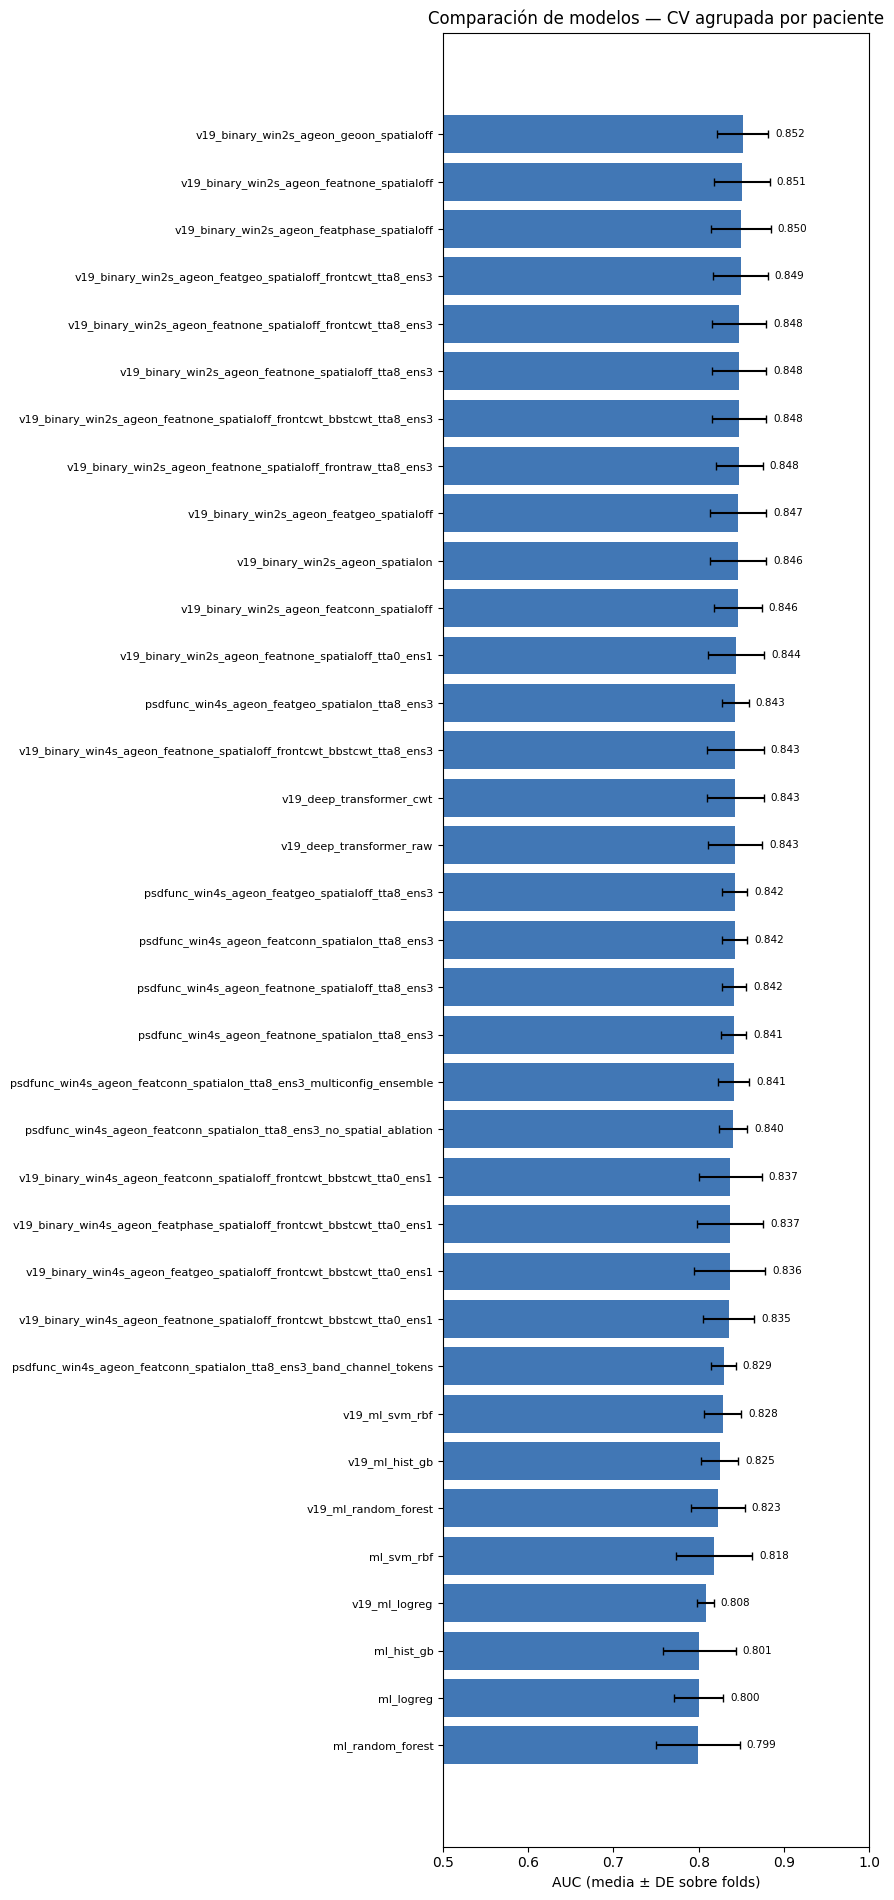


Mejor por AUC: 'v19_binary_win2s_ageon_geoon_spatialoff'. Contraste formal contra el base:
=== AUC: 'v19_binary_win2s_ageon_geoon_spatialoff'  vs  'psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3'   (5 folds pareados) ===
  v19_binary_win2s_ageon_geoon_spatialoff: 0.8519 ± 0.0336
  psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3: 0.8418 ± 0.0158
  Diferencia media (a−b): +0.0101   | Cohen's d: +0.267
  IC 95% de la diferencia (corregido): [-0.0603, +0.0804]
  p  t Nadeau-Bengio    : 0.7110   <-- el que se reporta
  p  Wilcoxon           : 0.8125
  Veredicto: no concluyente (IC incluye 0)


In [28]:
# ===== Paso 9c (v24): tabla comparativa de modelos desde cv_results.json =====
import pandas as pd
import matplotlib.pyplot as plt

def _msd(v):
    v = np.asarray(v, float); return float(np.nanmean(v)), float(np.nanstd(v))

def comparison_table(metrics=("auc", "auc_cn_mci", "auc_cn_dem", "auc_mci_dem", "acc", "f1", "sens", "spec"),
                     sort_by="auc"):
    if not os.path.exists(RESULTS_PATH):
        print("[SKIP] No hay cv_results.json todavía (corre el Paso 7/8)."); return None
    db = json.load(open(RESULTS_PATH))
    rows = []
    for name, d in db.items():
        row = {"modelo": name, "folds": int(d.get("_n_splits", len(d.get("auc", []))))}
        for mt in metrics:
            if mt in d and len(d[mt]):
                mu, sd = _msd(d[mt]); row[mt] = f"{mu:.3f}\u00b1{sd:.3f}"; row["_" + mt] = mu; row["_sd_" + mt] = sd
            else:
                row[mt] = "\u2014"; row["_" + mt] = np.nan; row["_sd_" + mt] = np.nan
        rows.append(row)
    df = pd.DataFrame(rows)
    if "_" + sort_by in df.columns:
        df = df.sort_values("_" + sort_by, ascending=False, na_position="last")
    show = ["modelo", "folds"] + [m for m in metrics if m in df.columns]
    df_show = df[show].reset_index(drop=True)
    try:
        from IPython.display import display; display(df_show)
    except Exception:
        print(df_show.to_string(index=False))
    return df

cmp_df = comparison_table()

# Figura: AUC medio +/- DE por modelo (barra horizontal, ordenado)
if cmp_df is not None and cmp_df["_auc"].notna().any():
    d = cmp_df.dropna(subset=["_auc"]).sort_values("_auc")
    names = d["modelo"].tolist(); mu = d["_auc"].values; sd = d["_sd_auc"].values
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(names) + 1.6))
    ax.barh(range(len(names)), mu, xerr=sd, color="#1F5FA8", alpha=0.85, capsize=3)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
    ax.set_xlabel("AUC (media \u00b1 DE sobre folds)"); ax.set_xlim(0.5, 1.0)
    ax.set_title("Comparaci\u00f3n de modelos \u2014 CV agrupada por paciente")
    for i, (m, s) in enumerate(zip(mu, sd)):
        ax.text(min(m + s + 0.008, 0.99), i, f"{m:.3f}", va="center", fontsize=7.5)
    plt.tight_layout(); plt.show()

    # Sugerencia: contrasta el mejor contra el base con el test de Nadeau-Bengio (Paso 9)
    best = cmp_df.sort_values("_auc", ascending=False)["modelo"].iloc[0]
    if best != EXP_NAME:
        print(f"\nMejor por AUC: '{best}'. Contraste formal contra el base:")
        compare_runs(best, EXP_NAME, metric="auc")

### Paso 9d — Batería de ablaciones (sin editar el CONFIG) (v28)

Cada celda de abajo fija una configuración (`FEATURE_MODE` × `USE_SPATIAL`), recalcula `EXP_NAME`, corre
la CV (`run_cv`) y la guarda (`save_run`) con su propio nombre en `cv_results.json` — **sin tocar el
CONFIG**. Córrelas una a una (puedes dejarlas en segundo plano). Al final, el **Paso 9c**
(`comparison_table()`) te muestra las cinco juntas.

Los dos canales por los que entra la geoestadística:
- **`USE_SPATIAL`** → el sesgo de atención del variograma (`Bspatial`).
- **`FEATURE_MODE`** → el descriptor fusionado: `"geo"` (geoestadístico), `"conn"` (baseline agnóstico) o `"none"`.

El modelo **estrella** es `featgeo_spatialon` (geoestadística en ambos canales); el **baseline** es
`featnone_spatialoff`. Solo la estrella guarda sus checkpoints en Drive (para el Paso 13c).

In [9]:
# --- Helper de ablaciones: fija los interruptores, corre la CV y guarda, sin editar el CONFIG ---
def run_ablation(feature_mode, use_spatial, star=False):
    """Fija FEATURE_MODE/USE_SPATIAL (globales que lee build_model), recalcula EXP_NAME, corre run_cv
    y guarda con save_run. Si star=True, copia los checkpoints a Drive para el Paso 13c."""
    global FEATURE_MODE, USE_SPATIAL, EXP_NAME, metrics
    FEATURE_MODE, USE_SPATIAL = feature_mode, use_spatial
    EXP_NAME = (f"psdfunc_win{WIN_SEC:g}s_age{'on' if USE_AGE else 'off'}_feat{FEATURE_MODE}_"
                f"spatial{'on' if USE_SPATIAL else 'off'}_tta{TTA_N if USE_TTA else 0}_ens{ENSEMBLE_K}")
    print(f"\n===== ABLACIÓN: {EXP_NAME} =====")
    m = run_cv()
    save_run(EXP_NAME, m)
    # resumen compacto (nan-aware)
    for k in ("auc", "auc_cn_mci", "auc_cn_dem", "auc_mci_dem", "acc", "f1", "sens", "spec"):
        if k in m[0]:
            v = np.array([mm[k] for mm in m], float)
            print(f"   {k:11s}: {np.nanmean(v):.4f} +/- {np.nanstd(v):.4f}")
    if star:
        import shutil, glob, os
        dst = os.path.join(CACHE_DIR, "checkpoints_estrella")
        os.makedirs(dst, exist_ok=True)
        n = 0
        for f in glob.glob("fold*_psdfunc_m*_v22.pt"):
            shutil.copy(f, dst); n += 1
        print(f"   [estrella] {n} checkpoints copiados a {dst} (para el Paso 13c)")
    metrics = m
    return m

print("run_ablation listo. Corre las celdas de abajo una a una.")

run_ablation listo. Corre las celdas de abajo una a una.


In [22]:
RESULTS_PATH = os.path.join(CACHE_DIR, "cv_results.json")
def save_run(name, metrics):
    db = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
    db[name] = {k: [float(m[k]) for m in metrics] for k in metrics[0].keys()}
    db[name]["_n_splits"] = N_SPLITS
    json.dump(db, open(RESULTS_PATH, "w"), indent=2)
    print(f"Guardado '{name}' ({len(metrics)} folds). Corridas disponibles:", list(db.keys()))

In [25]:
# A ★ ESTRELLA — geoestadística en descriptor + atención
run_ablation("geo", True, star=True)


===== ABLACIÓN: psdfunc_win4s_ageon_featgeo_spatialon_tta8_ens3 =====
  [fold1_m0] t1.lam por cabeza: [-0.114  -0.1353 -0.1013 -0.1766] (media |lam| = 0.1318)
  [fold1_m0] t2.lam por cabeza: [-0.0891 -0.075  -0.1532 -0.1018] (media |lam| = 0.1048)
  [fold1_m1] t1.lam por cabeza: [-0.0646 -0.049  -0.035  -0.0668] (media |lam| = 0.0538)
  [fold1_m1] t2.lam por cabeza: [-0.0149 -0.0513 -0.0187 -0.0369] (media |lam| = 0.0304)
  [fold1_m2] t1.lam por cabeza: [-0.0683 -0.0935 -0.0284 -0.1078] (media |lam| = 0.0745)
  [fold1_m2] t2.lam por cabeza: [-0.0449 -0.0837 -0.0912 -0.0517] (media |lam| = 0.0679)
  Fold 1: AUC 0.8402 | acc 0.7990 | F1 0.8282 | sens 0.7833 | spec 0.8243  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  [fold2_m0] t1.lam por cabeza: [-0.1156 -0.1329 -0.0752 -0.1212] (media |lam| = 0.1112)
  [fold2_m0] t2.lam por cabeza: [-0.0939 -0.0674 -0.1103 -0.0525] (media |lam| = 0.0810)
  [fold2_m1] t1.lam por cabeza: [-0.0344 -0.0225 -0.0189 -0.0427] (media |l

[{'acc': 0.7989690721649485,
  'f1': 0.8281938325991189,
  'auc': np.float64(0.8402027027027026),
  'sens': np.float64(0.7833333332680555),
  'spec': np.float64(0.8243243242129292),
  'auc_cn_mci': np.float64(0.7755581668625147),
  'auc_cn_dem': np.float64(0.9276629570747217),
  'auc_mci_dem': np.float64(0.7428246660983234)},
 {'acc': 0.7474226804123711,
  'f1': 0.7677725118483413,
  'auc': np.float64(0.8485745614035087),
  'sens': np.float64(0.7105263157271469),
  'spec': np.float64(0.7999999999),
  'auc_cn_mci': np.float64(0.7943548387096774),
  'auc_cn_dem': np.float64(0.9132211538461539),
  'auc_mci_dem': np.float64(0.7112282878411911)},
 {'acc': 0.7628865979381443,
  'f1': 0.7889908256880734,
  'auc': np.float64(0.8288113695090439),
  'sens': np.float64(0.7962962962225653),
  'spec': np.float64(0.7209302324743105),
  'auc_cn_mci': np.float64(0.7733452593917711),
  'auc_cn_dem': np.float64(0.9126554894537587),
  'auc_mci_dem': np.float64(0.7355992844364937)},
 {'acc': 0.81958762886

In [26]:
# B — geo en descriptor, SIN sesgo de atención (aísla el efecto del sesgo)
run_ablation("geo", False)


===== ABLACIÓN: psdfunc_win4s_ageon_featgeo_spatialoff_tta8_ens3 =====
  [fold1_m0] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m0] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m1] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m1] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m2] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m2] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  Fold 1: AUC 0.8359 | acc 0.7784 | F1 0.8089 | sens 0.7583 | spec 0.8108  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  [fold2_m0] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m0] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m1] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m1] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m2] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m2] t2.lam por cab

[{'acc': 0.7783505154639175,
  'f1': 0.8088888888888889,
  'auc': np.float64(0.8359234234234234),
  'sens': np.float64(0.758333333270139),
  'spec': np.float64(0.8108108107012418),
  'auc_cn_mci': np.float64(0.7694868781825305),
  'auc_cn_dem': np.float64(0.9258081611022787),
  'auc_mci_dem': np.float64(0.7408354646206309)},
 {'acc': 0.7525773195876289,
  'f1': 0.7714285714285715,
  'auc': np.float64(0.8468201754385966),
  'sens': np.float64(0.7105263157271469),
  'spec': np.float64(0.8124999998984376),
  'auc_cn_mci': np.float64(0.7905241935483871),
  'auc_cn_dem': np.float64(0.9139423076923077),
  'auc_mci_dem': np.float64(0.7205334987593052)},
 {'acc': 0.7525773195876289,
  'f1': 0.7777777777777778,
  'auc': np.float64(0.8333333333333334),
  'sens': np.float64(0.7777777777057614),
  'spec': np.float64(0.7209302324743105),
  'auc_cn_mci': np.float64(0.7785330948121646),
  'auc_cn_dem': np.float64(0.916170903190914),
  'auc_mci_dem': np.float64(0.7438282647584974)},
 {'acc': 0.7989690

In [ ]:
# (ya corrida en el flujo normal: featconn_spatialon) — re-córrela solo si quieres regenerarla
# run_ablation("conn", True)

In [ ]:
# D — solo sesgo de atención, SIN descriptor (aísla el efecto del descriptor)
run_ablation("none", True)


===== ABLACIÓN: psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3 =====
  [fold1_m0] t1.lam por cabeza: [-0.0917 -0.1179 -0.1249 -0.1044] (media |lam| = 0.1097)
  [fold1_m0] t2.lam por cabeza: [-0.0569 -0.0437 -0.0775 -0.0514] (media |lam| = 0.0574)
  [fold1_m1] t1.lam por cabeza: [-0.0949 -0.0867 -0.1151 -0.0553] (media |lam| = 0.0880)
  [fold1_m1] t2.lam por cabeza: [-0.0644 -0.0484 -0.0226 -0.0369] (media |lam| = 0.0431)
  [fold1_m2] t1.lam por cabeza: [-0.0782 -0.0172 -0.0599 -0.0333] (media |lam| = 0.0472)
  [fold1_m2] t2.lam por cabeza: [-0.0512  0.0011 -0.0096 -0.0286] (media |lam| = 0.0226)
  Fold 1: AUC 0.8400 | acc 0.7887 | F1 0.8145 | sens 0.7500 | spec 0.8514  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  [fold2_m0] t1.lam por cabeza: [-0.1004 -0.1045 -0.1095 -0.1031] (media |lam| = 0.1044)
  [fold2_m0] t2.lam por cabeza: [-0.1461 -0.0806 -0.1391 -0.1458] (media |lam| = 0.1279)
  [fold2_m1] t1.lam por cabeza: [-0.0469 -0.053  -0.0281 -0.0453] (media |

In [23]:
# E — BASELINE: sin geoestadística (ni descriptor ni sesgo de atención)
run_ablation("none", False)


===== ABLACIÓN: psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3 =====
  [fold1_m0] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m0] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m1] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m1] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m2] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold1_m2] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  Fold 1: AUC 0.8373 | acc 0.7887 | F1 0.8178 | sens 0.7667 | spec 0.8243  (ens 3, TTA 8, test 194 pac., selección por auc, hasta 200 épocas)
  [fold2_m0] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m0] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m1] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m1] t2.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m2] t1.lam por cabeza: [0. 0. 0. 0.] (media |lam| = 0.0000)
  [fold2_m2] t2.lam por ca

[{'acc': 0.788659793814433,
  'f1': 0.8177777777777778,
  'auc': np.float64(0.8372747747747746),
  'sens': np.float64(0.7666666666027778),
  'spec': np.float64(0.8243243242129292),
  'auc_cn_mci': np.float64(0.7743830787309047),
  'auc_cn_dem': np.float64(0.9223635400105988),
  'auc_mci_dem': np.float64(0.7360045467462347)},
 {'acc': 0.7371134020618557,
  'f1': 0.7582938388625592,
  'auc': np.float64(0.8373903508771929),
  'sens': np.float64(0.7017543859033549),
  'spec': np.float64(0.7874999999015626),
  'auc_cn_mci': np.float64(0.7743951612903226),
  'auc_cn_dem': np.float64(0.9125000000000001),
  'auc_mci_dem': np.float64(0.7316997518610422)},
 {'acc': 0.788659793814433,
  'f1': 0.8209606986899564,
  'auc': np.float64(0.8442075796726959),
  'sens': np.float64(0.8703703702897806),
  'spec': np.float64(0.6860465115481342),
  'auc_cn_mci': np.float64(0.7919499105545618),
  'auc_cn_dem': np.float64(0.9232017306652245),
  'auc_mci_dem': np.float64(0.7373881932021467)},
 {'acc': 0.8041237

In [ ]:
# (opcional) completa la malla: conn sin sesgo de atención
# run_ablation("conn", False)

In [29]:
# Ver las ablaciones juntas (misma función del Paso 9c)
comparison_table()

,modelo,folds,auc,auc_cn_mci,auc_cn_dem,auc_mci_dem,acc,f1,sens,spec
0,v19_binary_win2s_ageon_geoon_spatialoff,5,0.852±0.030,—,—,—,0.784±0.027,0.820±0.023,0.803±0.042,0.757±0.046
1,v19_binary_win2s_ageon_featnone_spatialoff,5,0.851±0.033,—,—,—,0.783±0.031,0.822±0.030,0.823±0.052,0.721±0.031
2,v19_binary_win2s_ageon_featphase_spatialoff,5,0.850±0.035,—,—,—,0.780±0.026,0.818±0.026,0.809±0.050,0.740±0.058
3,v19_binary_win2s_ageon_featgeo_spatialoff_fron...,5,0.849±0.032,—,—,—,0.778±0.036,0.818±0.034,0.819±0.047,0.717±0.038
4,v19_binary_win2s_ageon_featnone_spatialoff_tta...,5,0.848±0.031,—,—,—,0.780±0.032,0.820±0.030,0.822±0.045,0.718±0.050
5,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.031,—,—,—,0.780±0.032,0.820±0.030,0.822±0.045,0.718±0.050
6,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.031,—,—,—,0.780±0.032,0.820±0.030,0.822±0.045,0.718±0.050
7,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.028,—,—,—,0.776±0.024,0.814±0.024,0.806±0.057,0.735±0.041
8,v19_binary_win2s_ageon_featgeo_spatialoff,5,0.847±0.033,—,—,—,0.784±0.035,0.819±0.036,0.802±0.057,0.758±0.044
9,v19_binary_win2s_ageon_spatialon,5,0.846±0.033,—,—,—,0.779±0.031,0.818±0.028,0.815±0.032,0.724±0.035


,modelo,folds,auc,_auc,_sd_auc,auc_cn_mci,_auc_cn_mci,_sd_auc_cn_mci,auc_cn_dem,_auc_cn_dem,...,_sd_acc,f1,_f1,_sd_f1,sens,_sens,_sd_sens,spec,_spec,_sd_spec
2,v19_binary_win2s_ageon_geoon_spatialoff,5,0.852±0.030,0.851884,0.030088,—,NaN,NaN,—,NaN,...,0.026869,0.820±0.023,0.819938,0.023270,0.803±0.042,0.803061,0.041686,0.757±0.046,0.756566,0.045556
4,v19_binary_win2s_ageon_featnone_spatialoff,5,0.851±0.033,0.850500,0.032898,—,NaN,NaN,—,NaN,...,0.031047,0.822±0.030,0.822389,0.030500,0.823±0.052,0.823132,0.051743,0.721±0.031,0.721380,0.031069
6,v19_binary_win2s_ageon_featphase_spatialoff,5,0.850±0.035,0.849852,0.034844,—,NaN,NaN,—,NaN,...,0.026099,0.818±0.026,0.817630,0.026259,0.809±0.050,0.808709,0.050194,0.740±0.058,0.739815,0.058008
17,v19_binary_win2s_ageon_featgeo_spatialoff_fron...,5,0.849±0.032,0.849354,0.032060,—,NaN,NaN,—,NaN,...,0.036128,0.818±0.034,0.818279,0.033880,0.819±0.047,0.819013,0.046810,0.717±0.038,0.716833,0.038033
7,v19_binary_win2s_ageon_featnone_spatialoff_tta...,5,0.848±0.031,0.847706,0.031449,—,NaN,NaN,—,NaN,...,0.032353,0.820±0.030,0.820137,0.029958,0.822±0.045,0.822149,0.045030,0.718±0.050,0.717531,0.049683
18,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.031,0.847706,0.031449,—,NaN,NaN,—,NaN,...,0.032353,0.820±0.030,0.820137,0.029958,0.822±0.045,0.822149,0.045030,0.718±0.050,0.717531,0.049683
9,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.031,0.847706,0.031449,—,NaN,NaN,—,NaN,...,0.032353,0.820±0.030,0.820137,0.029958,0.822±0.045,0.822149,0.045030,0.718±0.050,0.717531,0.049683
10,v19_binary_win2s_ageon_featnone_spatialoff_fro...,5,0.848±0.028,0.847681,0.027829,—,NaN,NaN,—,NaN,...,0.024063,0.814±0.024,0.814285,0.023535,0.806±0.057,0.805680,0.056727,0.735±0.041,0.735066,0.040999
3,v19_binary_win2s_ageon_featgeo_spatialoff,5,0.847±0.033,0.846536,0.032782,—,NaN,NaN,—,NaN,...,0.034897,0.819±0.036,0.818809,0.035509,0.802±0.057,0.802374,0.056891,0.758±0.044,0.758273,0.044238
1,v19_binary_win2s_ageon_spatialon,5,0.846±0.033,0.846480,0.032837,—,NaN,NaN,—,NaN,...,0.030978,0.818±0.028,0.818483,0.028026,0.815±0.032,0.814630,0.031513,0.724±0.035,0.723640,0.034847


## Paso 10 — ML clásico sobre potencia de banda relativa (directo desde la PSD)

En v19 esto requería un Welch aparte sobre la señal cruda; aquí la potencia de banda se integra
**directamente sobre `X_psd`** (multitaper, más preciso que el Welch rápido), agregada por paciente y
con la misma validación 5-fold estratificada de v19.

In [30]:
from collections import defaultdict as _dd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

_pat = _dd(list)
for _i, _s in enumerate(groups): _pat[_s].append(_i)
_serials = list(_pat.keys())

PSD_LINEAR = X_psd if PSD_SCALE != "log10" else (10.0 ** X_psd)   # potencia en escala lineal para integrar

def patient_bandpower(idxs):
    seg = PSD_LINEAR[idxs]                              # [n,19,n_freq]
    total = seg.sum(-1) + 1e-12                          # [n,19]
    bands = []
    for (lo,hi) in GEO_BANDS.values():
        m = (FREQS>=lo)&(FREQS<hi); bands.append(seg[...,m].sum(-1)/total)  # [n,19]
    feat = np.concatenate(bands, axis=1)                  # [n, n_bandas*19]
    return feat.mean(0)                                   # promedio de trozos -> 1 vector por paciente

Xp_feat = np.stack([patient_bandpower(_pat[s]) for s in _serials])
yp_feat = np.array([serial2bin[s] for s in _serials])
ap_feat = np.array([(serial2age[s]-60.0)/20.0 for s in _serials])
Xp_feat = np.concatenate([Xp_feat, ap_feat[:,None]], axis=1) if USE_AGE else Xp_feat
print("Features ML clásico (potencia de banda relativa + edad):", Xp_feat.shape)

def ml_metrics(yt, prob):
    pred=(prob>=0.5).astype(int); tn,fp,fn,tp=confusion_matrix(yt,pred,labels=[0,1]).ravel()
    return {"acc":accuracy_score(yt,pred),"f1":f1_score(yt,pred,zero_division=0),
            "auc":roc_auc_score(yt,prob) if len(set(yt))>1 else float("nan"),
            "sens":tp/(tp+fn+1e-8), "spec":tn/(tn+fp+1e-8)}

CLASSIFIERS = {
    "ml_logreg":       make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "ml_svm_rbf":      make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, class_weight="balanced")),
    "ml_random_forest":RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", random_state=0),
    "ml_hist_gb":      HistGradientBoostingClassifier(random_state=0),
}
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
for name, clf0 in CLASSIFIERS.items():
    fold_m = []
    for tr_idx, te_idx in skf.split(Xp_feat, yp_feat):
        clf = clone(clf0); clf.fit(Xp_feat[tr_idx], yp_feat[tr_idx])
        prob = clf.predict_proba(Xp_feat[te_idx])[:,1]
        fold_m.append(ml_metrics(yp_feat[te_idx], prob))
    save_run(name, fold_m)
    mu = {k: np.mean([m[k] for m in fold_m]) for k in ["auc","acc","f1"]}
    print(f"  {name:18s}: AUC {mu['auc']:.3f} | acc {mu['acc']:.3f} | F1 {mu['f1']:.3f}")

Features ML clásico (potencia de banda relativa + edad): (970, 77)
Guardado 'ml_logreg' (5 folds). Corridas disponibles: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_featconn_spatialoff', 'v19_binary_win2s_ageon_featphase_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_tta0_ens1', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontraw_tta8_ens3', 'v19_deep_transformer_cwt', 'v19_deep_transformer_raw', 'v19_ml_logreg', 'v19_ml_svm_rbf', 'v19_ml_random_forest', 'v19_ml_hist_gb', 'v19_binary_win2s_ageon_featgeo_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta8_ens3', 'v19_binary_win4s_ageon_featnone_spatialoff_frontcw

## Paso 11 — Tabla comparativa final (PSD-funcional vs EEG-crudo v19 vs ML clásico)

In [31]:
db = json.load(open(RESULTS_PATH))
def _msd(v): return f"{np.mean(v):.3f}+-{np.std(v):.3f}"
order = [EXP_NAME, "v19_deep_transformer_cwt", "v19_deep_transformer_raw",
         "ml_logreg","ml_svm_rbf","ml_random_forest","ml_hist_gb"]
seen=set()
print(f"{'modelo':42s} {'ACC':>16} {'AUC':>16} {'F1':>16} {'Recall':>16}")
print("-"*110)
for n in order + list(db.keys()):
    if n is None or n in seen or n.startswith("_"): continue
    seen.add(n)
    d = db.get(n)
    if not (isinstance(d, dict) and "acc" in d): continue
    print(f"{n:42s} {_msd(d['acc']):>16} {_msd(d['auc']):>16} {_msd(d['f1']):>16} {_msd(d['sens']):>16}")

modelo                                                  ACC              AUC               F1           Recall
--------------------------------------------------------------------------------------------------------------
psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3     0.775+-0.024     0.842+-0.014     0.803+-0.024     0.772+-0.055
v19_deep_transformer_cwt                       0.772+-0.029     0.843+-0.033     0.809+-0.028     0.791+-0.042
v19_deep_transformer_raw                       0.776+-0.029     0.843+-0.032     0.813+-0.027     0.799+-0.046
ml_logreg                                      0.733+-0.018     0.800+-0.029     0.763+-0.020     0.726+-0.042
ml_svm_rbf                                     0.759+-0.039     0.818+-0.045     0.804+-0.028     0.832+-0.029
ml_random_forest                               0.752+-0.046     0.799+-0.049     0.802+-0.033     0.844+-0.024
ml_hist_gb                                     0.744+-0.044     0.801+-0.043     0.791+-0.033     0.816+-

## Paso 12 — Interpretabilidad: perfil de variograma funcional por banda y grupo (biomarcador)

Análogo a la Sección 10 de `Geoestadistica_Funcional_EEG_v8`, pero reutilizando directamente
`FunctionalSpatialDescriptor(mode="geo")` (ya calculado con la métrica de Gram confirmada) sobre TODAS
las ventanas, para comparar Normal vs Deteriorado (MCI+Demencia) banda por banda, con tamaño de efecto
(Cliff's delta) y significancia (Mann-Whitney U + FDR). Es no supervisado a nivel de arquitectura (el
descriptor no tiene parámetros) — solo se usa la etiqueta para el contraste estadístico posterior, igual
que en el notebook de geoestadística.

In [32]:
from scipy.stats import mannwhitneyu

desc_interp = FunctionalSpatialDescriptor(FREQS, Phi_full, GEO_BANDS, ELECTRODE_XY, REGION_ID, mode="geo", dist_gc=DIST_GC).to(device)

@torch.no_grad()
def bandprofile_batches(idxs, bs=256):
    out = []
    for i in range(0, len(idxs), bs):
        z = torch.from_numpy(COEF[idxs[i:i+bs]]).float().to(device)
        out.append(desc_interp(z).cpu().numpy())
    return np.concatenate(out, 0)          # [n, n_bands*5]

idx_normal = np.where(y==0)[0]; idx_imp = np.where(y==1)[0]
# subsample para no saturar memoria/tiempo en el análisis interpretativo
rngi = np.random.default_rng(1)
idx_normal_s = rngi.choice(idx_normal, size=min(4000, len(idx_normal)), replace=False)
idx_imp_s    = rngi.choice(idx_imp,    size=min(4000, len(idx_imp)),    replace=False)

prof_n = bandprofile_batches(idx_normal_s).reshape(-1, len(desc_interp.band_names), 5)
prof_i = bandprofile_batches(idx_imp_s).reshape(-1, len(desc_interp.band_names), 5)
# feature 0/1/2 = anillos de distancia (cerca/media/lejos), 3/4 = anisotropia A-P / lateral
tier_names = ["dist_cerca","dist_media","dist_lejos","anisotropia_AP","anisotropia_lateral"]

def cliffs_delta(a, b):
    a=np.asarray(a,float); b=np.asarray(b,float)
    return float(np.sign(a[:,None]-b[None,:]).sum())/(len(a)*len(b))

rows = []
for bi, bn in enumerate(desc_interp.band_names):
    for ti, tn in enumerate(tier_names):
        a, b = prof_n[:,bi,ti], prof_i[:,bi,ti]
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        rows.append((bn, tn, float(a.mean()), float(b.mean()), cliffs_delta(a,b), p))

def bh_fdr(p):
    p=np.asarray(p,float); n=len(p); o=np.argsort(p); r=p[o]
    q=np.minimum.accumulate((r*n/np.arange(1,n+1))[::-1])[::-1]
    out=np.empty(n); out[o]=np.clip(q,0,1); return out

pvals = np.array([r[5] for r in rows]); qvals = bh_fdr(pvals)
print(f"{'banda':8s} {'anillo':18s} {'Normal':>10s} {'Deteriorado':>12s} {'Cliff d':>9s} {'p':>9s} {'q(FDR)':>9s}")
for r, q in zip(rows, qvals):
    sig = "*" if q < 0.05 else " "
    print(f"{r[0]:8s} {r[1]:18s} {r[2]:10.4f} {r[3]:12.4f} {r[4]:+9.3f} {r[5]:9.4f} {q:9.4f} {sig}")

banda    anillo                 Normal  Deteriorado   Cliff d         p    q(FDR)
low      dist_cerca             0.2131       0.2257    -0.049    0.0001    0.0002 *
low      dist_media             0.2479       0.2679    -0.096    0.0000    0.0000 *
low      dist_lejos             0.2530       0.2718    -0.072    0.0000    0.0000 *
low      anisotropia_AP         0.2455       0.2608    -0.058    0.0000    0.0000 *
low      anisotropia_lateral     0.2292       0.2485    -0.093    0.0000    0.0000 *
theta    dist_cerca             0.2520       0.2523    +0.042    0.0010    0.0015 *
theta    dist_media             0.3026       0.3059    -0.006    0.6432    0.6432  
theta    dist_lejos             0.3521       0.3465    +0.040    0.0019    0.0026 *
theta    anisotropia_AP         0.3371       0.3285    +0.058    0.0000    0.0000 *
theta    anisotropia_lateral     0.2615       0.2701    -0.027    0.0386    0.0454 *
alpha    dist_cerca             0.3643       0.3257    +0.209    0.0000    0

### Paso 12b — Biomarcador honesto: nivel sujeto + ajuste por edad (v24)

El Paso 12 contrasta **ventanas**, no sujetos: cada paciente aporta decenas de ventanas, así que los
*p*-valores están inflados por **pseudo-réplica** (las ventanas de un mismo sujeto no son
independientes). Además, en demencia la edad es un confusor fortísimo: un efecto "Normal vs.
Deteriorado" puede ser, en el fondo, un efecto de edad.

Este paso rehace el análisis de forma defendible: (1) **agrega a nivel de sujeto** (una observación
por paciente = media de su perfil variográfico), y (2) **residualiza la edad** antes de los
contrastes. Se reportan, lado a lado, el estadístico **crudo** y el **ajustado por edad**. Los
efectos que sobreviven a ambos filtros son los únicos candidatos honestos a biomarcador.

In [33]:
from collections import OrderedDict
from scipy.stats import kruskal, spearmanr

# 1) Perfil variografico de TODAS las ventanas, luego media por SUJETO (una fila por paciente).
prof_all = bandprofile_batches(np.arange(len(COEF))).reshape(-1, len(desc_interp.band_names), 5)
subj_order = list(OrderedDict.fromkeys(groups.tolist()))            # sujetos en orden de aparicion
subj_rows  = {s: np.where(groups == s)[0] for s in subj_order}
Xs_subj = np.stack([prof_all[subj_rows[s]].mean(0) for s in subj_order], 0)   # [n_suj, n_bands, 5]
lab3_s  = np.array([serial2three[s] for s in subj_order])           # 0=CN 1=MCI 2=DEM por sujeto
age_s   = np.array([serial2age[s]   for s in subj_order], float)    # edad real (anios) por sujeto
print(f"Nivel sujeto: {len(subj_order)} pacientes | CN {int((lab3_s==0).sum())} "
      f"MCI {int((lab3_s==1).sum())} DEM {int((lab3_s==2).sum())}")

def _residualize_age(v, age):
    """Residuos de v tras regresar linealmente sobre la edad (elimina el efecto lineal de edad)."""
    A = np.column_stack([np.ones_like(age), age])
    beta, *_ = np.linalg.lstsq(A, v, rcond=None)
    return v - A @ beta

def _cliff_imp(v, lab3):          # Cliff delta Normal (0) vs Deteriorado (>0)
    return cliffs_delta(v[lab3 == 0], v[lab3 > 0])

rows12b = []
for bi, bn in enumerate(desc_interp.band_names):
    for ti, tn in enumerate(tier_names):
        v = Xs_subj[:, bi, ti]
        gr_c = [v[lab3_s == g] for g in (0, 1, 2) if np.any(lab3_s == g)]
        _, p_c = kruskal(*gr_c);           rho_c, _ = spearmanr(lab3_s, v);  d_c = _cliff_imp(v, lab3_s)
        vr = _residualize_age(v, age_s)
        gr_a = [vr[lab3_s == g] for g in (0, 1, 2) if np.any(lab3_s == g)]
        _, p_a = kruskal(*gr_a);           rho_a, _ = spearmanr(lab3_s, vr); d_a = _cliff_imp(vr, lab3_s)
        rows12b.append((bn, tn, rho_c, d_c, p_c, rho_a, d_a, p_a))

q_c = bh_fdr(np.array([r[4] for r in rows12b]))
q_a = bh_fdr(np.array([r[7] for r in rows12b]))
print(f"\n{'banda':7s} {'anillo':18s} | {'rho':>6s} {'Cliff':>6s} {'q':>7s} | "
      f"{'rho*':>6s} {'Cliff*':>7s} {'q*':>7s}   (crudo | *=ajustado por edad)")
for r, qc, qa in zip(rows12b, q_c, q_a):
    sc = "*" if qc < 0.05 else " "; sa = "*" if qa < 0.05 else " "
    print(f"{r[0]:7s} {r[1]:18s} | {r[2]:+6.2f} {r[3]:+6.2f} {qc:6.3f}{sc} | "
          f"{r[5]:+6.2f} {r[6]:+7.2f} {qa:6.3f}{sa}")

n_c = int((q_c < 0.05).sum()); n_a = int((q_a < 0.05).sum())
print(f"\nResumen: {n_c}/{len(rows12b)} contrastes significativos en crudo -> "
      f"{n_a}/{len(rows12b)} tras ajustar por edad y agregar a nivel sujeto (q<0.05).")
print("Los efectos que SOBREVIVEN son los candidatos honestos a biomarcador; los que desaparecen")
print("eran en buena parte edad o pseudo-replica de ventana.")

Nivel sujeto: 970 pacientes | CN 394 MCI 329 DEM 247

banda   anillo             |    rho  Cliff       q |   rho*  Cliff*      q*   (crudo | *=ajustado por edad)
low     dist_cerca         |  +0.05  -0.05  0.374  |  +0.02   -0.02  0.847 
low     dist_media         |  +0.12  -0.12  0.004* |  +0.05   -0.04  0.287 
low     dist_lejos         |  +0.07  -0.07  0.156  |  +0.02   -0.01  0.841 
low     anisotropia_AP     |  +0.05  -0.05  0.319  |  +0.02   -0.01  0.841 
low     anisotropia_lateral |  +0.11  -0.12  0.007* |  +0.04   -0.04  0.420 
theta   dist_cerca         |  -0.06  +0.06  0.233  |  -0.06   +0.06  0.311 
theta   dist_media         |  +0.01  -0.01  0.931  |  -0.04   +0.05  0.420 
theta   dist_lejos         |  -0.07  +0.07  0.131  |  -0.09   +0.09  0.043*
theta   anisotropia_AP     |  -0.08  +0.08  0.099  |  -0.08   +0.08  0.100 
theta   anisotropia_lateral |  +0.02  -0.03  0.589  |  -0.05   +0.05  0.370 
alpha   dist_cerca         |  -0.22  +0.25  0.000* |  -0.12   +0.14  0.006*


## Paso 13 — Topomapas: semivarianza funcional por canal

Decorrelación geoestadística por canal (semivarianza media de cada electrodo con el resto, usando
la métrica de Gram sobre `COEF`) — no necesita modelo entrenado.

**Actualización (recomendación del codirector):** los topoplots ahora usan
[`mne.viz.plot_topomap`](https://mne.tools/stable/generated/mne.viz.plot_topomap.html) con las
posiciones **reales** del montaje 10-20 estándar (`mne.channels.make_standard_montage("standard_1020")`),
en vez de las coordenadas XY aproximadas + interpolación `griddata` que usaban v20/v21. Esto elimina dos
problemas que señaló: (1) los "flechazos"/artefactos de la interpolación cúbica ad-hoc sobre pocos puntos
dispersos, y (2) la distorsión en la periferia (efecto "topoplot dentro de otro topoplot"), que ocurría
porque las coordenadas XY aproximadas no correspondían a la proyección real de la esfera de la cabeza que
usa MNE — con `plot_topomap`, el mismo modelo de proyección/interpolación se aplica de forma consistente
en el centro y en la periferia.


/tmp/ipykernel_604/3421492084.py:12: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")


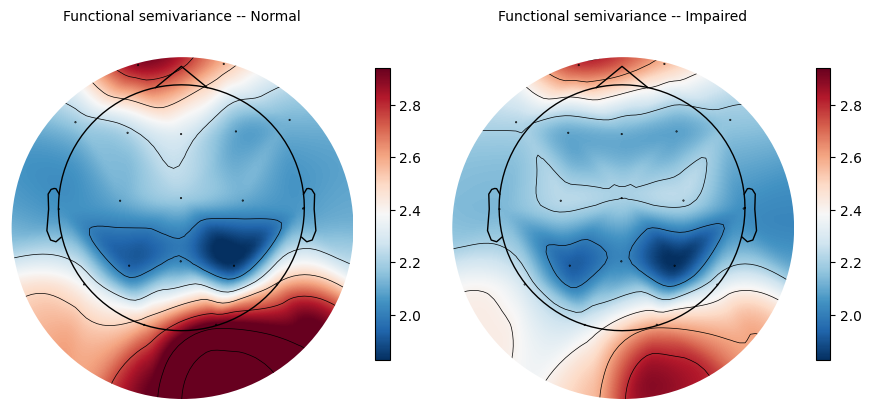

In [34]:
import mne

def _build_topomap_info():
    """MNE Info object with the REAL 10-20 standard montage positions (same renaming trick
    T3/T4/T5/T6/FZ/CZ/PZ -> T7/T8/P7/P8/Fz/Cz/Pz already used by _ica_fit_and_label in Step 1,
    since standard_1020 only recognizes the modern names). Uses mne.viz.plot_topomap directly
    (co-advisor's recommendation) instead of a griddata interpolation over approximate XY
    coordinates -- avoids peripheral distortion and interpolation artifacts over few, sparse
    points."""
    info = mne.create_info(ch_names=CANONICAL, sfreq=TARGET_SFREQ, ch_types="eeg")
    info.rename_channels(_MODERN_MONTAGE_MAP)
    info.set_montage(mne.channels.make_standard_montage("standard_1020"), on_missing="ignore")
    info.rename_channels({v: k for k, v in _MODERN_MONTAGE_MAP.items()})
    return info

MNE_TOPO_INFO = _build_topomap_info()

def topomap(ax, values, title, cmap="RdBu_r", info=MNE_TOPO_INFO, colorbar=True, vlim=None):
    """Topoplot using mne.viz.plot_topomap: real 10-20 montage positions, head outline/mask, and
    MNE's standard interpolation (Clough-Tocher over the real 2D sensor projection), consistent
    between center and periphery.

    vmin/vmax FIX: without an explicit `vlim`, MNE normalizes each topomap's color scale using the
    min/max of ITS OWN interpolated mesh -- which includes extrapolated values toward the head
    edge, almost always more extreme than the 19 real channel values. That pushes the real values
    toward the top of the scale (everything looks "clipped" red) and also makes two group topomaps
    incomparable if each one scales differently. `vlim` is now ALWAYS computed from the real
    per-channel values (not the interpolated mesh), and when comparing two groups the same
    (vmin, vmax) is passed to both calls so they share a scale."""
    im, _ = mne.viz.plot_topomap(values, info, axes=ax, show=False, cmap=cmap,
                                  contours=6, sensors=True, outlines="head", sphere="auto",
                                  vlim=vlim)
    ax.set_title(title, fontsize=10)
    if colorbar:
        plt.colorbar(im, ax=ax, shrink=0.75, pad=0.05)
    return im

def channel_semivariance(coef_stack, W):
    acc = np.zeros(N_CH)
    for Z in coef_stack:
        Q = np.einsum('ik,kl,il->i', Z, W, Z)
        Cross = Z @ W @ Z.T
        D2 = np.clip(Q[:,None] + Q[None,:] - 2*Cross, 0, None)
        np.fill_diagonal(D2, 0.0)
        acc += 0.5*D2.sum(1)/(N_CH-1)
    return acc/len(coef_stack)

import matplotlib.pyplot as plt
sv_normal = channel_semivariance(COEF[idx_normal_s], W)
sv_imp    = channel_semivariance(COEF[idx_imp_s], W)

# Shared vlim, computed over each group's real 19 channel values (not the interpolated mesh)
sv_vmin = min(sv_normal.min(), sv_imp.min())
sv_vmax = max(sv_normal.max(), sv_imp.max())

fig, axes = plt.subplots(1, 2, figsize=(9,4.2))
topomap(axes[0], sv_normal, "Functional semivariance -- Normal", vlim=(sv_vmin, sv_vmax))
topomap(axes[1], sv_imp,    "Functional semivariance -- Impaired", vlim=(sv_vmin, sv_vmax))
plt.tight_layout(); plt.show()


### (Opcional) Restaurar checkpoints desde Drive — correr **antes del Paso 13c** (v26)

Si reiniciaste el entorno, los checkpoints de `/content` se perdieron. Esta celda los **trae de vuelta
desde Drive** (los que guardaste con la celda del Paso 8) para que el Paso 13c funcione sin re-entrenar.
Córrela después de los Pasos 1–6 y justo antes del Paso 13c. Si el entorno sigue vivo con el Paso 7 ya
corrido, no hace falta.

In [35]:
import shutil, glob, os
src = os.path.join(CACHE_DIR, "checkpoints_v22")
found = glob.glob(os.path.join(src, "*.pt"))
if found:
    for f in found:
        shutil.copy(f, ".")
    print(f"{len(found)} checkpoints restaurados a /content desde {src}")
else:
    print(f"[INFO] No hay checkpoints en {src}. Si el entorno sigue vivo con el Paso 7 ya corrido no "
          f"necesitas restaurar; si reiniciaste y no los guardaste, re-corre el Paso 7.")

15 checkpoints restaurados a /content desde /content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt_psd_v21/checkpoints_v22


In [36]:
FEATURE_MODE, USE_SPATIAL = "geo", True      # modelo ★ (o "conn", True para el principal)
import shutil, glob, os
src = os.path.join(CACHE_DIR, "checkpoints_estrella")   # ★ (o "checkpoints_v22" para el principal)
for f in glob.glob(os.path.join(src, "*.pt")): shutil.copy(f, ".")
print(len(glob.glob("fold*_psdfunc_m*_v22.pt")), "checkpoints restaurados")

15 checkpoints restaurados


### Paso 13c — Concordancia atención ↔ variograma (v24)

El Paso 13 muestra la **semivarianza funcional por canal**; `inspect_spatial_gates` (Paso 7) muestra
cuánto pesa el prior geoestadístico (`lam`) dentro de la atención. Este paso **cierra el lazo** y lo
convierte en un resultado medible: ¿la atención espacial que el transformer **aprende** reproduce la
estructura **variográfica** que le dimos como sesgo?

Se comparan dos objetos, a nivel de canal y de matriz:

- **Importancia de atención por canal** = PageRank de la matriz de atención media (bloque `t2`) sobre
  ventanas reales, promediada sobre los checkpoints guardados por el Paso 7.
- **Estructura variográfica** = semivarianza funcional por canal (Paso 13) y la matriz `Bspatial`
  (coherencia espacial del variograma funcional, Paso 3b).

El **test de Mantel** (permutación de filas/columnas, p por remuestreo) mide si la atención simétrica y
`Bspatial` concuerdan a nivel de matriz. Una concordancia significativa **sustenta la interpretabilidad
espectro-espacial** del modelo; una no significativa es igual de reportable (coherente con `lam≈0`: el
transformer aprendió a ignorar el prior por su cuenta). Requiere haber corrido antes el **Paso 7**
(deja los checkpoints `fold*_psdfunc_m*_v22.pt`).

In [57]:
def topomap(ax, values, title, cmap="RdBu_r", colorbar=True, vlim=None):
    """Contorno ajustado al campo de color (POS2D + esfera 1.05 + extrapolate='head').
    FIX vlim: esta versión de MNE exige una tupla (vmin, vmax); si no se pasa, se calcula
    de los 19 valores reales por canal (no de la malla interpolada)."""
    if vlim is None:
        vlim = (float(np.min(values)), float(np.max(values)))
    im, _ = mne.viz.plot_topomap(values, POS2D, axes=ax, show=False, cmap=cmap,
                                 contours=6, sensors=True, outlines="head",
                                 extrapolate="head", sphere=(0.0, 0.0, 0.0, 1.05), vlim=vlim)
    ax.set_title(title, fontsize=10)
    if colorbar:
        plt.colorbar(im, ax=ax, shrink=0.75, pad=0.05)
    return im

Atención promediada sobre 15 checkpoint(s).
  [checkpoint[0]] t1.lam por cabeza: [-0.114  -0.1353 -0.1013 -0.1766] (media |lam| = 0.1318)
  [checkpoint[0]] t2.lam por cabeza: [-0.0891 -0.075  -0.1532 -0.1018] (media |lam| = 0.1048)

=== Concordancia a nivel de CANAL (Spearman) ===
  importancia atención vs semivarianza funcional : rho=-0.114  p=0.6420
  importancia atención vs coherencia espacial    : rho=-0.637  p=0.0034

=== Concordancia a nivel de MATRIZ (test de Mantel, 2000 perms) ===
  atención simétrica vs Bspatial geoestadístico  : r=-0.289  p=0.0005
  Veredicto: SIGNIFICATIVA -> la atención aprendida reproduce la estructura variográfica (sustenta la interpretabilidad espectro-espacial).


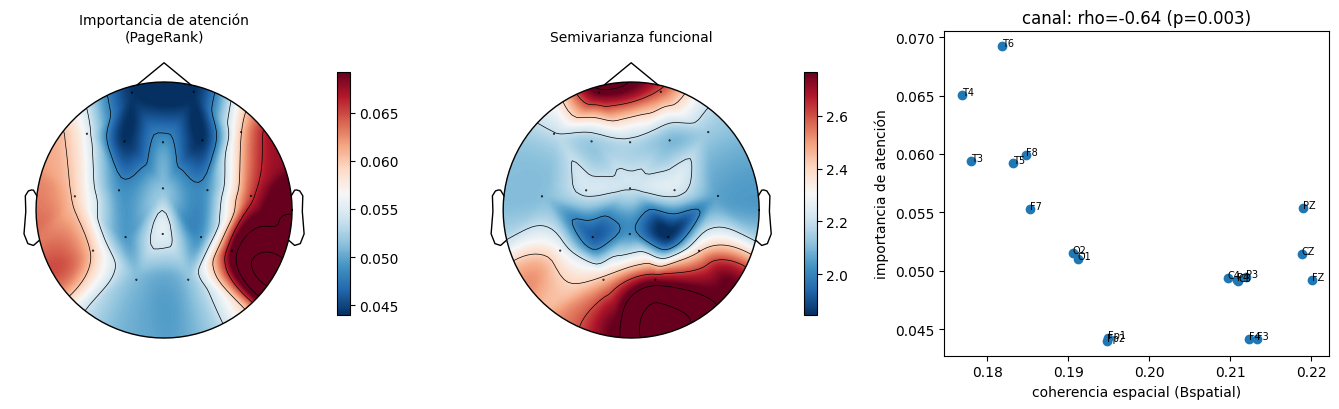

In [58]:
# ===== Paso 13c (v24): concordancia atención <-> variograma =====
import glob
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

def _pagerank(A, d=0.85, iters=300):
    """PageRank de la matriz de atención: importancia = cuánto es ATENDIDO cada canal."""
    M = A / (A.sum(1, keepdims=True) + 1e-12)        # fila-estocástica
    n = A.shape[0]; r = np.ones(n) / n
    for _ in range(iters):
        r = (1 - d) / n + d * (M.T @ r)
    return r / r.sum()

@torch.no_grad()
def _attention_matrix(model, indices, max_batches=25):
    """Matriz de atención media [19x19] del bloque t2 sobre una muestra de ventanas reales."""
    model.eval(); acc = np.zeros((N_CH, N_CH)); n = 0
    for bi, (xb, ab, yb) in enumerate(make_loader(indices, augment=False, shuffle=False)):
        if bi >= max_batches: break
        _, a = model(xb.to(device), ab.to(device))    # [B, heads, 19, 19]
        acc += a.mean(dim=(0, 1)).cpu().numpy(); n += 1
    return acc / max(n, 1)

def _mantel(A, Bm, n_perm=2000, seed=0):
    """Test de Mantel: Spearman sobre la off-diagonal + permutación conjunta de filas/columnas."""
    iu = np.triu_indices(A.shape[0], 1); b = Bm[iu]
    r_obs = spearmanr(A[iu], b).correlation
    rng = np.random.default_rng(seed); n = A.shape[0]; ge = 0
    for _ in range(n_perm):
        p = rng.permutation(n)
        if abs(spearmanr(A[np.ix_(p, p)][iu], b).correlation) >= abs(r_obs): ge += 1
    return float(r_obs), (ge + 1) / (n_perm + 1)

ckpts = sorted(glob.glob("fold*_psdfunc_m*_v22.pt"))
if not ckpts:
    print("[SKIP] No hay checkpoints 'fold*_psdfunc_m*_v22.pt'. Corre primero el Paso 7.")
else:
    rng_c = np.random.default_rng(0)
    samp = rng_c.choice(len(COEF), size=min(3000, len(COEF)), replace=False)

    # 1) Atención media sobre todos los checkpoints disponibles
    A = np.zeros((N_CH, N_CH))
    for ck in ckpts:
        m = build_model(); m.load_state_dict(torch.load(ck, map_location=device)); m.eval()
        A += _attention_matrix(m, samp); del m
        if device.type == "cuda": torch.cuda.empty_cache()
    A /= len(ckpts)
    print(f"Atención promediada sobre {len(ckpts)} checkpoint(s).")
    _mg = build_model(); _mg.load_state_dict(torch.load(ckpts[0], map_location=device))
    inspect_spatial_gates(_mg, label="checkpoint[0]"); del _mg

    # 2) Estructura variográfica por canal
    A_sym = 0.5 * (A + A.T)
    imp = _pagerank(A)                                            # importancia de atención (PageRank)
    sv  = channel_semivariance(COEF[samp], W)                    # semivarianza funcional por canal
    offm = ~np.eye(N_CH, dtype=bool)
    coh = (SPATIAL_C * offm).sum(1) / (N_CH - 1)                 # coherencia espacial (Bspatial) por canal

    # 3) Tests de concordancia
    rho_sv,  p_sv  = spearmanr(imp, sv)
    rho_coh, p_coh = spearmanr(imp, coh)
    r_mantel, p_mantel = _mantel(A_sym, SPATIAL_C, n_perm=2000)

    print("\n=== Concordancia a nivel de CANAL (Spearman) ===")
    print(f"  importancia atención vs semivarianza funcional : rho={rho_sv:+.3f}  p={p_sv:.4f}")
    print(f"  importancia atención vs coherencia espacial    : rho={rho_coh:+.3f}  p={p_coh:.4f}")
    print("\n=== Concordancia a nivel de MATRIZ (test de Mantel, 2000 perms) ===")
    print(f"  atención simétrica vs Bspatial geoestadístico  : r={r_mantel:+.3f}  p={p_mantel:.4f}")
    verd = ("SIGNIFICATIVA -> la atención aprendida reproduce la estructura variográfica "
            "(sustenta la interpretabilidad espectro-espacial)." if p_mantel < 0.05 else
            "no significativa -> la atención no sigue el prior variográfico "
            "(esperable si los lambda espaciales quedaron ~0; igualmente reportable).")
    print(f"  Veredicto: {verd}")

    # 4) Visual: topomapa de importancia de atención, semivarianza y dispersión
    fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.2))
    topomap(ax[0], imp, "Importancia de atención\n(PageRank)", colorbar=True)
    topomap(ax[1], sv,  "Semivarianza funcional", colorbar=True)
    ax[2].scatter(coh, imp, color="tab:blue")
    for i, nm in enumerate(CANONICAL):
        ax[2].annotate(nm, (coh[i], imp[i]), fontsize=7)
    ax[2].set_xlabel("coherencia espacial (Bspatial)"); ax[2].set_ylabel("importancia de atención")
    ax[2].set_title(f"canal: rho={rho_coh:+.2f} (p={p_coh:.3f})")
    plt.tight_layout(); plt.show()

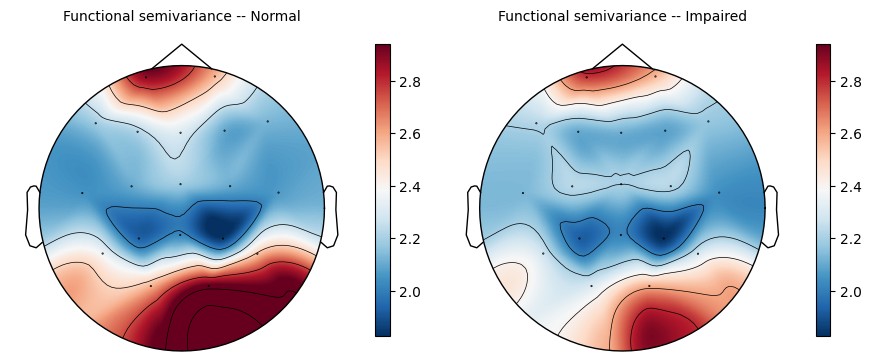

In [56]:
import mne, numpy as np, matplotlib.pyplot as plt, warnings

# --- Proyección 2-D para topomapas: usa POS2D del CONFIG (v29, montaje standard_1020 real).
#     Si no estuviera definida, la reconstruye aquí mismo.
try:
    POS2D
except NameError:
    from mne.channels.layout import _find_topomap_coords
    _L={"T3":"T7","T4":"T8","T5":"P7","T6":"P8"}
    _D={c:c.replace("FZ","Fz").replace("CZ","Cz").replace("PZ","Pz") for c in CANONICAL}
    _CHL=[_D[c] for c in CANONICAL]; _mn=[_L.get(_D[c],_D[c]) for c in CANONICAL]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); _mo=mne.channels.make_standard_montage("standard_1020")
    _info=mne.create_info(_mn,float(TARGET_SFREQ),"eeg"); _info.set_montage(_mo,match_case=False,on_missing="raise")
    _XYZ=np.vstack([_info.get_montage().get_positions()["ch_pos"][ch] for ch in _mn])
    _r,_o,_=mne.bem.fit_sphere_to_headshape(_info,dig_kinds="eeg",units="m",verbose=False)
    _it=mne.create_info(_CHL,float(TARGET_SFREQ),"eeg")
    _it.set_montage(mne.channels.make_dig_montage(ch_pos=dict(zip(_CHL,_XYZ)),coord_frame="head"))
    POS2D=_find_topomap_coords(_it,picks=np.arange(N_CH),sphere=(*_o,_r))
    POS2D=POS2D/np.max(np.linalg.norm(POS2D,axis=1))

def topomap(ax, values, title, cmap="RdBu_r", colorbar=True, vlim=None):
    """Contorno de cabeza AJUSTADO al campo de color: se plotea sobre la proyección 2-D real
    (POS2D) con una esfera de radio 1.05 que abraza los electrodos, y la interpolación se recorta
    al contorno (extrapolate='head'). Así el borde coloreado coincide con el círculo de la cabeza
    y los sensores quedan repartidos, no apiñados al centro."""
    im, _ = mne.viz.plot_topomap(values, POS2D, axes=ax, show=False, cmap=cmap,
                                 contours=6, sensors=True, outlines="head",
                                 extrapolate="head", sphere=(0.0, 0.0, 0.0, 1.05), vlim=vlim)
    ax.set_title(title, fontsize=10)
    if colorbar:
        plt.colorbar(im, ax=ax, shrink=0.75, pad=0.05)
    return im

def channel_semivariance(coef_stack, W):
    acc = np.zeros(N_CH)
    for Z in coef_stack:
        Q = np.einsum('ik,kl,il->i', Z, W, Z)
        Cross = Z @ W @ Z.T
        D2 = np.clip(Q[:,None] + Q[None,:] - 2*Cross, 0, None)
        np.fill_diagonal(D2, 0.0)
        acc += 0.5*D2.sum(1)/(N_CH-1)
    return acc/len(coef_stack)

sv_normal = channel_semivariance(COEF[idx_normal_s], W)
sv_imp    = channel_semivariance(COEF[idx_imp_s], W)
sv_vmin = min(sv_normal.min(), sv_imp.min())
sv_vmax = max(sv_normal.max(), sv_imp.max())

fig, axes = plt.subplots(1, 2, figsize=(9,4.2))
topomap(axes[0], sv_normal, "Functional semivariance -- Normal", vlim=(sv_vmin, sv_vmax))
topomap(axes[1], sv_imp,    "Functional semivariance -- Impaired", vlim=(sv_vmin, sv_vmax))
plt.tight_layout(); plt.show()

## Notas — cómo leer v20

- **El experimento clave de la tesis en v20:** `EXP_NAME` (PSD-funcional, `USE_SPATIAL=True`) vs
  `v19_deep_transformer_cwt` (EEG crudo + CWT) en AUC/F1/recall (Paso 11). Esto responde directamente si
  reemplazar la señal cruda por la representación funcional confirmada (PSD + B-spline) y anclar la
  atención en la geoestadística funcional real aporta sobre la arquitectura original.
- **Segunda comparación clave:** `spatial=on` vs `spatial=off` con `FEATURE_MODE="none"` en ambos casos
  (deja las demás palancas iguales) — aísla el aporte del sesgo `Bspatial` derivado de la geoestadística
  funcional, independiente de cualquier descriptor adicional.
- **Tercera comparación:** `geo` vs `conn` vs `none` (Paso 9/11) — con la métrica de Gram unificada,
  ambos descriptores parten de la misma información funcional; si `geo` supera a `conn` de forma
  creíble (IC de Nadeau-Bengio excluye 0), la organización espacial (no solo la magnitud de la
  conectividad) aporta señal predictiva.
- **Fair comparison con v19:** para que el test pareado de Nadeau-Bengio del Paso 9 sea válido, la
  corrida de v19 que importes en `V19_RESULTS_PATH` debe haber usado el mismo `N_SPLITS=5` y,
  idealmente, el mismo particionado por paciente (mismo `groups`/`y`, es decir, los mismos EDF de 4 s
  de origen). Si cambiaste el preprocesamiento de v19 después de generar esos resultados, vuelve a
  correr `v19_deep_transformer_cwt` sobre el `WIN_DIR`/`ANN_PATH` actuales antes de comparar.
- **Qué se conserva de v19 sin tocar:** CV por paciente (`GroupKFold`), edad como covariable, TTA,
  ensamble homogéneo (`ENSEMBLE_K`), MixUp, guardado de corridas (`cv_results.json`) y el test pareado
  Nadeau-Bengio. Esto es intencional: el único cambio de fondo es *qué* representa la entrada y *de
  dónde* sale el sesgo espacial, no la metodología de validación.

## Adenda v21 — integración con geo v12 (leer junto con las notas de arriba)

- **De dónde salen los datos ahora:** EDF continuo + eventos + `dementia-no-overlap.json`, con
  extracción Eyes-Closed, limpieza ICA (Picard+ICLabel, solo componentes `"brain"`) y QC de época — el
  mismo pipeline confirmado de geo v12, no una copia de EDFs pre-cortados. Esto también significa que el
  tamaño muestral efectivo es menor que en v20 (≈970 sujetos vs. 1187), porque el criterio de calidad es
  más estricto; espera menos ventanas por paciente y verifica que ningún grupo clínico quede
  desproporcionadamente reducido (el resumen impreso en el Paso 2 lo reporta).
- **Confuso de edad — léelo antes de interpretar el Paso 12/13.** Geo v12 confirma que los 3 grupos
  clínicos difieren fuertemente en edad, y que el hallazgo a nivel de ELECTRODO (T6/O1/O2) desaparece
  por completo tras ajustar por edad, mientras que el hallazgo agregado (sill total, rango) se debilita
  pero sobrevive. El clasificador ya usa `USE_AGE=True` (edad como covariable), lo cual mitiga parte del
  problema para la predicción, pero el análisis interpretativo no supervisado del Paso 12 (perfil de
  variograma por banda) **no** ajusta por edad — si vas a reportar esos hallazgos como biomarcador,
  replica el ajuste por edad de la Sección 15.1/18.1 de geo v12 (regresión de cada valor contra la edad
  y análisis sobre los residuos) antes de afirmar que un efecto es "clínico" y no demográfico.
- **Qué NO cambió:** arquitectura (`PSDFuncSTNet`), CV por paciente, TTA/ensamble/MixUp, guardado de
  corridas y test pareado. Si ya corriste v20 y quieres saber si el pipeline confirmado (ICA + parámetros
  multitaper corregidos) por sí solo cambia el accuracy, compara `EXP_NAME` de este notebook contra el de
  v20 con `compare_runs` (mismo `N_SPLITS`, ojo con que los folds ya NO son los mismos pacientes exactos
  porque el criterio de inclusión cambió — repórtalo como comparación no pareada si es el caso).

## Paso 13b — Validación externa / cross-dataset (completada, no solo el *scaffold* de v19)

Entrena en CAUEEG (interno) y evalúa **zero-shot** en el dataset público de AD/FTD de OpenNeuro
(ds004504, el mismo que usó Liu et al.). Es la pieza que más sube la categoría de revisión de un
artículo, y en v19 quedaba sin completar. Puntos importantes de esta versión, adaptada al pipeline
PSD-funcional:

- La PSD externa se calcula con **los mismos parámetros multitaper confirmados** (Paso CONFIG).
- La PSD externa se proyecta sobre la **misma base B-spline y el mismo `λ` ajustados internamente**
  (`Phi_full`, `Ainv_Phit` del Paso 3) — **nunca se re-ajusta la base con datos externos**; si se
  reajustara, ya no sería una prueba zero-shot honesta.
- `Bspatial` del modelo final es el mismo `SPATIAL_C` ya ajustado en el Paso 3b sobre el pool interno
  completo (no se reajusta con datos externos), consistente con "todo lo que ve el modelo en producción
  viene del entrenamiento interno".

In [40]:
!pip -q install datalad datalad-installer
!datalad install -r https://github.com/OpenNeuroDatasets/ds004504.git /content/ds004504
# baja SOLO el preprocesado (más liviano) — o quita 'derivatives' para bajar todo
!cd /content/ds004504 && datalad get participants.tsv derivatives

It is highly recommended to configure Git before using DataLad. Set both 'user.name' and 'user.email' configuration variables.
Cloning:   0% 0.00/2.00 [00:00<?, ? candidates/s]
Enumerating: 0.00 Objects [00:00, ? Objects/s]
                                              
Counting:   0% 0.00/1.19k [00:00<?, ? Objects/s]
                                                
Compressing:   0% 0.00/586 [00:00<?, ? Objects/s]
                                                 
Receiving:   0% 0.00/3.60k [00:00<?, ? Objects/s]
                                                 
Resolving:   0% 0.00/855 [00:00<?, ? Deltas/s]
install(error): /content/ds004504 (dataset) [No working git-annex installation of version >= 10.20230126. Visit http://handbook.datalad.org/r.html?install for instructions on how to install DataLad and git-annex.]
[ERROR  ] datalad.support.exceptions.NoDatasetFound(No installed dataset found at /content/ds004504) (NoDatasetFound) 
usage: datalad install [-h] [-s URL-OR-PATH] [-d DA

In [41]:
!pip -q install awscli
!aws s3 sync --no-sign-request s3://openneuro.org/ds004504 /content/ds004504

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
download: s3://openneuro.org/ds004504/.datalad/config to ds004504/.datalad/config
download: s3://openneuro.org/ds004504/CHANGES to ds004504/CHANGES   
download: s3://openneuro.org/ds004504/README to ds004504/README     
download: s3://openneuro.org/ds004504/.gitattributes to ds004504/.gitattributes
download: s3://openneuro.org/ds004504/dataset_description.json to ds004504/dataset_description.json
download: s3://openneuro.org/ds004504/derivatives/sub-003/eeg/sub-003_task-eyesclosed_eeg.set to ds004504/derivatives/sub-003/eeg/sub-003_task-eyesclosed_eeg.set
download: s3://openneuro.org/ds004504/derivatives/sub-001/eeg/sub-001_task-eyesclosed_eeg.set to ds004504/derivatives/sub-001/eeg/sub-001_task-eyesclosed_eeg.set
downloa

In [42]:
EXTERNAL_DS_ROOT = "/content/ds004504"
EXTERNAL_USE_DERIVATIVES = True   # True = usa el preprocesado de los autores (recomendado)

# Alternativa si datalad falla (a veces más confiable en Colab):
# !pip -q install awscli
# !aws s3 sync --no-sign-request s3://openneuro.org/ds004504 {EXTERNAL_DS_ROOT}

print("existe root:", os.path.isdir(EXTERNAL_DS_ROOT))
print("participants:", os.path.exists(os.path.join(EXTERNAL_DS_ROOT, "participants.tsv")))
import glob as _glob
print("sets:", len(_glob.glob(os.path.join(EXTERNAL_DS_ROOT, "derivatives", "sub-*", "eeg", "*.set"))))

existe root: True
participants: True
sets: 88


In [43]:
import pandas as pd

pt = pd.read_csv(os.path.join(EXTERNAL_DS_ROOT, "participants.tsv"), sep="\t")
grp_ext = dict(zip(pt["participant_id"], pt["Group"]))               # A=Alzheimer, F=FTD, C=Control
age_ext = dict(zip(pt["participant_id"], pt.get("Age", pd.Series())))
BIN_EXT = {"C": 0, "A": 1, "F": 1}                                    # Normal=0 ; Anormal (AD/FTD)=1

def _pick_reorder_external(raw, canonical):
    """Empareja canales por nombre, tolerando MAYUS/minus Y la nomenclatura moderna 10-20
    (T7/T8/P7/P8/Fz/Cz/Pz) que usan la mayoria de datasets BIDS/EEGLAB en vez de los nombres
    clasicos (T3/T4/T5/T6/FZ/CZ/PZ) que trae CAUEEG -- mismo mapeo que ya usa _ica_fit_and_label
    en el Paso 1 para el montaje interno."""
    lower = {ch.lower().replace(".", ""): ch for ch in raw.ch_names}
    order, ok = [], True
    for c in canonical:
        candidates = [c, _MODERN_MONTAGE_MAP.get(c, c)]
        found = next((cand.lower() for cand in candidates if cand.lower() in lower), None)
        if found is None: ok = False; break
        order.append(lower[found])
    if not ok: return None
    raw.pick(order); raw.reorder_channels(order)
    return raw

def _external_subject_to_windows_psd(set_path, sid):
    """Un .set (ya preprocesado por los autores de ds004504) -> PSD por ventana de 4s, MISMOS
    parametros multitaper que el pipeline interno (Paso CONFIG). No aplica ICA propia (los
    derivatives de ds004504 ya vienen limpios); si usas los datos crudos (EXTERNAL_USE_DERIVATIVES
    =False), considera aplicar la misma limpieza ICA del Paso 1 antes de llamar a esta funcion."""
    raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose="ERROR")
    raw = _pick_reorder_external(raw, CANONICAL)
    if raw is None or len(raw.ch_names) != N_CH:
        return None
    raw.filter(l_freq=FILTER_L_FREQ, h_freq=FILTER_H_FREQ, verbose="ERROR")
    raw.set_eeg_reference("average", verbose="ERROR")
    raw.resample(TARGET_SFREQ, verbose="ERROR")
    data = raw.get_data()                                   # [19, T], voltios
    win_samples = int(round(WIN_SEC * TARGET_SFREQ))
    n_win = data.shape[1] // win_samples
    if n_win == 0: return None
    epochs = np.stack([data[:, w*win_samples:(w+1)*win_samples] for w in range(n_win)], 0)
    epochs, _ = _reject_bad_epochs(list(epochs))
    if not epochs: return None
    epochs_arr = np.stack(epochs, 0)
    psd_win, freqs_ext = _epochs_to_psd_per_window(epochs_arr, sfreq=TARGET_SFREQ)
    return psd_win, freqs_ext

def load_external_psd():
    sub = "derivatives" if EXTERNAL_USE_DERIVATIVES else ""
    paths = sorted(glob.glob(os.path.join(EXTERNAL_DS_ROOT, sub, "sub-*", "eeg", "*.set")))
    X_list, y_list, g_list, age_list = [], [], [], []
    freqs_ext_ref = None
    for p in paths:
        sid = [x for x in p.split(os.sep) if x.startswith("sub-")][0]
        if grp_ext.get(sid) not in BIN_EXT:
            continue
        r = _external_subject_to_windows_psd(p, sid)
        if r is None:
            continue
        psd_win, freqs_ext = r
        if freqs_ext.shape != FREQS.shape or not np.allclose(freqs_ext, FREQS, atol=1e-3):
            print(f"  [AVISO] {sid}: grid de frecuencias distinto al interno -- se omite "
                  f"(revisa TARGET_SFREQ/FMIN/FMAX, deben coincidir EXACTO con el Paso CONFIG)")
            continue
        X_list.append(psd_win)
        y_list.append(np.full(psd_win.shape[0], BIN_EXT[grp_ext[sid]], dtype=np.int64))
        g_list.append(np.full(psd_win.shape[0], sid))
        age_list.append(np.full(psd_win.shape[0], float(age_ext.get(sid, 70.0)), dtype=np.float32))
        freqs_ext_ref = freqs_ext
    assert X_list, "no se cargó ningún sujeto externo -- revisa EXTERNAL_DS_ROOT / participants.tsv"
    Xe = np.concatenate(X_list, 0).astype(np.float32)
    ye = np.concatenate(y_list, 0)
    ge = np.concatenate(g_list, 0)
    age_e_raw = np.concatenate(age_list, 0)
    return Xe, ye, ge, age_e_raw

Xe_psd, ye, ge, age_e_raw = load_external_psd()
print("Externo (PSD por ventana):", Xe_psd.shape, "| Anormal:", int((ye>0).sum()), "/", len(ye),
      "| pacientes:", len(set(ge.tolist())))

# --- Proyección sobre la MISMA base B-spline interna (Ainv_Phit del Paso 3) -- NUNCA se reajusta ---
COEF_ext = np.zeros((Xe_psd.shape[0], N_CH, N_BASIS), dtype=np.float32)
for c in range(N_CH):
    COEF_ext[:, c, :] = fit_penalized(Xe_psd[:, c, :])
age_e = ((age_e_raw - 60.0) / 20.0).astype(np.float32)
print("COEF externo:", COEF_ext.shape, "(proyectado sobre la base interna, sin reajustar)")

Externo (PSD por ventana): (16232, 19, 117) | Anormal: 10515 / 16232 | pacientes: 88
COEF externo: (16232, 19, 40) (proyectado sobre la base interna, sin reajustar)


## Paso 13c — Armonización no supervisada (ComBat, batch de referencia)

Corrige el desplazamiento de dominio entre CAUEEG (interno, batch de **referencia**, no se toca) y
ds004504 (externo, batch **objetivo**, se ajusta hacia la escala del interno) sobre los
coeficientes funcionales `COEF`/`COEF_ext`. Solo usa la **edad** como covariable a preservar --
**nunca** las etiquetas diagnósticas del set externo -- así que la evaluación zero-shot que sigue
en el Paso 13b conserva su validez. Referencia: Johnson, Li & Rabinovic (2007); variante de batch
de referencia como en neuroCombat (Fortin et al., 2018) para neuroimagen multi-sitio.

Nota de tamaño de muestra: el batch externo tiene pocas ventanas (n=88 pacientes). La corrección de
Bayes empírico ayuda a estabilizar la estimación pidiendo prestada fuerza estadística entre las
19×`N_BASIS` features, pero aun así trátalo como un experimento exploratorio adicional, no como un
reemplazo garantizado del resultado sin armonizar.

In [44]:
def _combat_reference_batch(Y_ref, X_ref, Y_tgt, X_tgt, eps=1e-8):
    """Y_ref/Y_tgt: [n_muestras, n_features] (referencia=interno, objetivo=externo).
    X_ref/X_tgt: [n_muestras, n_covariables] (aquí: solo edad normalizada, sin columna de
    intercepto -- el intercepto se absorbe en alpha_g). Devuelve Y_tgt armonizado a la escala de
    Y_ref; Y_ref NUNCA se modifica (el modelo ya fue entrenado sobre su distribución original)."""
    n_feat = Y_ref.shape[1]
    Xd_ref = np.concatenate([np.ones((len(X_ref), 1)), X_ref], axis=1)   # [n_ref, 1+ncov]
    Xd_tgt = np.concatenate([np.ones((len(X_tgt), 1)), X_tgt], axis=1)
    alpha = np.zeros((n_feat, Xd_ref.shape[1]))
    sigma_g = np.zeros(n_feat)
    for g in range(n_feat):
        beta_g, *_ = np.linalg.lstsq(Xd_ref, Y_ref[:, g], rcond=None)
        alpha[g] = beta_g
        resid = Y_ref[:, g] - Xd_ref @ beta_g
        sigma_g[g] = resid.std() + eps

    pred_ref = Xd_ref @ alpha.T
    Z_ref = (Y_ref - pred_ref) / sigma_g[None, :]
    pred_tgt = Xd_tgt @ alpha.T
    Z_tgt = (Y_tgt - pred_tgt) / sigma_g[None, :]

    # Parámetros crudos de efecto de batch (por feature) sobre los datos estandarizados.
    gamma_hat = Z_tgt.mean(0)
    delta2_hat = Z_tgt.var(0) + eps

    # Hiperparámetros de los priors (método de momentos), Bayes empírico à la Johnson et al. (2007).
    gamma_bar, tau2 = gamma_hat.mean(), gamma_hat.var() + eps
    m_d, v_d = delta2_hat.mean(), delta2_hat.var() + eps
    lam_d = (2 * v_d + m_d ** 2) / v_d
    th_d = (m_d ** 3 + m_d * v_d) / v_d

    gamma_star, delta2_star = gamma_hat.copy(), delta2_hat.copy()
    n_tgt = len(X_tgt)
    for _ in range(30):
        gamma_star = (n_tgt * tau2 * gamma_hat + delta2_star * gamma_bar) / (n_tgt * tau2 + delta2_star)
        ss = ((Z_tgt - gamma_star[None, :]) ** 2).sum(0)
        delta2_star = (0.5 * ss + th_d) / (n_tgt / 2 + lam_d - 1)

    Z_tgt_adj = (Z_tgt - gamma_star[None, :]) / np.sqrt(np.clip(delta2_star, eps, None))[None, :]
    Y_tgt_combat = Z_tgt_adj * sigma_g[None, :] + pred_tgt
    return Y_tgt_combat.astype(np.float32)


# Aplanamos [N, 19, n_basis] -> [N, 19*n_basis]: cada (canal, coeficiente) es una feature separada.
Y_ref_flat = COEF.reshape(len(COEF), -1).astype(np.float64)
Y_tgt_flat = COEF_ext.reshape(len(COEF_ext), -1).astype(np.float64)
X_ref_age = ages.reshape(-1, 1).astype(np.float64)
X_tgt_age = age_e.reshape(-1, 1).astype(np.float64)

COEF_ext_combat_flat = _combat_reference_batch(Y_ref_flat, X_ref_age, Y_tgt_flat, X_tgt_age)
COEF_ext_combat = COEF_ext_combat_flat.reshape(COEF_ext.shape)

print("ComBat aplicado: coeficientes externos armonizados hacia la escala del batch interno "
      f"(referencia), usando solo edad como covariable preservada -- "
      f"{Y_ref_flat.shape[1]} features (19 canales x {N_BASIS} coeficientes), "
      f"n_ref={len(Y_ref_flat)}, n_tgt={len(Y_tgt_flat)}.")


ComBat aplicado: coeficientes externos armonizados hacia la escala del batch interno (referencia), usando solo edad como covariable preservada -- 760 features (19 canales x 40 coeficientes), n_ref=77715, n_tgt=16232.


In [45]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

def make_cosine_warmup(optimizer, warmup_epochs, total_epochs):
    def _lr_lambda(ep):
        if ep < warmup_epochs:
            return (ep + 1) / max(1, warmup_epochs)
        prog = (ep - warmup_epochs) / max(1, total_epochs - warmup_epochs)
        return 0.5 * (1 + np.cos(np.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, _lr_lambda)

In [46]:
# --- Entrena un PEQUEÑO ENSAMBLE (en vez de un solo modelo) sobre TODO el interno, para poder
# reportar incertidumbre en la validación externa (holdout 15% para early stopping + calibración
# de temperatura). Usa AUC de validación para seleccionar checkpoint (Paso 7) y el schedule coseno
# con warmup (WARMUP_EPOCHS, Paso CONFIG). ---
FINAL_ENSEMBLE_K = 3
idx_all = np.arange(len(y))
tr_idx_f, val_idx_f = next(GroupShuffleSplit(1, test_size=0.15, random_state=42).split(idx_all, groups=groups))

print("Bspatial usado para el modelo final: SPATIAL_C del Paso 3b (media off-diag = "
      f"{SPATIAL_C[~np.eye(N_CH, dtype=bool)].mean():.3f})")

cnt = Counter(y[tr_idx_f].tolist())
cw = torch.tensor([1.0/cnt.get(c,1) for c in range(NUM_CLASSES)], dtype=torch.float32)
cw = (cw/cw.sum()*NUM_CLASSES).to(device)
criterion = lambda out, yb: F.cross_entropy(out, yb, weight=cw)

final_models, final_temperatures = [], []
for k in range(FINAL_ENSEMBLE_K):
    torch.manual_seed(k); np.random.seed(k)
    m_final = build_model()
    opt = torch.optim.AdamW(m_final.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = make_cosine_warmup(opt, WARMUP_EPOCHS, CV_EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
    trl = make_loader(tr_idx_f, augment=True, shuffle=True)
    val = make_loader(val_idx_f, augment=False, shuffle=False)
    best, bad, path_final = -1.0, 0, f"external_zeroshot_full_model_m{k}_v22.pt"
    for ep in range(1, CV_EPOCHS + 1):
        run_epoch(m_final, trl, criterion, opt, scaler, mixup_alpha=MIXUP_ALPHA)
        _, vauc = eval_epoch_auc(m_final, val); sch.step()
        if vauc > best + 1e-4:
            best, bad = vauc, 0; torch.save(m_final.state_dict(), path_final)
        else:
            bad += 1
            if bad >= CV_PATIENCE: break
    m_final.load_state_dict(torch.load(path_final))
    inspect_spatial_gates(m_final, label=f"external_final_m{k}")
    val_logits, val_y = collect_logits(m_final, val_idx_f)
    T = fit_temperature(val_logits, val_y)
    print(f"  Modelo final #{k}: val AUC = {best:.4f} | temperatura calibrada T = {T:.3f}")
    final_models.append(m_final); final_temperatures.append(T)

print(f"\n{FINAL_ENSEMBLE_K} modelos finales entrenados sobre {len(tr_idx_f)} ventanas internas.")


# --- Evaluación zero-shot en el externo: ensamble + calibración de temperatura + incertidumbre ---
@torch.no_grad()
def evaluate_external_ensemble(models, temperatures, COEF_ext_eval, ye, ge, age_e, bs=256, label=""):
    """Promedia las probabilidades (ya calibradas por temperatura) de varios modelos finales, y
    reporta también la desviación estándar entre miembros por paciente como medida de
    incertidumbre -- un clínico puede decidir distinto ante 'probable impaired, alta confianza'
    frente a 'probable impaired, baja confianza'."""
    all_member_p = []
    for model, T in zip(models, temperatures):
        model.eval(); probs = []
        for i in range(0, len(COEF_ext_eval), bs):
            zb = torch.from_numpy(COEF_ext_eval[i:i+bs]).float().to(device)
            ab = torch.from_numpy(age_e[i:i+bs]).float().to(device)
            if USE_AMP and device.type == "cuda":
                with torch.amp.autocast("cuda", dtype=amp_dtype):
                    out, _ = model(zb, ab)
            else:
                out, _ = model(zb, ab)
            probs.append(torch.softmax(out.float() / T, 1)[:, 1].cpu().numpy())
        all_member_p.append(np.concatenate(probs))
    chunk_p = np.mean(all_member_p, axis=0)
    chunk_p_std = np.std(all_member_p, axis=0)
    df = pd.DataFrame({"g": ge, "p": chunk_p, "p_std": chunk_p_std, "y": ye}).groupby("g").agg(
        {"p": "mean", "p_std": "mean", "y": "first"})
    pr = (df.p.values >= 0.5).astype(int)
    tp = int(((pr==1)&(df.y.values==1)).sum()); tn = int(((pr==0)&(df.y.values==0)).sum())
    fp = int(((pr==1)&(df.y.values==0)).sum()); fn = int(((pr==0)&(df.y.values==1)).sum())
    auc  = roc_auc_score(df.y, df.p) if len(set(df.y)) > 1 else float("nan")
    sens = tp/(tp+fn+1e-8); spec = tn/(tn+fp+1e-8); acc_ = (tp+tn)/len(df)
    print(f"EXTERNO {label} | AUC: {auc:.4f} | acc: {acc_:.4f} | sens: {sens:.4f} | "
          f"spec: {spec:.4f} | pacientes: {len(df)} | incertidumbre media (std entre miembros): "
          f"{df.p_std.mean():.4f}")
    return df, dict(auc=auc, acc=acc_, sens=sens, spec=spec, n=len(df), unc=float(df.p_std.mean()))


print("\n--- (a) Sin armonizar (comparable con el número ya reportado en el paper) ---")
df_ext_raw, metrics_ext_raw = evaluate_external_ensemble(
    final_models, final_temperatures, COEF_ext, ye, ge, age_e, label="(a) sin ComBat")

print("\n--- (b) Con armonización ComBat (no supervisada, batch de referencia) ---")
df_ext_combat, metrics_ext_combat = evaluate_external_ensemble(
    final_models, final_temperatures, COEF_ext_combat, ye, ge, age_e, label="(b) con ComBat")

print("\nLectura honesta: sigue siendo UN solo dataset externo -- no hay folds para Nadeau-Bengio")
print("aquí. Repórtalo como punto estimado con el tamaño muestral (n pacientes externos), y compara")
print("(a) vs (b) como evidencia exploratoria de si la armonización ayuda con el domain shift, no")
print("como una mejora garantizada dado el tamaño chico del set externo (n=88). La calibración de")
print("temperatura (T por modelo) no cambia el AUC -- solo hace que las probabilidades reportadas")
print("sean honestas fuera del dominio de entrenamiento, que es lo que importa para uso clínico real.")


Bspatial usado para el modelo final: SPATIAL_C del Paso 3b (media off-diag = 0.199)
  [external_final_m0] t1.lam por cabeza: [-0.176  -0.1347 -0.1409 -0.146 ] (media |lam| = 0.1494)
  [external_final_m0] t2.lam por cabeza: [-0.0369 -0.0649 -0.0925 -0.1207] (media |lam| = 0.0787)
  Modelo final #0: val AUC = 0.7861 | temperatura calibrada T = 1.515
  [external_final_m1] t1.lam por cabeza: [-0.0873 -0.0952 -0.1105 -0.0889] (media |lam| = 0.0955)
  [external_final_m1] t2.lam por cabeza: [-0.0528 -0.0459 -0.0763 -0.0936] (media |lam| = 0.0671)
  Modelo final #1: val AUC = 0.7793 | temperatura calibrada T = 1.528
  [external_final_m2] t1.lam por cabeza: [-0.0471 -0.0378 -0.079  -0.0475] (media |lam| = 0.0529)
  [external_final_m2] t2.lam por cabeza: [-0.0128 -0.0178 -0.0229 -0.0489] (media |lam| = 0.0256)
  Modelo final #2: val AUC = 0.7833 | temperatura calibrada T = 1.421

3 modelos finales entrenados sobre 65678 ventanas internas.

--- (a) Sin armonizar (comparable con el número ya repor

# Paso 14 — Arquitecturas alternativas: los tres cambios discutidos

Esta sección es **aditiva y autocontenida**: no modifica nada de los Pasos 1-13. Implementa los
tres cambios discutidos para que el uso de un Transformer se justifique mejor:

- **14a — Tokens banda×canal**: en vez de 19 tokens (uno por canal, banda ancha 1-30Hz), usa
  `19 × N_BANDS` tokens (uno por combinación canal-banda), dándole a la atención objetos
  heterogéneos entre sí que comparar, y conectando la arquitectura con el propio hallazgo
  dosis-respuesta por banda (Tabla V).
- **14b — Tokens canal×tiempo (chunks temporales)**: agrupa ventanas de 4s consecutivas del mismo
  sujeto en un contexto más largo, dándole a la atención dinámica temporal real que modelar (más
  cercano al diseño de STCWTNet), sin necesitar reprocesar los EDF crudos.
- **14c — Pooling de ventana→paciente aprendido**: reemplaza el promedio post-hoc por una capa de
  atención entrenada sobre las features congeladas de un modelo ya entrenado.

**Advertencia honesta:** este código no pudo ejecutarse ni probarse contra tus datos reales (sin
GPU ni acceso a tu Drive en este entorno). Es probable que aparezca algún error de forma/shape o
de nombre de variable la primera vez que lo corras -- si eso pasa, pega el traceback completo y lo
corrijo. El Paso 1-13 original queda intacto como respaldo si alguna de estas variantes falla o no
mejora el resultado.

## Paso 14a.1 — Coeficientes funcionales por banda (para tokens banda×canal)

Ajusta un B-spline chico *por banda* (reutilizando exactamente `design_matrix`, `penalty_matrix` y
`best_lambda` del Paso 3, solo que restringidos a la sub-rejilla de frecuencia de cada banda), en
vez de reutilizar el ajuste de banda ancha (1-30Hz) ya calculado en `COEF`. Usa las mismas 4 bandas
que ya definiste en `GEO_BANDS` (low/theta/alpha/beta) -- **no incluye gamma**, porque este
notebook solo calcula PSD hasta `FMAX` Hz y no hay contenido de gamma real que tokenizar.

In [47]:
N_BASIS_BAND = 10  # basis chica por banda -- no hace falta tanta resolución como en banda ancha
GEO_BAND_LIST = list(GEO_BANDS.items())
N_BANDS = len(GEO_BAND_LIST)
print(f"Bandas para tokens banda×canal: {[n for n,_ in GEO_BAND_LIST]} (N_BANDS={N_BANDS})")
print(f"Nota: sin gamma -- este pipeline solo analiza PSD hasta FMAX={FMAX:.0f} Hz.")

band_bases = {}
_rng_band = np.random.default_rng(0)
for name, (lo, hi) in GEO_BAND_LIST:
    idx = np.where((FREQS >= lo) & (FREQS < hi))[0]
    assert len(idx) > BSPLINE_ORDER, (
        f"banda '{name}' tiene muy pocos puntos de frecuencia ({len(idx)}) para un B-spline de "
        f"orden {BSPLINE_ORDER} -- revisa la resolución de FREQS antes de continuar.")
    nb_band = max(BSPLINE_ORDER, min(N_BASIS_BAND, len(idx) - 2))
    basis_b = BSplineBasis(domain_range=(float(FREQS[idx].min()), float(FREQS[idx].max())),
                            n_basis=nb_band, order=BSPLINE_ORDER)
    Phi_b = design_matrix(basis_b, FREQS[idx])
    Pmat_b = penalty_matrix(basis_b)
    flat_band = X_psd[:, :, idx].reshape(-1, len(idx))
    sample_b = flat_band[_rng_band.choice(len(flat_band), size=min(FUNC_FIT_SAMPLE, len(flat_band)), replace=False)]
    lam_b, gcv_b, edf_b, _ = best_lambda(Phi_b, sample_b, Pmat_b, grid=LAMBDA_GRID)
    A_b = Phi_b.T @ Phi_b + lam_b * Pmat_b
    Ainv_Phit_b = np.linalg.solve(A_b, Phi_b.T)
    band_bases[name] = dict(idx=idx, n_basis=nb_band, lam=lam_b, edf=edf_b, Ainv_Phit=Ainv_Phit_b)
    print(f"  {name:6s} [{lo:.0f}-{hi:.0f}Hz, {len(idx)} pts]: n_basis={nb_band} | "
          f"lambda*={lam_b:.2e} | edf={edf_b:.1f} | GCV={gcv_b:.4f}")

COEF_BAND_PATH = os.path.join(CACHE_DIR, f"coef_band_v23_nb{N_BASIS_BAND}.npy")
if os.path.exists(COEF_BAND_PATH):
    COEF_BAND = np.load(COEF_BAND_PATH)
    print("Coeficientes por banda cacheados ->", COEF_BAND_PATH)
else:
    n_win = X_psd.shape[0]
    COEF_BAND = np.zeros((n_win, N_CH, N_BANDS, N_BASIS_BAND), dtype=np.float32)
    for bi, (name, _) in enumerate(GEO_BAND_LIST):
        idx = band_bases[name]["idx"]; nb_b = band_bases[name]["n_basis"]
        Ainv_b = band_bases[name]["Ainv_Phit"]
        for c in range(N_CH):
            coef_c = (Ainv_b @ X_psd[:, c, idx].T).T           # [n_win, nb_b]
            COEF_BAND[:, c, bi, :nb_b] = coef_c
    np.save(COEF_BAND_PATH, COEF_BAND)
    print("Coeficientes por banda calculados y cacheados ->", COEF_BAND_PATH)

print("COEF_BAND:", COEF_BAND.shape, "(ventanas, canales, bandas, n_basis_band)")


Bandas para tokens banda×canal: ['low', 'theta', 'alpha', 'beta'] (N_BANDS=4)
Nota: sin gamma -- este pipeline solo analiza PSD hasta FMAX=30 Hz.
  low    [1-4Hz, 12 pts]: n_basis=10 | lambda*=3.98e-03 | edf=6.2 | GCV=0.0067
  theta  [4-8Hz, 16 pts]: n_basis=10 | lambda*=3.98e-03 | edf=7.4 | GCV=0.0060
  alpha  [8-13Hz, 20 pts]: n_basis=10 | lambda*=7.94e-03 | edf=7.6 | GCV=0.0075
  beta   [13-30Hz, 68 pts]: n_basis=10 | lambda*=3.16e-02 | edf=9.7 | GCV=0.0118
Coeficientes por banda cacheados -> /content/drive/MyDrive/Carpeta_Doctorado/cache_stcwt_psd_v21/coef_band_v23_nb10.npy
COEF_BAND: (77715, 19, 4, 10) (ventanas, canales, bandas, n_basis_band)


## Paso 14a.2 — Modelo con tokens banda×canal, y CV

`Bspatial` se extiende bloque a bloque: entre dos tokens de la **misma** banda se usa el kernel
geoestadístico de distancia entre electrodos tal cual (idéntico al modelo original); entre tokens
de bandas **distintas** se usa el mismo kernel pero atenuado por `band_cross_discount` -- favorece
que la atención compare primero dentro de la misma banda, sin bloquear del todo la comparación
entre bandas (por ejemplo, si la coherencia alpha-beta importa).

In [48]:
class PSDFuncSTNet_BandTokens(nn.Module):
    """Variante con tokens banda×canal (Cambio 1)."""
    def __init__(s, n_basis_band, n_ch, n_bands, spatial_C, use_age=True, use_spatial=True,
                 hidden=32, d_model=128, num_heads=4, ff_dim=256, num_classes=2, dropout=0.4,
                 band_cross_discount=0.3):
        super().__init__()
        s.use_age, s.n_ch, s.n_bands = use_age, n_ch, n_bands
        n_tok = n_ch * n_bands
        s.enc = nn.Sequential(nn.LayerNorm(n_basis_band), nn.Linear(n_basis_band, hidden), nn.GELU())
        s.band_embed = nn.Embedding(n_bands, hidden)
        s.tok = nn.Sequential(nn.Linear(hidden, d_model), nn.LayerNorm(d_model), nn.ReLU(), nn.Dropout(dropout))
        Bspatial_full = np.zeros((n_tok, n_tok), dtype=np.float32)
        for bi in range(n_bands):
            for bj in range(n_bands):
                block = spatial_C.copy() if bi == bj else spatial_C * band_cross_discount
                Bspatial_full[bi*n_ch:(bi+1)*n_ch, bj*n_ch:(bj+1)*n_ch] = block
        s.register_buffer("Bspatial", torch.from_numpy(Bspatial_full))
        s.t1 = SpatialTransformerBlock(d_model, num_heads, ff_dim, dropout, use_spatial)
        s.t2 = SpatialTransformerBlock(d_model, num_heads, ff_dim, dropout, use_spatial)
        s.ap = nn.AdaptiveAvgPool1d(1); s.mp = nn.AdaptiveMaxPool1d(1)
        inf = d_model * 2 + (1 if use_age else 0)
        s.head = nn.Linear(inf, num_classes)

    def forward(s, coef_band, age):   # coef_band: [B, n_ch, n_bands, n_basis_band]
        B = coef_band.shape[0]
        x = coef_band.permute(0, 2, 1, 3).reshape(B, s.n_bands * s.n_ch, -1)   # orden: banda, canal
        h = s.enc(x)
        band_ids = torch.arange(s.n_bands, device=x.device).repeat_interleave(s.n_ch)
        h = h + s.band_embed(band_ids)[None, :, :]
        h = s.tok(h)
        h, _ = s.t1(h, s.Bspatial); h, a = s.t2(h, s.Bspatial)
        ht = h.transpose(1, 2)
        feat = torch.cat([s.ap(ht).squeeze(-1), s.mp(ht).squeeze(-1)], 1)
        if s.use_age: feat = torch.cat([feat, age.unsqueeze(1)], 1)
        return s.head(feat), a


def build_model_bandtokens():
    return PSDFuncSTNet_BandTokens(N_BASIS_BAND, N_CH, N_BANDS, SPATIAL_C, use_age=USE_AGE,
                                    use_spatial=USE_SPATIAL, hidden=HIDDEN, d_model=D_MODEL,
                                    num_heads=NUM_HEADS, ff_dim=FF_DIM, num_classes=NUM_CLASSES,
                                    dropout=DROPOUT).to(device)


_mbt = build_model_bandtokens()
print(f"PSDFuncSTNet_BandTokens: {round(sum(p.numel() for p in _mbt.parameters())/1e6, 3)} M params "
      f"| tokens = {N_CH}×{N_BANDS} = {N_CH*N_BANDS}")
_out_bt, _a_bt = _mbt(torch.randn(4, N_CH, N_BANDS, N_BASIS_BAND).to(device), torch.zeros(4).to(device))
print("salida:", _out_bt.shape, "| atención:", _a_bt.shape)
del _mbt


class CachedFuncDatasetBand(Dataset):
    def __init__(self, COEF_BAND, y, ages, indices, augment=False):
        self.COEF_BAND, self.y, self.ages, self.idx, self.augment = COEF_BAND, y, ages, indices, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; z = np.array(self.COEF_BAND[j], dtype=np.float32)   # [n_ch, n_bands, n_basis_band]
        if self.augment: z = augment_coef_band(z)
        return torch.from_numpy(z).float(), torch.tensor(self.ages[j]).float(), int(self.y[j])


def augment_coef_band(z):
    """Misma filosofía que augment_coef: jitter gaussiano + dropout de canal (igual en todas las
    bandas de ese canal, simulando un electrodo ruidoso/desconectado real) + mezcla leve entre
    bandas vecinas."""
    s = AUG_STRENGTH
    if np.random.rand() < 0.7:
        z = z + np.random.randn(*z.shape).astype(np.float32) * (z.std() + 1e-6) * 0.05 * s
    if np.random.rand() < 0.3:
        ch = np.random.choice(N_CH, np.random.randint(1, 3), replace=False)
        z[ch] = 0.0
    if np.random.rand() < 0.3:
        shift = np.roll(z, 1, axis=1)
        lam_mix = np.random.uniform(0.0, 0.15) * s
        z = (1 - lam_mix) * z + lam_mix * shift
    return z


def make_loader_band(indices, augment, shuffle):
    ds = CachedFuncDatasetBand(COEF_BAND, y, ages, indices, augment=augment)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=NUM_WORKERS,
                       pin_memory=True, persistent_workers=NUM_WORKERS > 0)


@torch.no_grad()
def patient_probs_band(model, indices, tta=None):
    tta_n = (TTA_N if USE_TTA else 1) if tta is None else tta
    acc = _chunk_probs_once(model, make_loader_band(indices, augment=False, shuffle=False)); n = 1
    if tta_n > 1:
        loaderA = make_loader_band(indices, augment=True, shuffle=False)
        for _ in range(tta_n - 1):
            acc = acc + _chunk_probs_once(model, loaderA); n += 1
    chunk_p = acc / n
    serials = groups[indices]; pat = defaultdict(list)
    for p, s_ in zip(chunk_p, serials): pat[s_].append(p)
    return {k: float(np.mean(v)) for k, v in pat.items()}


def run_cv_bandtokens(n_splits=N_SPLITS, epochs=CV_EPOCHS, patience=CV_PATIENCE):
    gkf = GroupKFold(n_splits=n_splits); idx_all = np.arange(len(y)); fold_metrics = []
    for fold, (trv, test_idx) in enumerate(gkf.split(idx_all, y, groups), 1):
        tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=0.15, random_state=42).split(trv, groups=groups[trv]))
        tr_idx, val_idx = trv[tr_rel], trv[va_rel]
        cnt = Counter(y[tr_idx].tolist())
        cw = torch.tensor([1.0/cnt.get(c, 1) for c in range(NUM_CLASSES)], dtype=torch.float32)
        cw = (cw/cw.sum()*NUM_CLASSES).to(device)
        criterion = lambda out, yb: F.cross_entropy(out, yb, weight=cw)
        member_dicts = []
        for k in range(ENSEMBLE_K):
            torch.manual_seed(3000*fold + k); np.random.seed(3000*fold + k)
            model = build_model_bandtokens()
            opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            sch = make_cosine_warmup(opt, WARMUP_EPOCHS, epochs)
            scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
            trl = make_loader_band(tr_idx, augment=True, shuffle=True)
            val = make_loader_band(val_idx, augment=False, shuffle=False)
            best, bad, path = -1.0, 0, f"fold{fold}_bandtok_m{k}_v23.pt"
            for ep in range(1, epochs + 1):
                run_epoch(model, trl, criterion, opt, scaler, mixup_alpha=MIXUP_ALPHA)
                _, vauc = eval_epoch_auc(model, val); sch.step()
                if vauc > best + 1e-4:
                    best, bad = vauc, 0; torch.save(model.state_dict(), path)
                else:
                    bad += 1
                    if bad >= patience: break
            model.load_state_dict(torch.load(path))
            member_dicts.append(patient_probs_band(model, test_idx))
            del model; torch.cuda.empty_cache() if device.type == "cuda" else None
        d = ensemble_probdict(member_dicts) if len(member_dicts) > 1 else member_dicts[0]
        m = metrics_from_probdict(d); fold_metrics.append(m)
        print(f"  Fold {fold} (banda×canal): AUC {m['auc']:.4f} | acc {m['acc']:.4f} | F1 {m['f1']:.4f} | "
              f"sens {m['sens']:.4f} | spec {m['spec']:.4f}")
    return fold_metrics


print("Corriendo CV con tokens banda×canal:")
metrics_bandtokens = run_cv_bandtokens()
save_run(EXP_NAME + "_band_channel_tokens", metrics_bandtokens)


PSDFuncSTNet_BandTokens: 0.27 M params | tokens = 19×4 = 76
salida: torch.Size([4, 2]) | atención: torch.Size([4, 4, 76, 76])
Corriendo CV con tokens banda×canal:
  Fold 1 (banda×canal): AUC 0.8268 | acc 0.7680 | F1 0.8035 | sens 0.7667 | spec 0.7703
  Fold 2 (banda×canal): AUC 0.8218 | acc 0.7577 | F1 0.7892 | sens 0.7719 | spec 0.7375
  Fold 3 (banda×canal): AUC 0.8447 | acc 0.7835 | F1 0.8073 | sens 0.8148 | spec 0.7442
  Fold 4 (banda×canal): AUC 0.8462 | acc 0.7784 | F1 0.8089 | sens 0.8198 | spec 0.7229
  Fold 5 (banda×canal): AUC 0.8087 | acc 0.7474 | F1 0.7932 | sens 0.7642 | spec 0.7183
Guardado 'psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3_band_channel_tokens' (5 folds). Corridas disponibles: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_featconn_spatialoff', 'v19_binary_wi

In [49]:
import os, json
RESULTS_PATH = os.path.join(CACHE_DIR, "cv_results.json")
def save_run(name, metrics):
    db = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
    db[name] = {k: [float(m[k]) for m in metrics] for k in metrics[0].keys()}
    db[name]["_n_splits"] = N_SPLITS
    json.dump(db, open(RESULTS_PATH, "w"), indent=2)
    print(f"Guardado '{name}' ({len(metrics)} folds). Corridas disponibles:", list(db.keys()))

save_run(EXP_NAME + "_band_channel_tokens", metrics_bandtokens)

Guardado 'psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3_band_channel_tokens' (5 folds). Corridas disponibles: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_featconn_spatialoff', 'v19_binary_win2s_ageon_featphase_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_tta0_ens1', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontraw_tta8_ens3', 'v19_deep_transformer_cwt', 'v19_deep_transformer_raw', 'v19_ml_logreg', 'v19_ml_svm_rbf', 'v19_ml_random_forest', 'v19_ml_hist_gb', 'v19_binary_win2s_ageon_featgeo_spatialoff_frontcwt_tta8_ens3', 'v19_binary_win2s_ageon_featnone_spatialoff_frontcwt_bbstcwt_tta8_ens3', 'v19_binary_win4s_ageon_featnone_spatialoff_frontcwt_bbstc

## Paso 14b.1 — Chunks temporales (para tokens canal×tiempo)

En vez de reprocesar los EDF crudos con una ventana más fina (caro: requiere re-correr el Paso 1-2
completo), agrupa `T_LEN` ventanas de 4s **consecutivas del mismo sujeto** -- ya en `COEF`, en el
orden en que fueron grabadas -- dando un contexto temporal de `T_LEN×4` segundos por muestra. Con
`stride=1` los chunks se solapan (más muestras de entrenamiento); ningún chunk mezcla ventanas de
sujetos distintos, así que el agrupamiento por paciente en la CV sigue siendo válido.

In [50]:
T_LEN = 3  # ventanas de 4s consecutivas por muestra -> 12s de contexto temporal

def build_temporal_chunks(COEF, groups, y, ages, t_len=T_LEN, stride=1):
    """Agrupa ventanas consecutivas del MISMO sujeto (respetando el orden ya preservado en COEF/
    groups desde el Paso 1-2) en chunks de longitud t_len."""
    chunk_starts = []
    n = len(groups); i = 0
    while i < n:
        j = i
        while j < n and groups[j] == groups[i]:
            j += 1
        for start in range(i, j - t_len + 1, stride):
            chunk_starts.append(start)
        i = j
    chunk_starts = np.array(chunk_starts, dtype=np.int64)
    assert len(chunk_starts) > 0, (
        f"no se formó ningún chunk de longitud {t_len} -- ¿algún sujeto tiene menos de {t_len} "
        f"ventanas? Baja T_LEN o revisa el Paso 1-2.")
    COEF_SEQ = np.stack([COEF[s:s+t_len] for s in chunk_starts], axis=0)   # [n_chunks, t_len, n_ch, n_basis]
    y_seq = y[chunk_starts + t_len - 1]
    groups_seq = groups[chunk_starts]
    ages_seq = ages[chunk_starts]
    return COEF_SEQ, y_seq, groups_seq, ages_seq


COEF_SEQ, y_seq, groups_seq, ages_seq = build_temporal_chunks(COEF, groups, y, ages, t_len=T_LEN, stride=1)
print(f"Chunks temporales: {COEF_SEQ.shape} (de {len(COEF)} ventanas originales -> "
      f"{len(COEF_SEQ)} chunks de {T_LEN} ventanas consecutivas, stride=1, "
      f"{len(set(groups_seq.tolist()))} pacientes)")


Chunks temporales: (75775, 3, 19, 40) (de 77715 ventanas originales -> 75775 chunks de 3 ventanas consecutivas, stride=1, 966 pacientes)


## Paso 14b.2 — Modelo con tokens canal×tiempo, y CV

Misma idea de `Bspatial` extendido por bloques que en 14a, pero ahora el eje extendido es el
tiempo (cada paso temporal es un bloque con el kernel geoestadístico completo dentro de sí mismo, y
atenuado -- `time_cross_discount` -- entre pasos temporales distintos).

In [51]:
class PSDFuncSTNet_TemporalChunks(nn.Module):
    """Variante con tokens canal×tiempo (Cambio 2): agrupa T_LEN ventanas consecutivas para darle
    a la atención dinámica temporal real que modelar, acercando el diseño al channel-wise
    transformer de STCWTNet (Liu et al., 2026), sin reprocesar los EDF crudos."""
    def __init__(s, n_basis, n_ch, t_len, spatial_C, use_age=True, use_spatial=True,
                 hidden=32, d_model=128, num_heads=4, ff_dim=256, num_classes=2, dropout=0.4,
                 time_cross_discount=0.5):
        super().__init__()
        s.use_age, s.n_ch, s.t_len = use_age, n_ch, t_len
        n_tok = n_ch * t_len
        s.enc = nn.Sequential(nn.LayerNorm(n_basis), nn.Linear(n_basis, hidden), nn.GELU())
        s.time_embed = nn.Embedding(t_len, hidden)
        s.tok = nn.Sequential(nn.Linear(hidden, d_model), nn.LayerNorm(d_model), nn.ReLU(), nn.Dropout(dropout))
        Bspatial_full = np.zeros((n_tok, n_tok), dtype=np.float32)
        for ti in range(t_len):
            for tj in range(t_len):
                block = spatial_C.copy() if ti == tj else spatial_C * time_cross_discount
                Bspatial_full[ti*n_ch:(ti+1)*n_ch, tj*n_ch:(tj+1)*n_ch] = block
        s.register_buffer("Bspatial", torch.from_numpy(Bspatial_full))
        s.t1 = SpatialTransformerBlock(d_model, num_heads, ff_dim, dropout, use_spatial)
        s.t2 = SpatialTransformerBlock(d_model, num_heads, ff_dim, dropout, use_spatial)
        s.ap = nn.AdaptiveAvgPool1d(1); s.mp = nn.AdaptiveMaxPool1d(1)
        inf = d_model * 2 + (1 if use_age else 0)
        s.head = nn.Linear(inf, num_classes)

    def forward(s, coef_seq, age):   # coef_seq: [B, t_len, n_ch, n_basis]
        B = coef_seq.shape[0]
        x = coef_seq.reshape(B, s.t_len * s.n_ch, -1)
        h = s.enc(x)
        time_ids = torch.arange(s.t_len, device=x.device).repeat_interleave(s.n_ch)
        h = h + s.time_embed(time_ids)[None, :, :]
        h = s.tok(h)
        h, _ = s.t1(h, s.Bspatial); h, a = s.t2(h, s.Bspatial)
        ht = h.transpose(1, 2)
        feat = torch.cat([s.ap(ht).squeeze(-1), s.mp(ht).squeeze(-1)], 1)
        if s.use_age: feat = torch.cat([feat, age.unsqueeze(1)], 1)
        return s.head(feat), a


def build_model_temporal():
    return PSDFuncSTNet_TemporalChunks(N_BASIS, N_CH, T_LEN, SPATIAL_C, use_age=USE_AGE,
                                        use_spatial=USE_SPATIAL, hidden=HIDDEN, d_model=D_MODEL,
                                        num_heads=NUM_HEADS, ff_dim=FF_DIM, num_classes=NUM_CLASSES,
                                        dropout=DROPOUT).to(device)


_mtm = build_model_temporal()
print(f"PSDFuncSTNet_TemporalChunks: {round(sum(p.numel() for p in _mtm.parameters())/1e6, 3)} M params "
      f"| tokens = {N_CH}×{T_LEN} = {N_CH*T_LEN}")
_out_tm, _a_tm = _mtm(torch.randn(4, T_LEN, N_CH, N_BASIS).to(device), torch.zeros(4).to(device))
print("salida:", _out_tm.shape, "| atención:", _a_tm.shape)
del _mtm


class CachedFuncDatasetSeq(Dataset):
    def __init__(self, COEF_SEQ, y_seq, ages_seq, indices, augment=False):
        self.COEF_SEQ, self.y, self.ages, self.idx, self.augment = COEF_SEQ, y_seq, ages_seq, indices, augment
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; z = np.array(self.COEF_SEQ[j], dtype=np.float32)   # [t_len, n_ch, n_basis]
        if self.augment:
            for t in range(z.shape[0]):
                z[t] = augment_coef(z[t])
        return torch.from_numpy(z).float(), torch.tensor(self.ages[j]).float(), int(self.y[j])


def make_loader_seq(indices, augment, shuffle):
    ds = CachedFuncDatasetSeq(COEF_SEQ, y_seq, ages_seq, indices, augment=augment)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=NUM_WORKERS,
                       pin_memory=True, persistent_workers=NUM_WORKERS > 0)


@torch.no_grad()
def patient_probs_seq(model, indices, tta=None):
    tta_n = (TTA_N if USE_TTA else 1) if tta is None else tta
    acc = _chunk_probs_once(model, make_loader_seq(indices, augment=False, shuffle=False)); n = 1
    if tta_n > 1:
        loaderA = make_loader_seq(indices, augment=True, shuffle=False)
        for _ in range(tta_n - 1):
            acc = acc + _chunk_probs_once(model, loaderA); n += 1
    chunk_p = acc / n
    serials = groups_seq[indices]; pat = defaultdict(list)
    for p, s_ in zip(chunk_p, serials): pat[s_].append(p)
    return {k: float(np.mean(v)) for k, v in pat.items()}


def run_cv_temporal(n_splits=N_SPLITS, epochs=CV_EPOCHS, patience=CV_PATIENCE):
    gkf = GroupKFold(n_splits=n_splits); idx_all = np.arange(len(y_seq)); fold_metrics = []
    for fold, (trv, test_idx) in enumerate(gkf.split(idx_all, y_seq, groups_seq), 1):
        tr_rel, va_rel = next(GroupShuffleSplit(1, test_size=0.15, random_state=42).split(trv, groups=groups_seq[trv]))
        tr_idx, val_idx = trv[tr_rel], trv[va_rel]
        cnt = Counter(y_seq[tr_idx].tolist())
        cw = torch.tensor([1.0/cnt.get(c, 1) for c in range(NUM_CLASSES)], dtype=torch.float32)
        cw = (cw/cw.sum()*NUM_CLASSES).to(device)
        criterion = lambda out, yb: F.cross_entropy(out, yb, weight=cw)
        member_dicts = []
        for k in range(ENSEMBLE_K):
            torch.manual_seed(4000*fold + k); np.random.seed(4000*fold + k)
            model = build_model_temporal()
            opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            sch = make_cosine_warmup(opt, WARMUP_EPOCHS, epochs)
            scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
            trl = make_loader_seq(tr_idx, augment=True, shuffle=True)
            val = make_loader_seq(val_idx, augment=False, shuffle=False)
            best, bad, path = -1.0, 0, f"fold{fold}_temporal_m{k}_v23.pt"
            for ep in range(1, epochs + 1):
                run_epoch(model, trl, criterion, opt, scaler, mixup_alpha=MIXUP_ALPHA)
                _, vauc = eval_epoch_auc(model, val); sch.step()
                if vauc > best + 1e-4:
                    best, bad = vauc, 0; torch.save(model.state_dict(), path)
                else:
                    bad += 1
                    if bad >= patience: break
            model.load_state_dict(torch.load(path))
            member_dicts.append(patient_probs_seq(model, test_idx))
            del model; torch.cuda.empty_cache() if device.type == "cuda" else None
        d = ensemble_probdict(member_dicts) if len(member_dicts) > 1 else member_dicts[0]
        m = metrics_from_probdict(d); fold_metrics.append(m)
        print(f"  Fold {fold} (temporal T={T_LEN}): AUC {m['auc']:.4f} | acc {m['acc']:.4f} | F1 {m['f1']:.4f} | "
              f"sens {m['sens']:.4f} | spec {m['spec']:.4f}")
    return fold_metrics


print(f"Corriendo CV con chunks temporales (T={T_LEN} ventanas consecutivas):")
metrics_temporal = run_cv_temporal()
save_run(EXP_NAME + f"_temporal_chunks_T{T_LEN}", metrics_temporal)


PSDFuncSTNet_TemporalChunks: 0.271 M params | tokens = 19×3 = 57
salida: torch.Size([4, 2]) | atención: torch.Size([4, 4, 57, 57])
Corriendo CV con chunks temporales (T=3 ventanas consecutivas):
  Fold 1 (temporal T=3): AUC 0.8479 | acc 0.7824 | F1 0.8142 | sens 0.8598 | spec 0.6860
  Fold 2 (temporal T=3): AUC 0.7760 | acc 0.6995 | F1 0.7521 | sens 0.7788 | spec 0.5875
  Fold 3 (temporal T=3): AUC 0.8517 | acc 0.7824 | F1 0.7941 | sens 0.7232 | spec 0.8642
  Fold 4 (temporal T=3): AUC 0.7938 | acc 0.7668 | F1 0.8133 | sens 0.8673 | spec 0.6250
  Fold 5 (temporal T=3): AUC 0.8636 | acc 0.8144 | F1 0.8537 | sens 0.8203 | spec 0.8030
Guardado 'psdfunc_win4s_ageon_featnone_spatialoff_tta8_ens3_temporal_chunks_T3' (5 folds). Corridas disponibles: ['psdfunc_win4s_ageon_featnone_spatialon_tta8_ens3', 'v19_binary_win2s_ageon_spatialon', 'v19_binary_win2s_ageon_geoon_spatialoff', 'v19_binary_win2s_ageon_featgeo_spatialoff', 'v19_binary_win2s_ageon_featnone_spatialoff', 'v19_binary_win2s_ageon_

## Paso 14c — Pooling de ventana→paciente aprendido (Cambio 3)

Reemplaza el promedio (o el promedio ponderado por confianza, `patient_probs_weighted`) por una
capa de atención **entrenada** que aprende qué ventanas de un mismo paciente pesan más. Es un
segundo uso legítimo de atención en la arquitectura (canales/bandas/tiempo **y** ventanas), y
además da un mapa de pesos por ventana como subproducto interpretable.

Implementado como **entrenamiento en dos etapas**, autocontenido y de bajo riesgo: (1) se congelan
los pesos de un modelo base ya entrenado (el de 19 canales del Paso 5-7, u otro de los de arriba) y
se extraen sus features por ventana; (2) se entrena SOLO el pooling sobre esas features
congeladas. La celda de ejemplo al final entrena un modelo base rápido en un único fold para
demostrarlo de punta a punta -- si el resultado se ve prometedor, vale la pena integrarlo dentro
del bucle principal de `run_cv`.

In [52]:
@torch.no_grad()
def extract_window_features(model, coef, age):
    """Replica el forward de PSDFuncSTNet hasta ANTES del head de clasificación (la misma `feat`
    que usa self.head), sin modificar la clase del modelo ya entrenado."""
    h = model.enc(coef)
    h = model.map(h); h = model.sf(h); h = model.un(h)
    h = model.tok(h)
    h, _ = model.t1(h, model.Bspatial); h, _ = model.t2(h, model.Bspatial)
    ht = h.transpose(1, 2)
    feat = torch.cat([model.ap(ht).squeeze(-1), model.mp(ht).squeeze(-1)], 1)
    if model.use_age: feat = torch.cat([feat, age.unsqueeze(1)], 1)
    if model.fmode in ("geo", "conn"): feat = torch.cat([feat, model.desc_proj(model.desc(coef))], 1)
    return feat  # [B, inf]


class WindowAttentionPool(nn.Module):
    """Pooling ventana->paciente APRENDIDO, en vez del promedio post-hoc. Recibe las features
    congeladas de TODAS las ventanas de un paciente (zero-padded) y aprende qué ventanas pesan
    más antes de clasificar a nivel de paciente."""
    def __init__(self, feat_dim, hidden=32, num_classes=2, dropout=0.3):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(feat_dim, hidden), nn.Tanh(), nn.Linear(hidden, 1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(feat_dim, num_classes))

    def forward(self, feats, mask):
        # feats: [B, W_max, feat_dim] (zero-padded) ; mask: [B, W_max] (1=real, 0=padding)
        scores = self.score(feats).squeeze(-1)
        scores = scores.masked_fill(mask == 0, float("-inf"))
        w = torch.softmax(scores, dim=1).unsqueeze(-1)
        pooled = (feats * w).sum(1)
        return self.head(pooled), w.squeeze(-1)


@torch.no_grad()
def build_patient_feature_bank(model, indices, use_band=False, use_seq=False, bs=256):
    """Extrae features por ventana (congeladas) de TODAS las ventanas en `indices`, agrupadas por
    paciente, en un tensor denso [n_pacientes, W_max, feat_dim] con zero-padding + máscara."""
    if use_seq:
        loader = make_loader_seq(indices, augment=False, shuffle=False); serials_all = groups_seq[indices]
    elif use_band:
        loader = make_loader_band(indices, augment=False, shuffle=False); serials_all = groups[indices]
    else:
        loader = make_loader(indices, augment=False, shuffle=False); serials_all = groups[indices]
    feats_by_pat, y_by_pat = defaultdict(list), {}
    ptr = 0
    model.eval()
    for xb, ab, yb in loader:
        xb = xb.to(device); ab = ab.to(device)
        f = extract_window_features(model, xb, ab).cpu()
        bsz = f.shape[0]
        for i in range(bsz):
            s_ = serials_all[ptr + i]
            feats_by_pat[s_].append(f[i]); y_by_pat[s_] = int(yb[i].item())
        ptr += bsz
    pats = list(feats_by_pat.keys())
    w_max = max(len(v) for v in feats_by_pat.values())
    feat_dim = feats_by_pat[pats[0]][0].shape[0]
    F_ = torch.zeros(len(pats), w_max, feat_dim)
    M_ = torch.zeros(len(pats), w_max)
    Y_ = torch.zeros(len(pats), dtype=torch.long)
    for pi, s_ in enumerate(pats):
        ws = feats_by_pat[s_]
        F_[pi, :len(ws)] = torch.stack(ws); M_[pi, :len(ws)] = 1.0; Y_[pi] = y_by_pat[s_]
    return F_, M_, Y_, pats


def train_window_attention_pool(model, tr_idx, val_idx, test_idx, use_band=False, use_seq=False,
                                 epochs=150, patience=25):
    """Entrena WindowAttentionPool SOBRE UN modelo base ya entrenado (sus pesos quedan
    congelados). Demostración autocontenida: no está cableada dentro de run_cv para mantener el
    cambio de bajo riesgo -- una vez validado, se puede integrar al bucle principal."""
    Ftr, Mtr, Ytr, _ = build_patient_feature_bank(model, tr_idx, use_band=use_band, use_seq=use_seq)
    Fva, Mva, Yva, _ = build_patient_feature_bank(model, val_idx, use_band=use_band, use_seq=use_seq)
    Fte, Mte, Yte, pats_te = build_patient_feature_bank(model, test_idx, use_band=use_band, use_seq=use_seq)
    feat_dim = Ftr.shape[-1]
    pool = WindowAttentionPool(feat_dim, num_classes=NUM_CLASSES).to(device)
    cnt = Counter(Ytr.tolist())
    cw = torch.tensor([1.0/cnt.get(c, 1) for c in range(NUM_CLASSES)], dtype=torch.float32)
    cw = (cw/cw.sum()*NUM_CLASSES).to(device)
    opt = torch.optim.AdamW(pool.parameters(), lr=1e-3, weight_decay=1e-2)
    best, bad, best_state = -1.0, 0, None
    for ep in range(1, epochs + 1):
        pool.train()
        out, _ = pool(Ftr.to(device), Mtr.to(device))
        loss = F.cross_entropy(out, Ytr.to(device), weight=cw)
        opt.zero_grad(); loss.backward(); opt.step()
        pool.eval()
        with torch.no_grad():
            out_v, _ = pool(Fva.to(device), Mva.to(device))
            prob_v = torch.softmax(out_v, 1)[:, 1].cpu().numpy()
            vauc = roc_auc_score(Yva.numpy(), prob_v) if len(set(Yva.tolist())) > 1 else float("nan")
        if vauc > best + 1e-4:
            best, bad = vauc, 0; best_state = {k: v.clone() for k, v in pool.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    pool.load_state_dict(best_state); pool.eval()
    with torch.no_grad():
        out_te, w_te = pool(Fte.to(device), Mte.to(device))
        prob_te = torch.softmax(out_te, 1)[:, 1].cpu().numpy()
    pred_te = (prob_te >= 0.5).astype(int); y_te_np = Yte.numpy()
    tp = int(((pred_te == 1) & (y_te_np == 1)).sum()); tn = int(((pred_te == 0) & (y_te_np == 0)).sum())
    fp = int(((pred_te == 1) & (y_te_np == 0)).sum()); fn = int(((pred_te == 0) & (y_te_np == 1)).sum())
    auc = roc_auc_score(y_te_np, prob_te) if len(set(y_te_np.tolist())) > 1 else float("nan")
    print(f"WindowAttentionPool | test AUC: {auc:.4f} | acc: {(tp+tn)/len(y_te_np):.4f} | "
          f"sens: {tp/(tp+fn+1e-8):.4f} | spec: {tn/(tn+fp+1e-8):.4f} | val AUC (selección): {best:.4f} | "
          f"pacientes test: {len(pats_te)}")
    return pool, dict(auc=auc, w=w_te, pats=pats_te)


### Ejemplo de punta a punta (un solo fold, para validar que corre)

Entrena un modelo base (19 canales, el del Paso 5) sobre un único fold rápido, y encima entrena
`WindowAttentionPool`. Es solo una demostración -- para un resultado reportable habría que
correrlo sobre los `N_SPLITS` folds como el resto de las CV de arriba, promediando igual que en
`run_cv`.

In [53]:
_gkf_demo = GroupKFold(n_splits=N_SPLITS)
_trv_demo, _test_demo = next(iter(_gkf_demo.split(np.arange(len(y)), y, groups)))
_tr_rel_demo, _va_rel_demo = next(GroupShuffleSplit(1, test_size=0.15, random_state=42).split(
    _trv_demo, groups=groups[_trv_demo]))
_tr_demo, _val_demo = _trv_demo[_tr_rel_demo], _trv_demo[_va_rel_demo]

_cnt_demo = Counter(y[_tr_demo].tolist())
_cw_demo = torch.tensor([1.0/_cnt_demo.get(c, 1) for c in range(NUM_CLASSES)], dtype=torch.float32)
_cw_demo = (_cw_demo/_cw_demo.sum()*NUM_CLASSES).to(device)
_criterion_demo = lambda out, yb: F.cross_entropy(out, yb, weight=_cw_demo)

torch.manual_seed(0); np.random.seed(0)
_base_model_demo = build_model()
_opt_demo = torch.optim.AdamW(_base_model_demo.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
_sch_demo = make_cosine_warmup(_opt_demo, WARMUP_EPOCHS, CV_EPOCHS)
_scaler_demo = torch.amp.GradScaler("cuda", enabled=use_scaler)
_trl_demo = make_loader(_tr_demo, augment=True, shuffle=True)
_val_demo_loader = make_loader(_val_demo, augment=False, shuffle=False)
_best_demo, _bad_demo, _path_demo = -1.0, 0, "demo_base_for_pooling_v23.pt"
for _ep in range(1, CV_EPOCHS + 1):
    run_epoch(_base_model_demo, _trl_demo, _criterion_demo, _opt_demo, _scaler_demo, mixup_alpha=MIXUP_ALPHA)
    _, _vauc_demo = eval_epoch_auc(_base_model_demo, _val_demo_loader); _sch_demo.step()
    if _vauc_demo > _best_demo + 1e-4:
        _best_demo, _bad_demo = _vauc_demo, 0; torch.save(_base_model_demo.state_dict(), _path_demo)
    else:
        _bad_demo += 1
        if _bad_demo >= CV_PATIENCE: break
_base_model_demo.load_state_dict(torch.load(_path_demo))
print(f"Modelo base (demo) entrenado, val AUC = {_best_demo:.4f}. Entrenando el pooling encima...")

_pool_demo, _pool_metrics_demo = train_window_attention_pool(
    _base_model_demo, _tr_demo, _val_demo, _test_demo)

print("\nPara comparar de forma justa contra el promedio simple, corré patient_probs (o "
      "patient_probs_weighted) con este mismo _base_model_demo sobre el mismo _test_demo.")


Modelo base (demo) entrenado, val AUC = 0.7678. Entrenando el pooling encima...
WindowAttentionPool | test AUC: 0.7706 | acc: 0.6856 | sens: 0.6833 | spec: 0.6892 | val AUC (selección): 0.7794 | pacientes test: 194

Para comparar de forma justa contra el promedio simple, corré patient_probs (o patient_probs_weighted) con este mismo _base_model_demo sobre el mismo _test_demo.


## Paso 14d — Cómo comparar todo

Cada variante ya se guardó con `save_run` bajo un nombre distinto (`..._band_channel_tokens`,
`..._temporal_chunks_T3`, más la CV original en `metrics`). Usa `compare_runs` (Paso 9) para
comparar pares de corridas con el test de Nadeau-Bengio corregido, exactamente como ya hacían con
`v19_*` vs. el modelo actual -- por ejemplo `compare_runs(EXP_NAME, EXP_NAME + "_band_channel_tokens")`.

**Nota final honesta:** los tres cambios están implementados y son sintácticamente válidos, pero
ninguno fue probado contra datos ni GPU reales. Es razonable que el primer intento falle por algún
detalle de forma (`shape`) específico de tu entorno ya cacheado -- si pasa, compárteme el
traceback completo y lo corrijo puntualmente en vez de reescribir el bloque entero.

### Paso 14e — Smoke tests con datos reales (v24)

Cada variante del Paso 14 ya hace un *forward* de prueba, pero con **tensores aleatorios**: eso
valida la clase del modelo, no que encaje con tus datos **cacheados**. Este paso pasa **un batch
real** de cada loader por su modelo y verifica la forma de los logits. Un `[OK]` confirma que
*shapes* y *wiring* cuadran con tus datos; **no** valida desempeño. Si algo falla, el mensaje acota
dónde mirar sin tener que correr la CV completa.

In [54]:
def _smoke(name, build_fn, loader_fn, idx_pool):
    """Un forward real con UN batch del loader de la variante -> atrapa errores de forma frente a
    los datos ya cacheados. Devuelve True/False y nunca lanza (reporta el traceback resumido)."""
    try:
        idx = np.asarray(idx_pool)[:BATCH]
        model = build_fn(); model.eval()
        xb, ab, yb = next(iter(loader_fn(idx, augment=False, shuffle=False)))
        with torch.no_grad():
            out = model(xb.to(device), ab.to(device))
        logits = out[0] if isinstance(out, (tuple, list)) else out
        ok = (logits.shape[0] == xb.shape[0]) and (logits.shape[1] == NUM_CLASSES)
        msg = "OK  " if ok else "RARO"
        print(f"  [{msg}] {name:16s} batch={xb.shape[0]:3d} -> logits {tuple(logits.shape)}")
        del model
        if device.type == "cuda": torch.cuda.empty_cache()
        return ok
    except Exception as e:
        print(f"  [FALLA] {name:16s} -> {type(e).__name__}: {str(e)[:150]}")
        return False

print("Smoke tests Paso 14 (un batch REAL por variante):")
if {"build_model_bandtokens", "make_loader_band"} <= globals().keys():
    _smoke("banda x canal", build_model_bandtokens, make_loader_band, np.arange(len(y)))
else:
    print("  [SKIP] banda x canal  -- corre antes el Paso 14a")
if {"build_model_temporal", "make_loader_seq"} <= globals().keys() and "y_seq" in globals():
    _smoke("canal x tiempo", build_model_temporal, make_loader_seq, np.arange(len(y_seq)))
else:
    print("  [SKIP] canal x tiempo -- corre antes el Paso 14b")
print("Un [OK] = shapes/wiring correctos con tus datos; NO mide desempenio. La variante de pooling")
print("aprendido (WindowAttentionPool) necesita el banco de features completo y no se cubre aqui.")

Smoke tests Paso 14 (un batch REAL por variante):
  [OK  ] banda x canal    batch=128 -> logits (128, 2)
  [OK  ] canal x tiempo   batch=128 -> logits (128, 2)
Un [OK] = shapes/wiring correctos con tus datos; NO mide desempenio. La variante de pooling
aprendido (WindowAttentionPool) necesita el banco de features completo y no se cubre aqui.
